In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import torch
from typing import Optional, Tuple
from dualwcfm.complete_trainer import (
    Strategy,
    BidirectionalStrategy,
    Trainer,
    ImplicitCFMLoss,
    ConditionalFlowMatching,
    TrainingConfig,
    FeedForwardConfig,
    Visualizer,
    Visualizer3D,
    VisualizerImage,
    VisualizeConfig,
)
from dualwcfm.distributions import (
    CouplingDistribution,
    RotatedShapeCoupling,
    Simple2DGaussianDistribution,
    RotatedDistribution,
    MoonDistribution,
    SphereDistribution,
    MarginalDistribution
)
from dualwcfm.models.unet import UNetModel
from dualwcfm.distributions.coupling import FixedSizeCouplingDistribution, FunctionalCouplingDistribution

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


class unet_wrapper(torch.nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, t, x=None, inp3=None, *args, **kwargs):
        if inp3 is not None and x is not None:
            # print(x.shape, inp3.shape, torch.cat([x, inp3], dim=1).shape)
            return self.model(t, torch.cat([x, inp3], dim=1))
        if x is not None:
            # print(t.shape, x.shape)
            return self.model(t, x)
        else:
            return self.model(t, torch.zeros_like(t))  # [:, :2]

class torch_wrapper(torch.nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, inp1, inp2=None, inp3=None, *args, **kwargs):
        if inp3 is not None and inp2 is not None:
            return self.model(torch.cat([inp2, inp3, inp1], dim=1))  # [:, :2]
        if inp2 is not None:
            return self.model(torch.cat([inp2, inp1], dim=1))  # [:, :2]
        else:
            return self.model(inp1)  # [:, :2]
    # def forward(self, inp1, inp2=None, inp3=None, *args, **kwargs):
    #     if inp3 is not None and inp2 is not None:
    #         return self.model(inp1, torch.cat([inp2, inp3], dim=1))  # [:, :2]
    #     if inp2 is not None:
    #         return self.model(inp1, inp2)
    #     else:
    #         return self.model(inp1)  # [:, :2]

KeyboardInterrupt: 

In [ ]:
import torchvision
import torchvision.transforms as T
from torch.utils.data import DataLoader, Subset
import numpy as np

class ImageSampler:
    """Helper to turn a DataLoader into an infinite sampler."""

    def __init__(self, dataset, batch_size, device):
        self.loader = DataLoader(dataset, batch_size=batch_size, shuffle=True, num_workers=0, drop_last=True)
        self.iterator = iter(self.loader)
        self.device = device

    def get_batch(self, n):
        try:
            batch, _ = next(self.iterator)
        except StopIteration:
            self.iterator = iter(self.loader)
            batch, _ = next(self.iterator)
        return batch[:n].to(self.device)

class FlipCoupling(CouplingDistribution):

    def __init__(self, dataset, batch_size=32, device: Optional[torch.device] = None):
        self.device = device if device is not None else torch.device("cpu")
        self.sampler = ImageSampler(dataset, batch_size, self.device)

    def coupling_sample(self, n: int) -> tuple[torch.Tensor, torch.Tensor]:
        x = self.sampler.get_batch(n)
        y = torch.flip(x, dims=[2])
        return x, y

    def sample(self, n: int) -> torch.Tensor:
        raise NotImplementedError

    def sample_init(self, n: int) -> torch.Tensor:
        return self.sampler.get_batch(n)

    def sample_target(self, n: int) -> torch.Tensor:
        return torch.flip(self.sampler.get_batch(n), dims=[2])


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_image = True
batch_size = 128

if use_image:
    tf = T.Compose([T.Resize(32), T.ToTensor(), T.Normalize((0.5,), (0.5,))])

    ds_mnist = torchvision.datasets.MNIST(root="./data", train=True, download=True, transform=tf)
    ds_fashion = torchvision.datasets.FashionMNIST(root="./data", train=True, download=True, transform=tf)

    print(f"MNIST size: {len(ds_mnist)}, FashionMNIST size: {len(ds_fashion)}")

    subset_size = 10000

    # 3. Create random indices and wrap in a Subset
    mnist_indices = np.random.choice(len(ds_mnist), subset_size, replace=False)
    fashion_indices = np.random.choice(len(ds_fashion), subset_size, replace=False)

    ds_mnist = Subset(ds_mnist, mnist_indices)
    ds_fashion = Subset(ds_fashion, fashion_indices)
    
    print(f"MNIST size: {len(ds_mnist)}, FashionMNIST size: {len(ds_fashion)}")

    coupling = FlipCoupling(dataset=ds_fashion, batch_size=batch_size, device=device)

    new_coupling_dist = FlipCoupling(dataset=ds_mnist, batch_size=batch_size, device=device)
    new_source = MarginalDistribution(new_coupling_dist.sample_init)
    new_target = MarginalDistribution(new_coupling_dist.sample_target)

else:
    def anticorrelate(n: int):
        source_samples = torch.randn(n, 2) * 0.5
        return source_samples, -source_samples

    coupling = FunctionalCouplingDistribution(anticorrelate)
    source, target = coupling.get_marginals()
    new_source = Simple2DGaussianDistribution(mean=torch.tensor([5.0, 5.0]), std=torch.tensor([1.0, 1.0]))
    new_target = Simple2DGaussianDistribution(mean=torch.tensor([-5.0, -5.0]), std=torch.tensor([1.0, 1.0]))

MNIST size: 60000, FashionMNIST size: 60000
MNIST size: 1000, FashionMNIST size: 1000


In [ ]:


# def anticorrelate(n: int):
#     source_samples = 2*torch.rand(n, 3) - 1
#     return source_samples, -source_samples

# coupling = FunctionalCouplingDistribution(anticorrelate)
# source, target = coupling.get_marginals()
# loc = 3.0
# new_source = SphereDistribution(mean=torch.tensor([loc, -loc, loc]), radius=0.25)
# new_target = SphereDistribution(mean=torch.tensor([-loc, loc, -loc]), radius=0.25)

In [ ]:
class BidirectionalUnetStrategy(BidirectionalStrategy):
    # UNetModel(dim=(1, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1, stop_middle=True).to(device)
    def _create_models(self, dim: int, hidden_size: int):
        wrapper = self.wrapper
        self.mu_bridge = wrapper(UNetModel(dim=(1, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1))
        self.nu_bridge = wrapper(UNetModel(dim=(1, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1))
        self.f_dual = wrapper(UNetModel(dim=(1, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1, stop_middle=True))
        self.g_dual = wrapper(UNetModel(dim=(1, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1, stop_middle=True))

        self.forward_model = wrapper(UNetModel(dim=(2, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1))
        self.previous_forward_model = wrapper(UNetModel(dim=(2, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1))
        self.backward_model = wrapper(UNetModel(dim=(2, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1))
        self.previous_backward_model = wrapper(UNetModel(dim=(2, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1))

        self.initial_mu_bridge = wrapper(UNetModel(dim=(1, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1))
        self.initial_nu_bridge = wrapper(UNetModel(dim=(1, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1))
        self.initial_forward_model = wrapper(UNetModel(dim=(2, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1))
        self.initial_backward_model = wrapper(UNetModel(dim=(2, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1))

In [ ]:
training_config = TrainingConfig(
    device=device,
    iterations=50,
    dataset_size=10000,
    marginal_epochs=5000,
    sigma=0.1,
    batch_size=batch_size,
    use_disk_coupling=True,
    coupling_save_dir='experiments/coupling_data',
    coupling_chunk_size=batch_size
)
small_training_config = TrainingConfig(
    device=device, iterations=200, batch_size=batch_size,
    dataset_size=1000,
    marginal_epochs=50, pretrain_epochs=50, dual_epochs=5, cfm_epochs=5,
    use_disk_coupling=True,
    coupling_save_dir='experiments/coupling_data',
    coupling_chunk_size=batch_size,
)
model_config = FeedForwardConfig(dimension=3, hidden_size=32, dual_learning_rate=1e-4, flow_learning_rate=1e-3, mu_learning_rate=1e-3, nu_learning_rate=1e-3)

flow_matching = ConditionalFlowMatching()
# strategy = BidirectionalStrategy(torch_wrapper, model_config)
strategy = BidirectionalUnetStrategy(unet_wrapper, model_config)
# strategy = Strategy(unet_wrapper, model_config)
# visualizer = Visualizer(VisualizeConfig(show_each=10))
visualizer = VisualizerImage(VisualizeConfig(show_each=10, show_each_marginal=1000, show_each_pretrain=1000), img_shape=(1, 32, 32))
# visualizer = Visualizer3D(VisualizeConfig(show_each=10))

trainer = Trainer(
    coupling, new_source, new_target,
    flow_matching, strategy, visualizer,
    training_config, device
)

Using disk-based coupling distribution for memory efficiency.
Initializing disk coupling at experiments/coupling_data with 8 chunks...
Disk coupling initialized: 1000 samples in 8 chunks


Marginal Flow Matching:   0%|          | 0/50 [00:00<?, ?it/s, Loss mu=0.684, Loss nu=0.713]

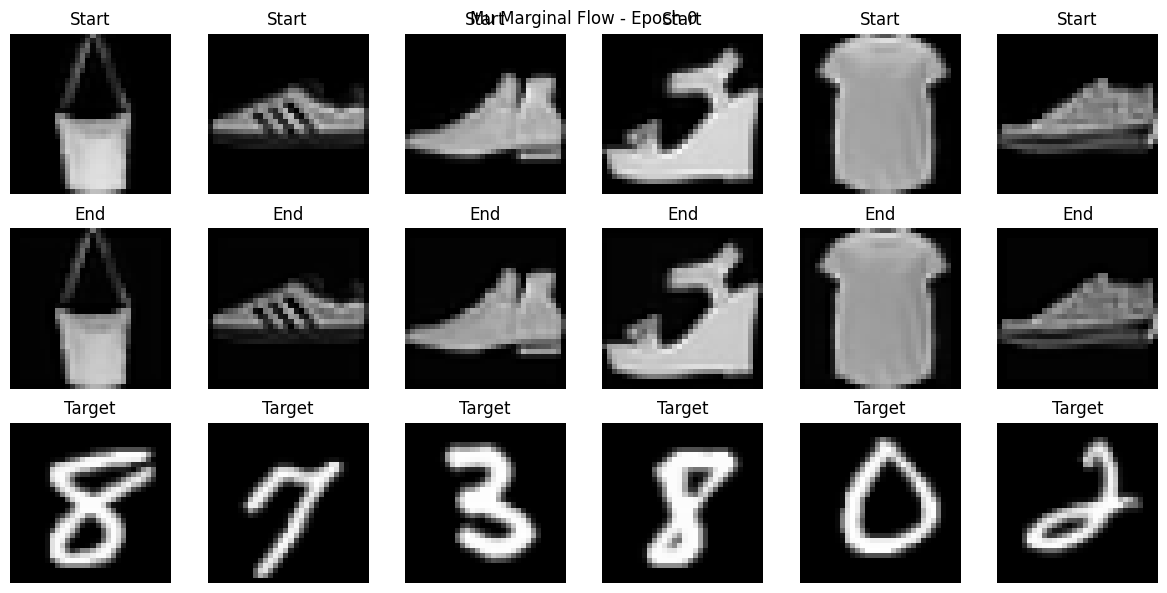

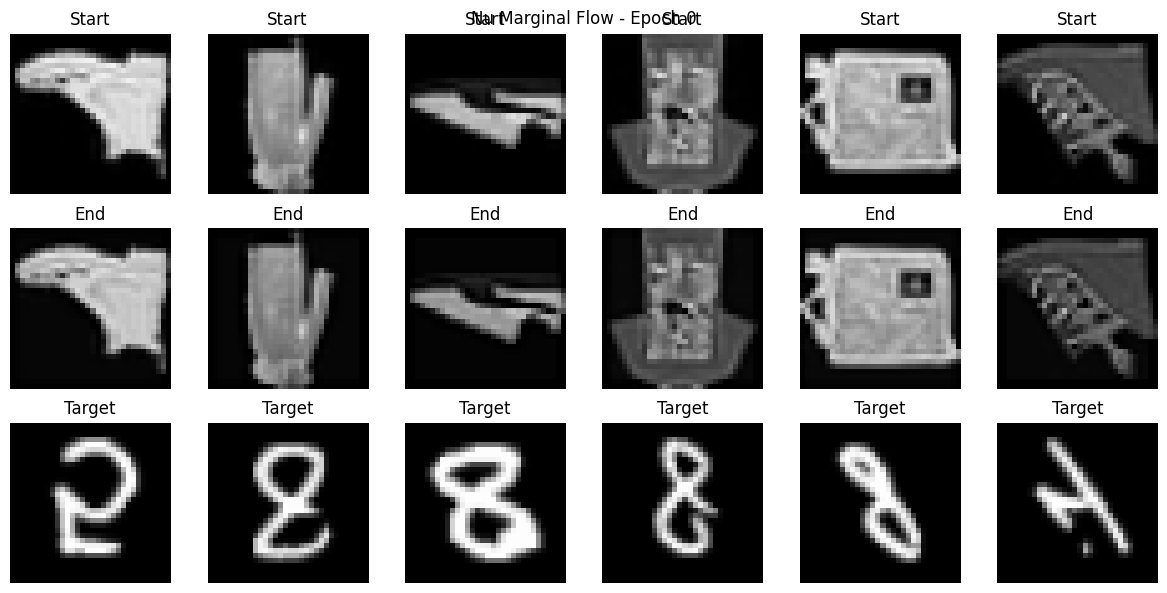

Marginal Flow Matching: 100%|██████████| 50/50 [00:17<00:00,  2.87it/s, Loss mu=0.224, Loss nu=0.243]


Initial marginal flow models saved.


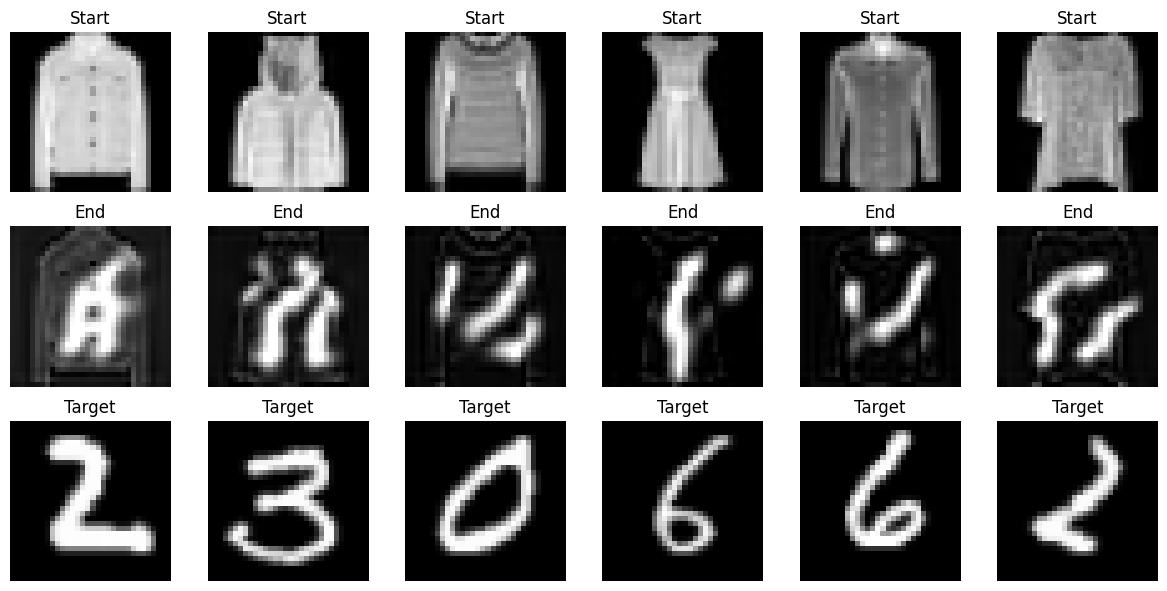

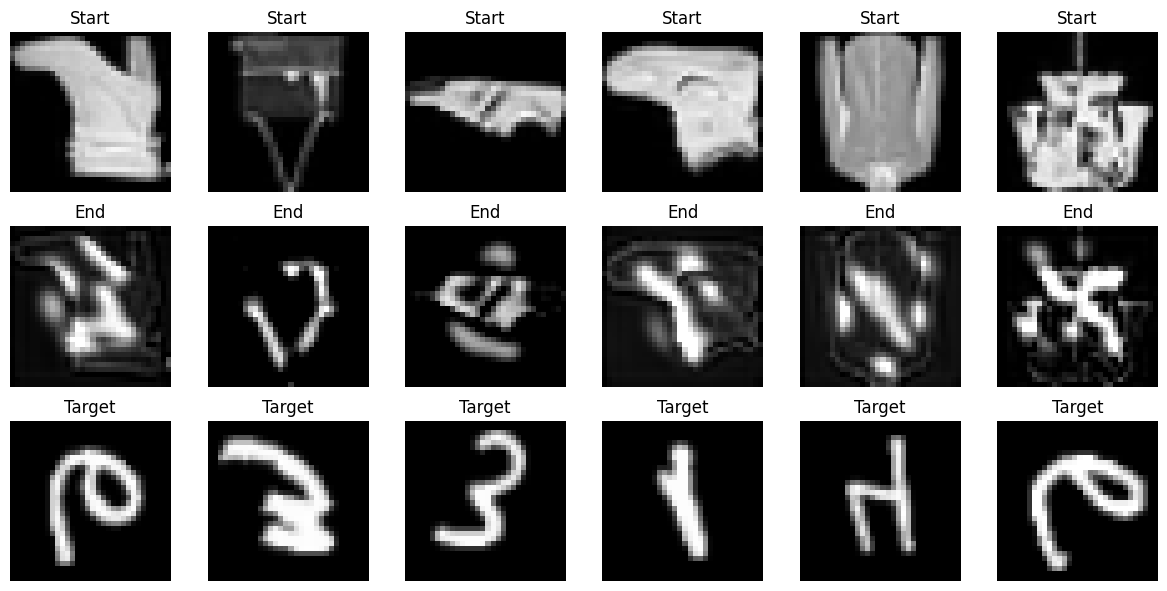

Pretraining bidirectional flows.


Pretraining:   0%|          | 0/50 [00:00<?, ?it/s, Pretrain Loss=0.149]

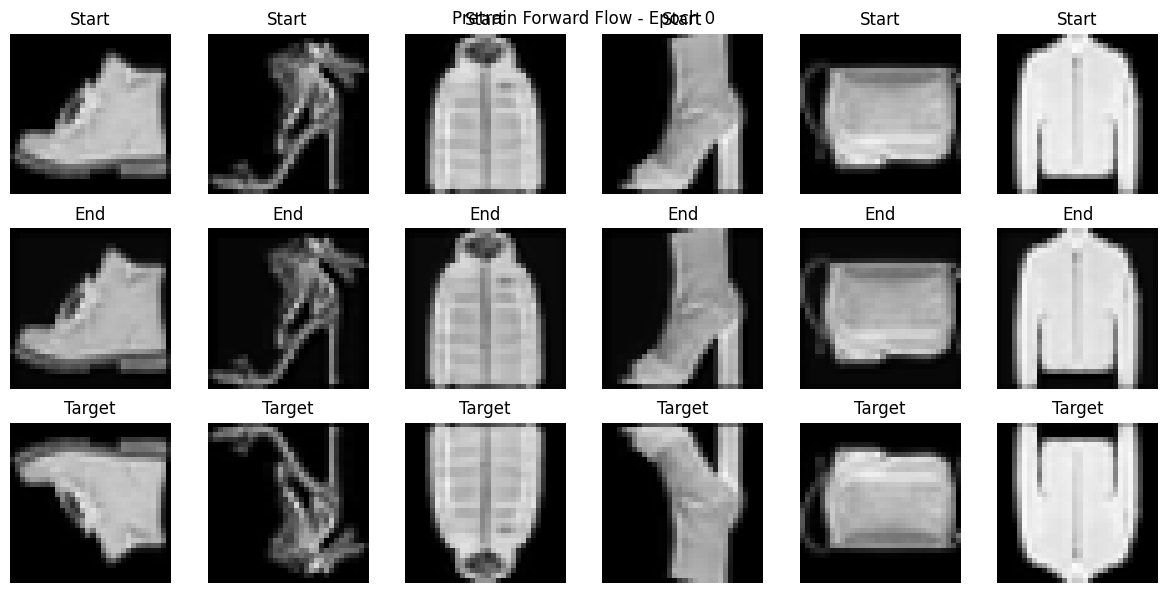

Pretraining:   0%|          | 0/50 [00:00<?, ?it/s, Pretrain Loss=0.133]

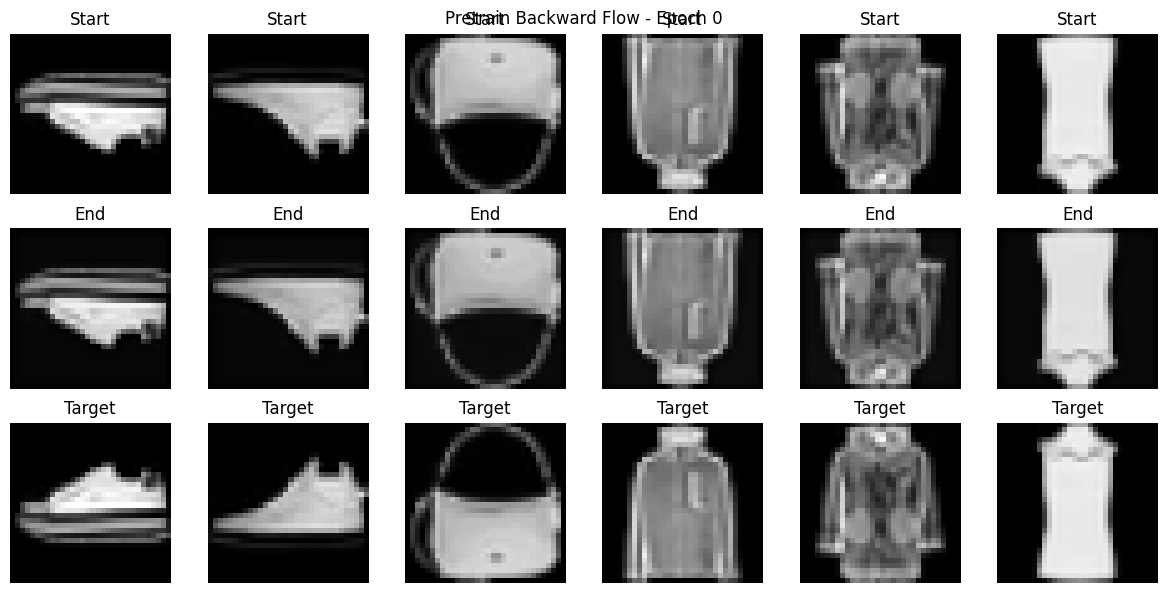

Pretraining: 100%|██████████| 50/50 [00:07<00:00,  6.85it/s, Pretrain Loss=0.0129]


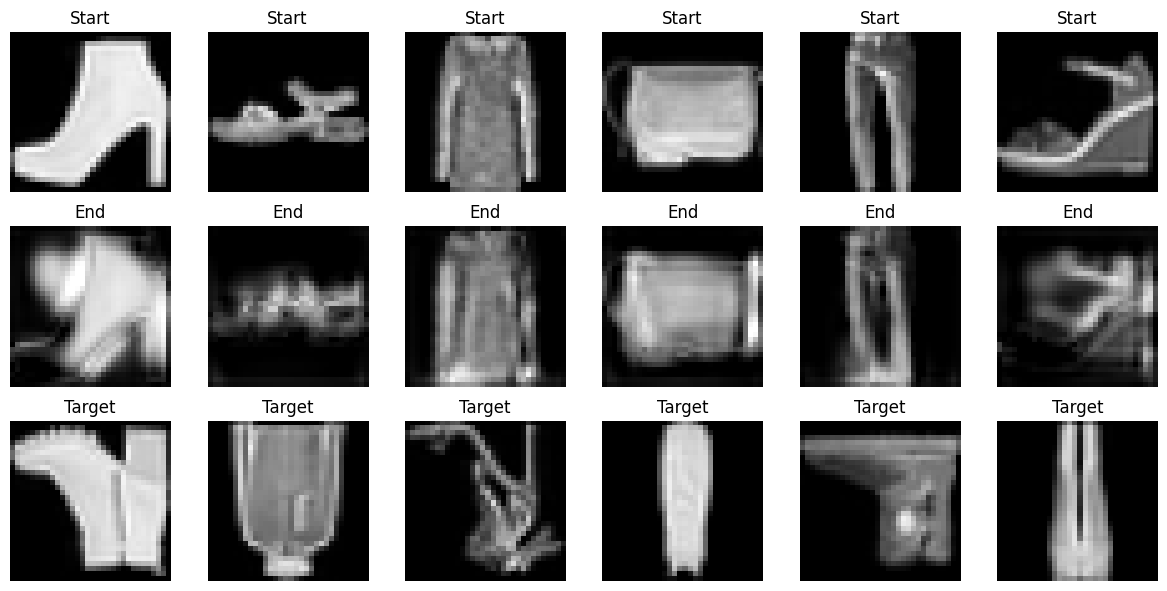

Iteration 1/200


CFM Training: 100%|██████████| 5/5 [00:01<00:00,  4.99it/s, CFM Loss=8.25e-5]


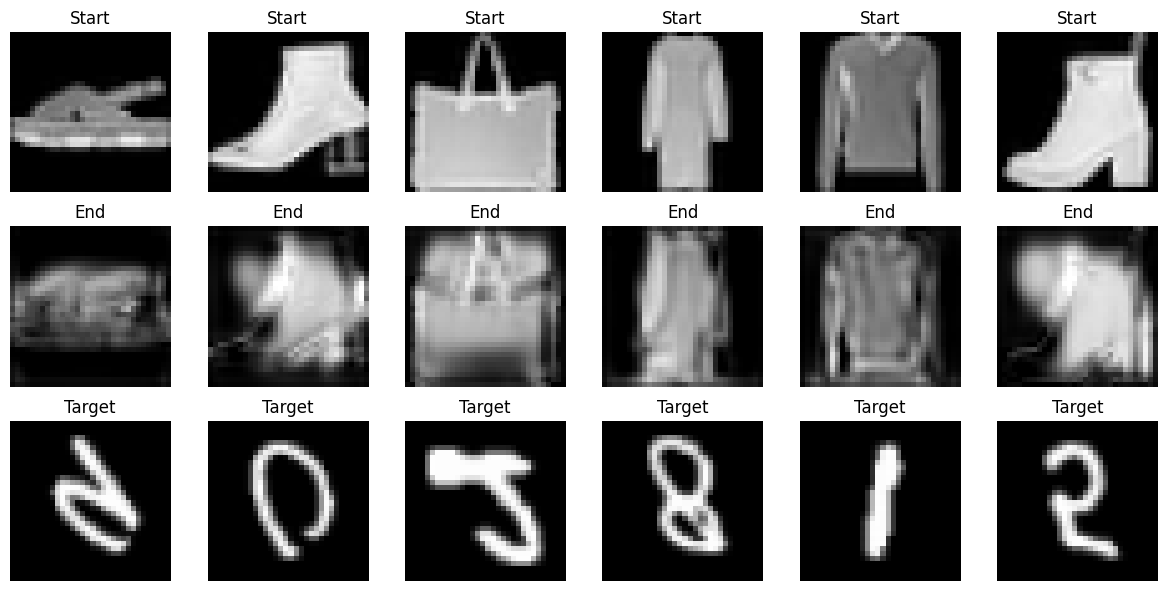

Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.36it/s]


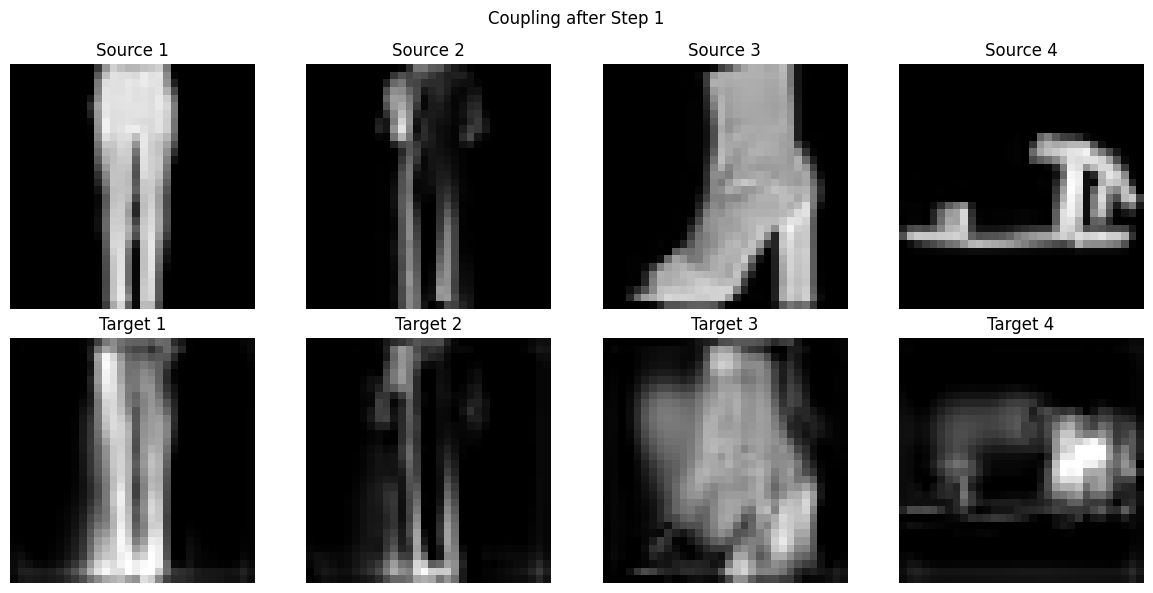

Iteration 2/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.36it/s]


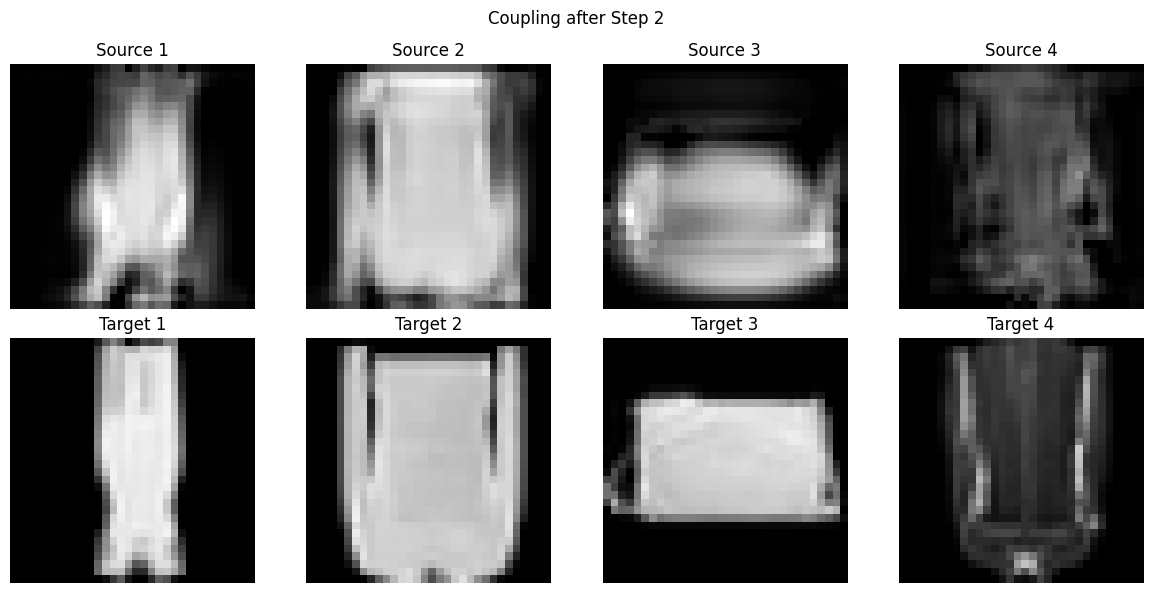

Iteration 3/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.36it/s]


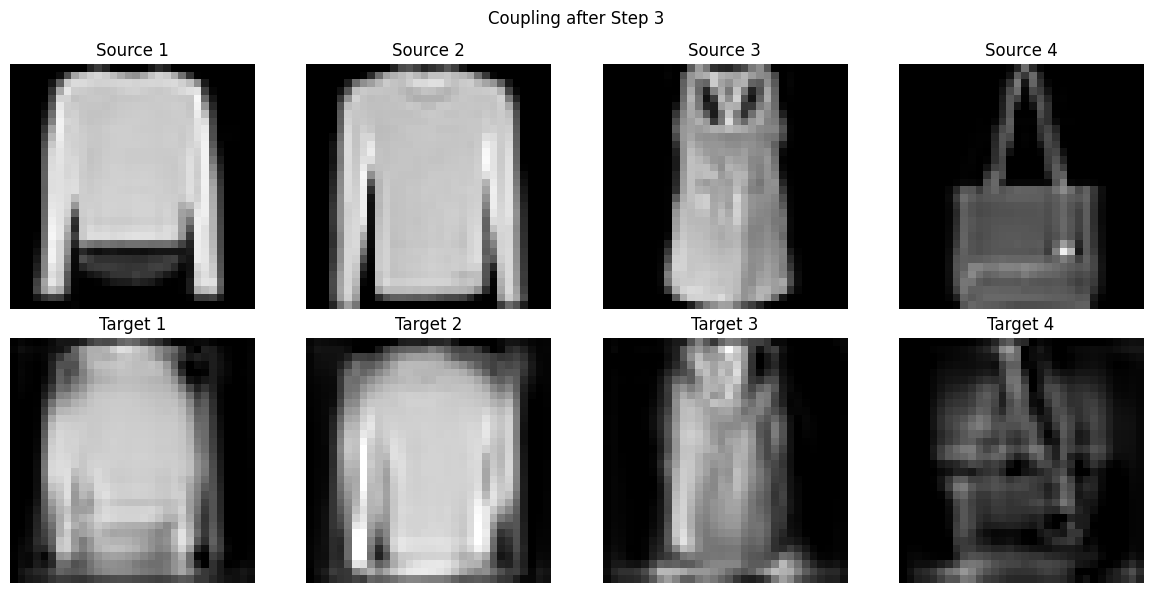

Iteration 4/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.35it/s]


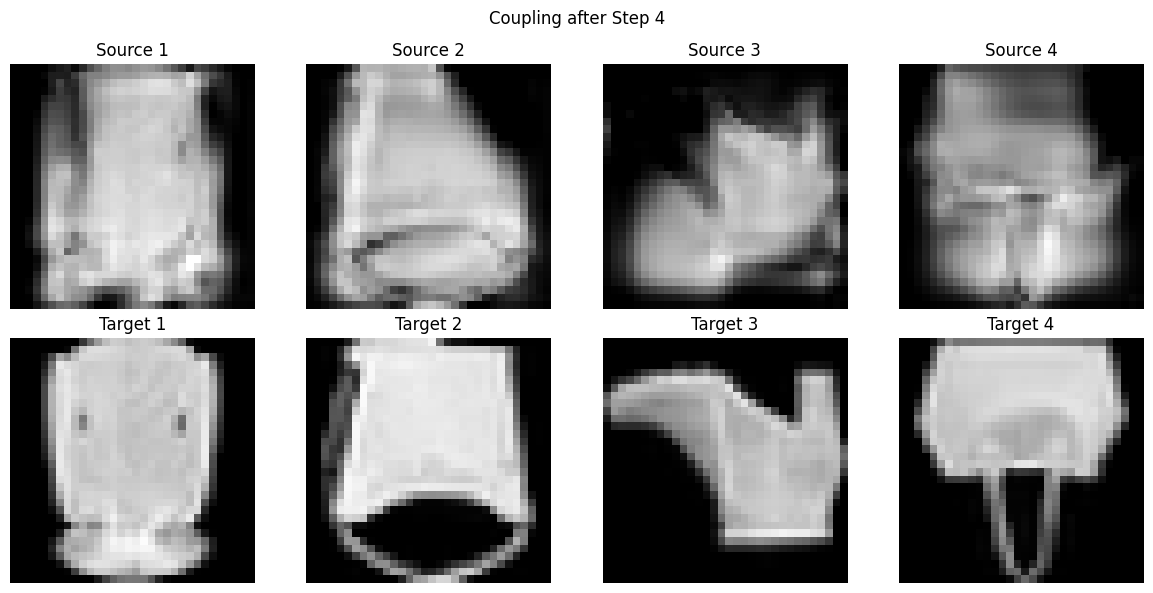

Iteration 5/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.33it/s]


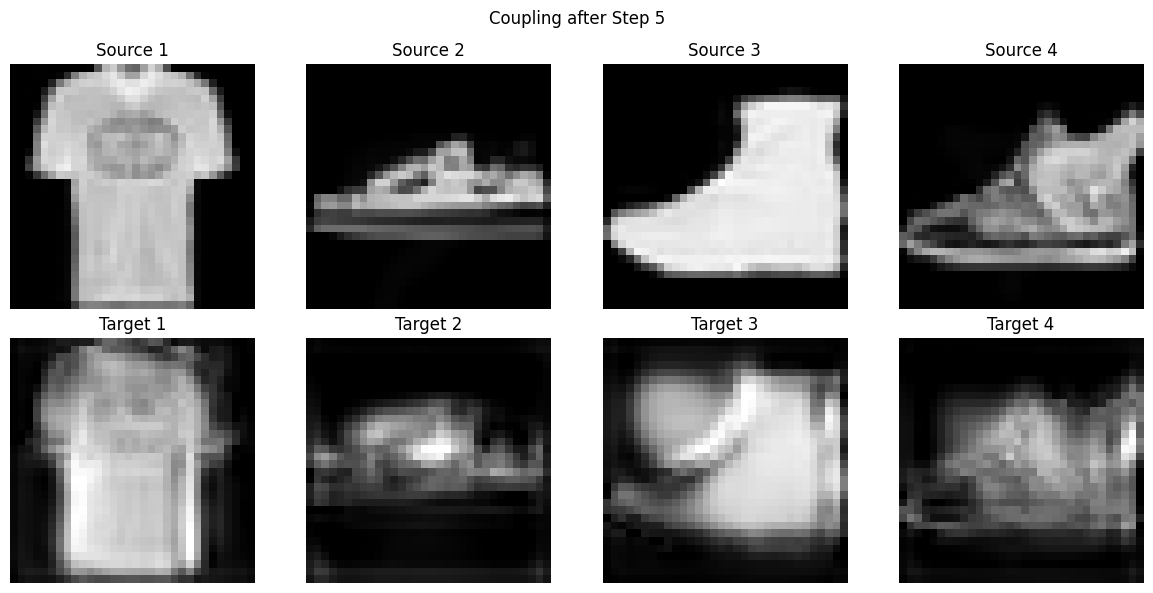

Iteration 6/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.29it/s]


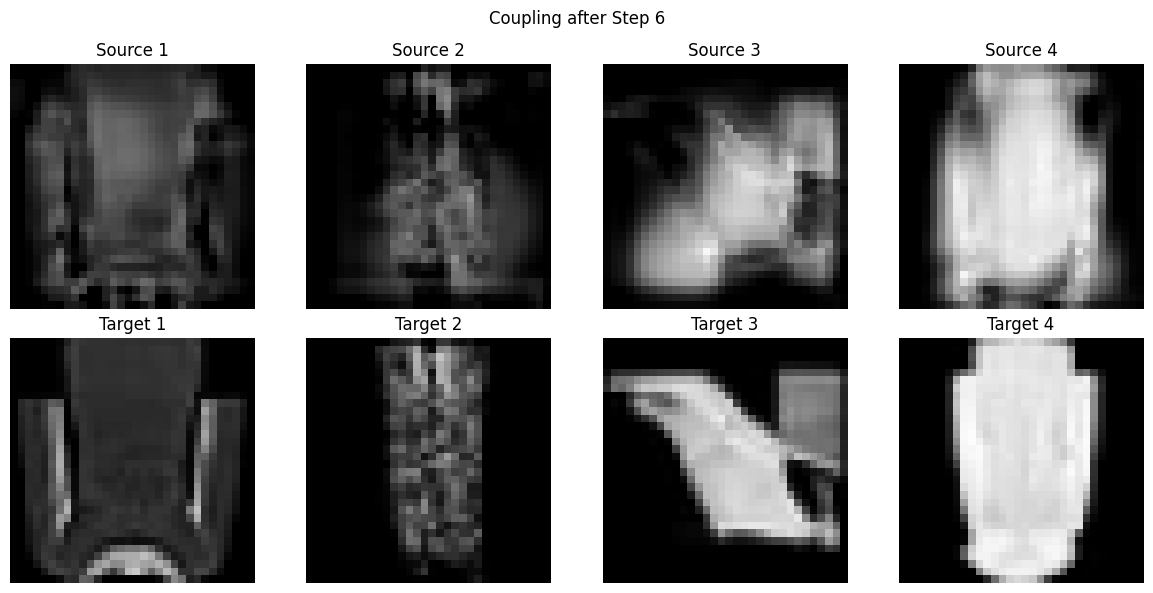

Iteration 7/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.32it/s]


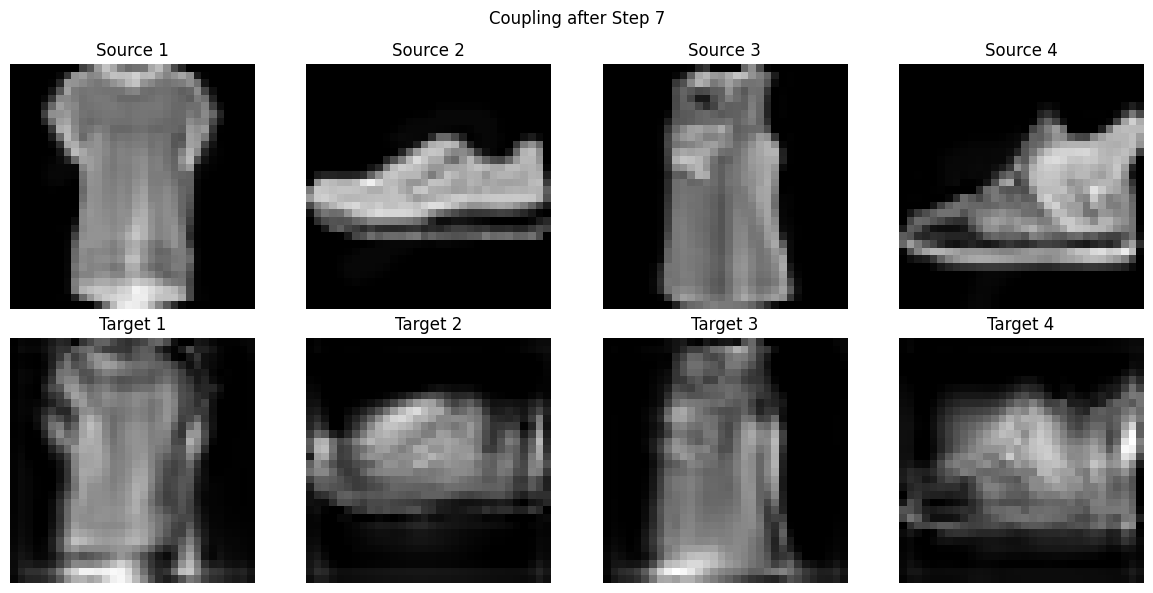

Iteration 8/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.32it/s]


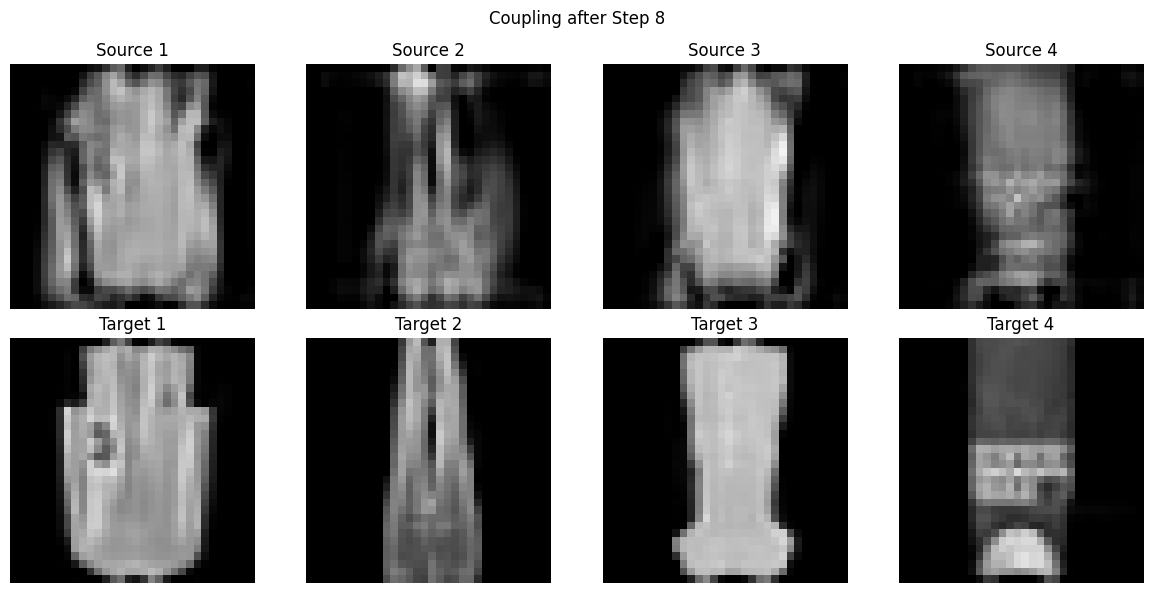

Iteration 9/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.36it/s]


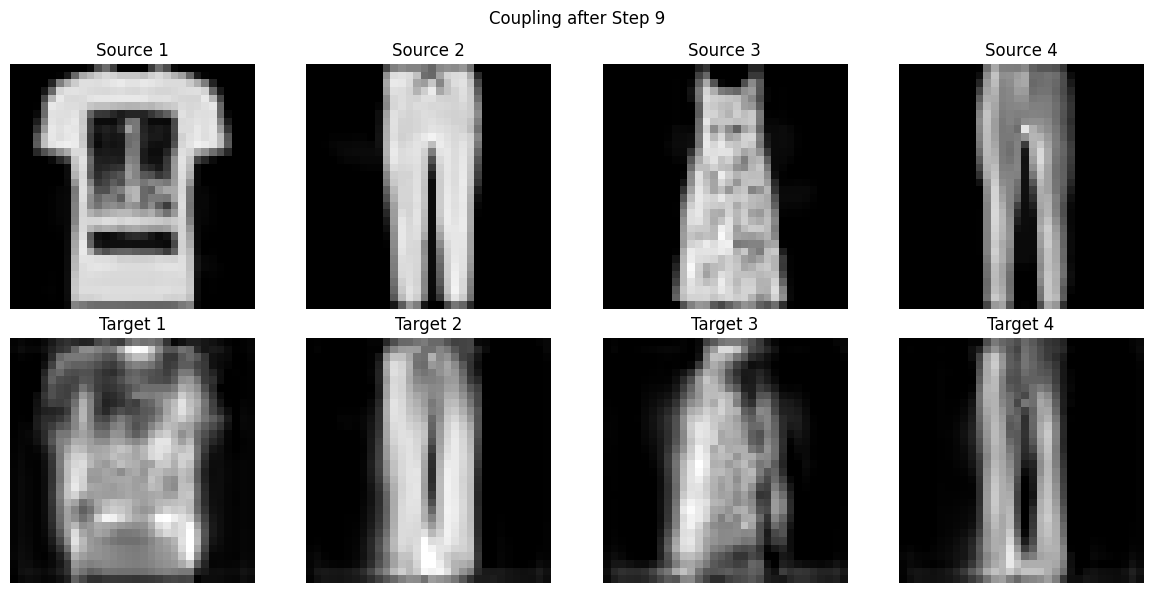

Iteration 10/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.36it/s]


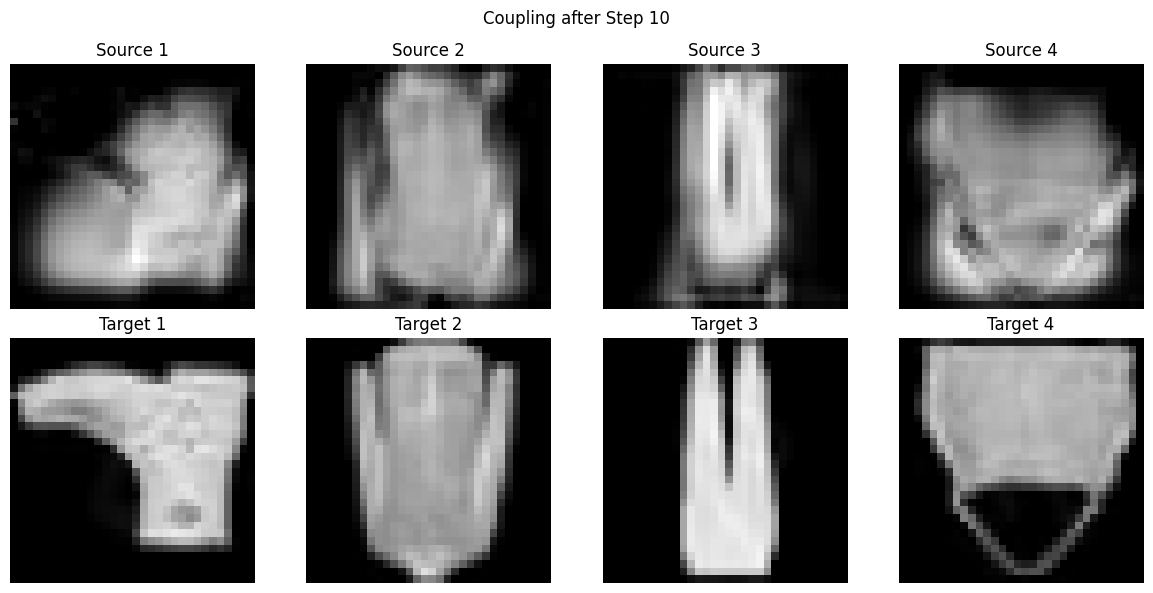

Iteration 11/200


CFM Training: 100%|██████████| 5/5 [00:01<00:00,  4.99it/s, CFM Loss=4.04e-7]


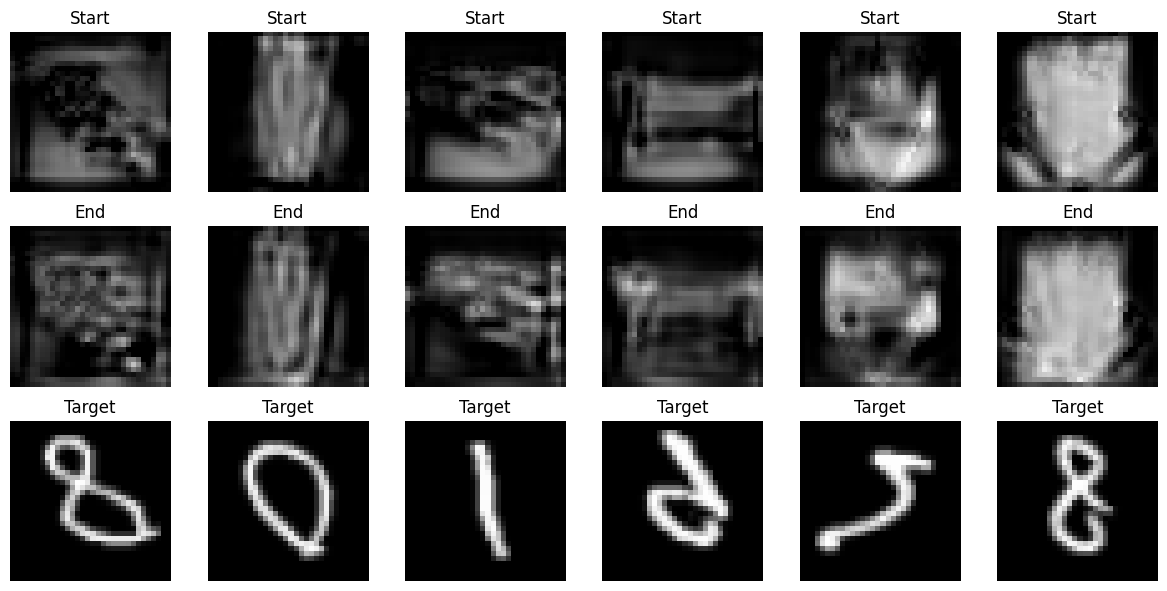

Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.35it/s]


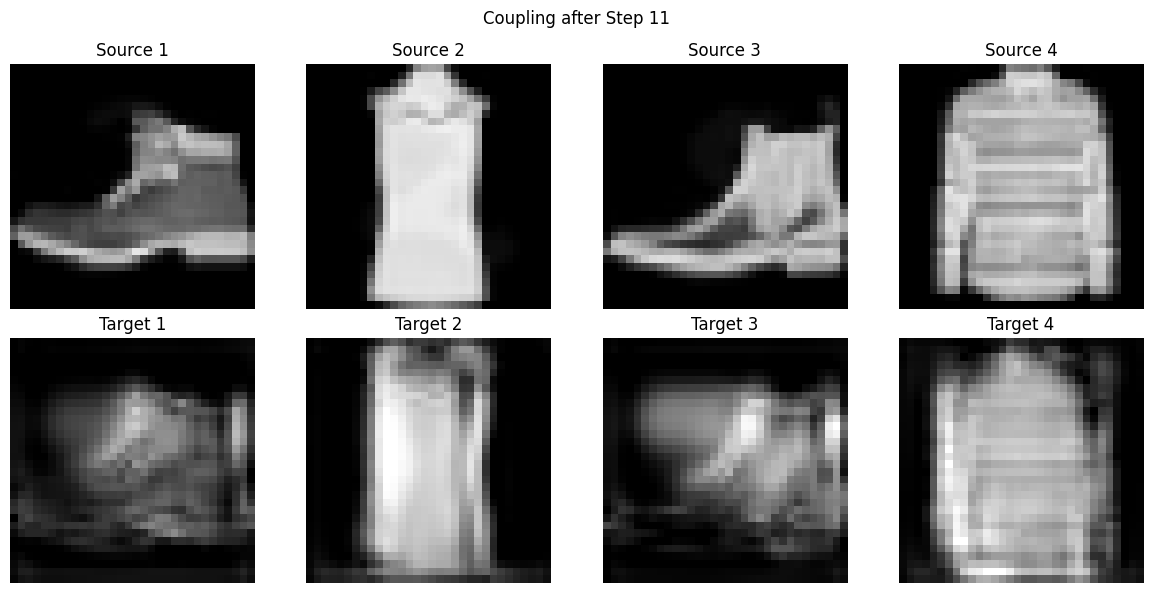

Iteration 12/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.36it/s]


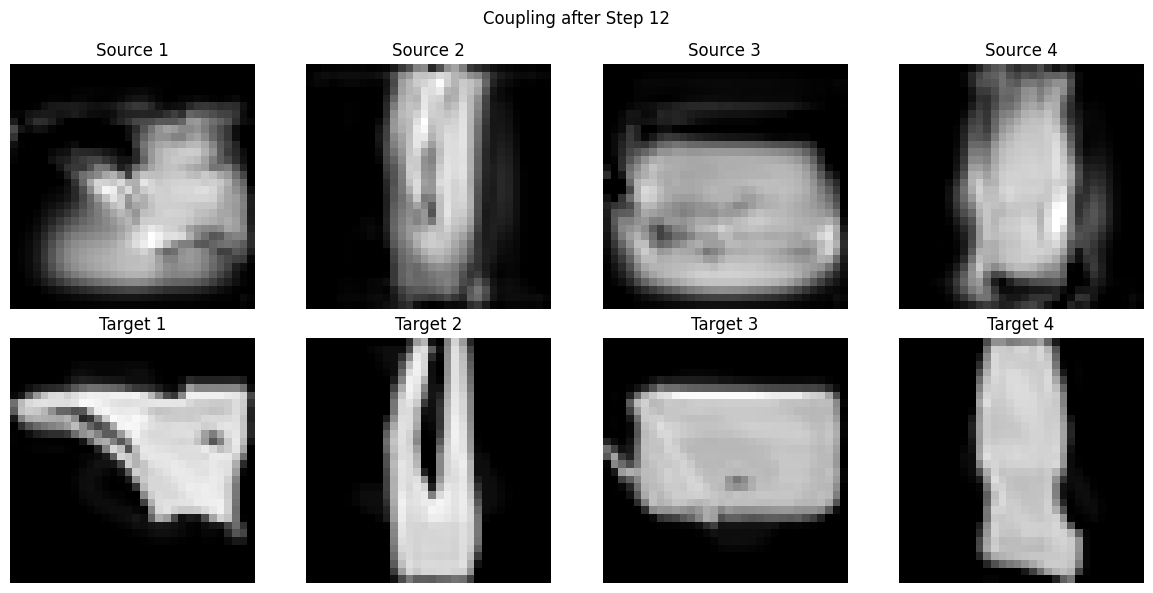

Iteration 13/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.36it/s]


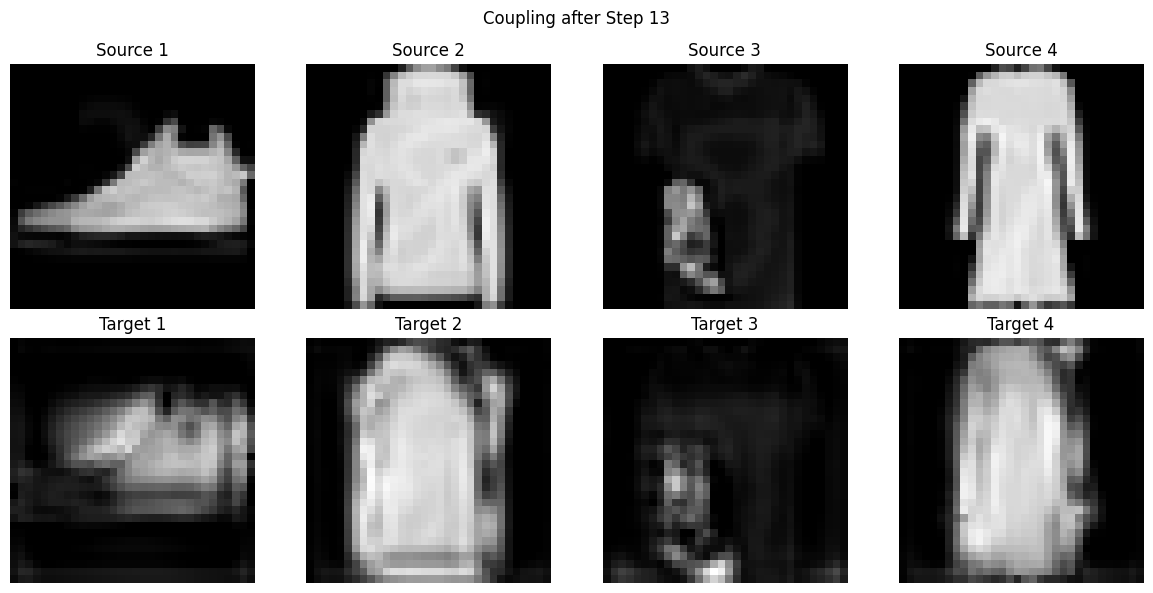

Iteration 14/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.35it/s]


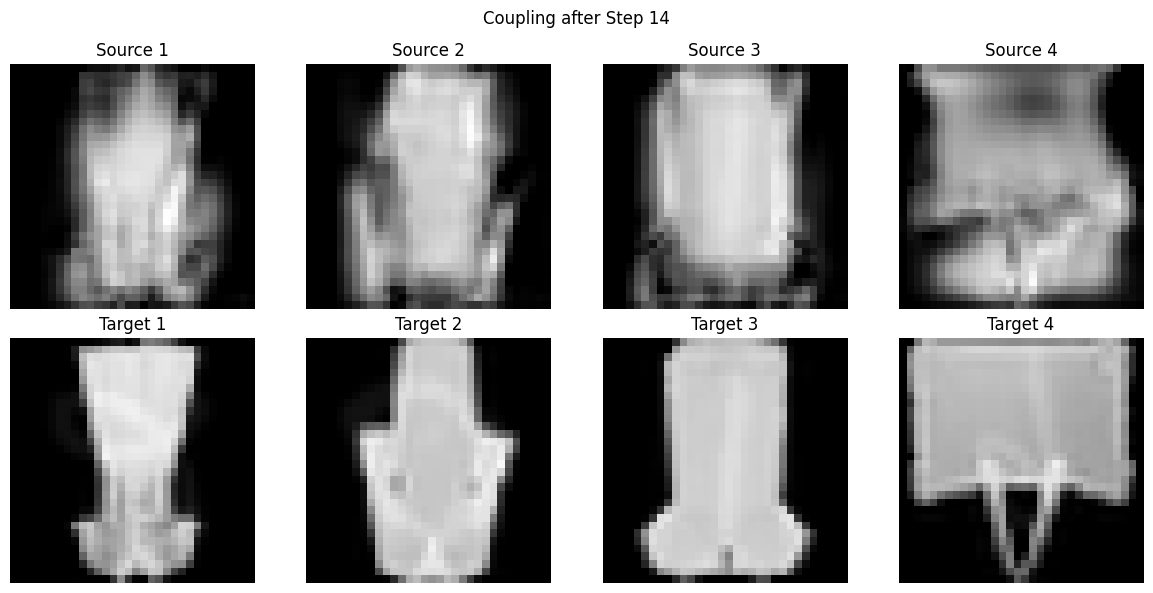

Iteration 15/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.37it/s]


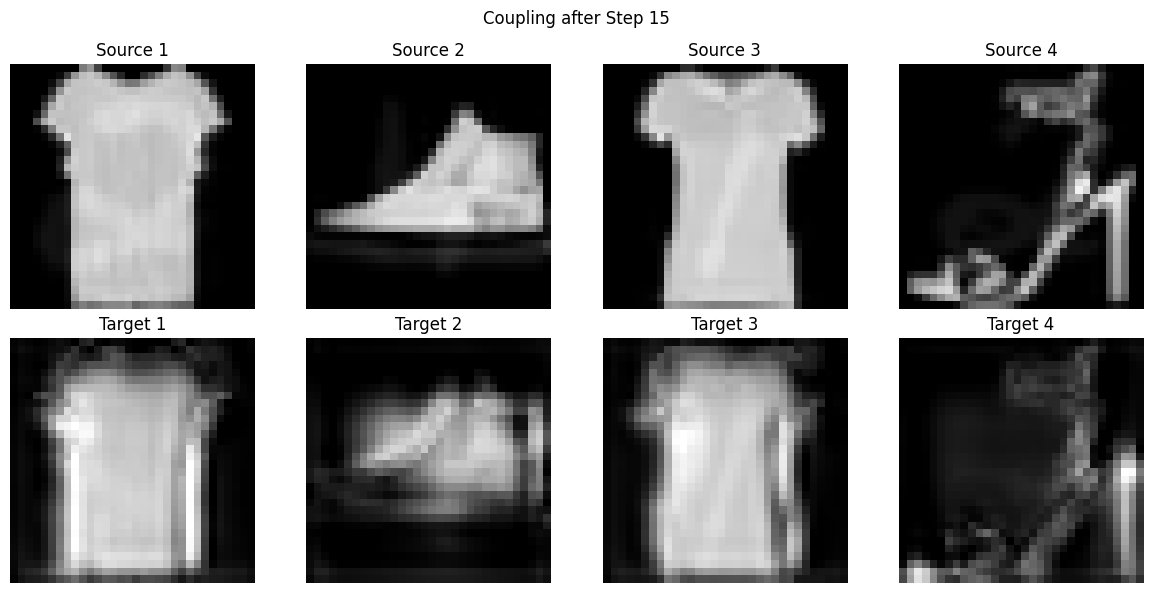

Iteration 16/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.36it/s]


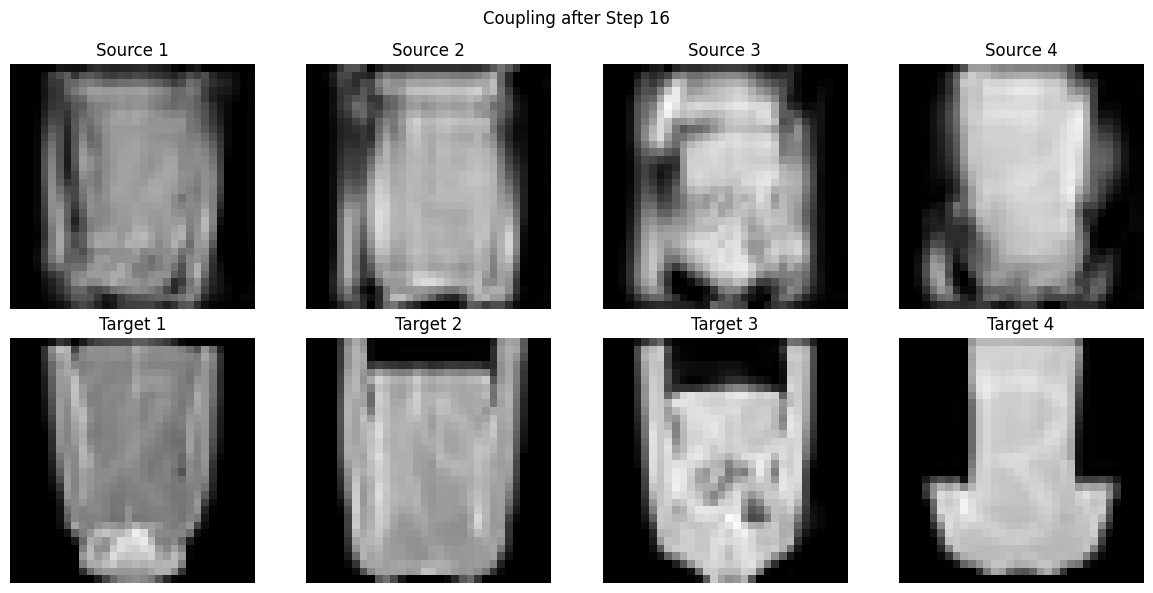

Iteration 17/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.32it/s]


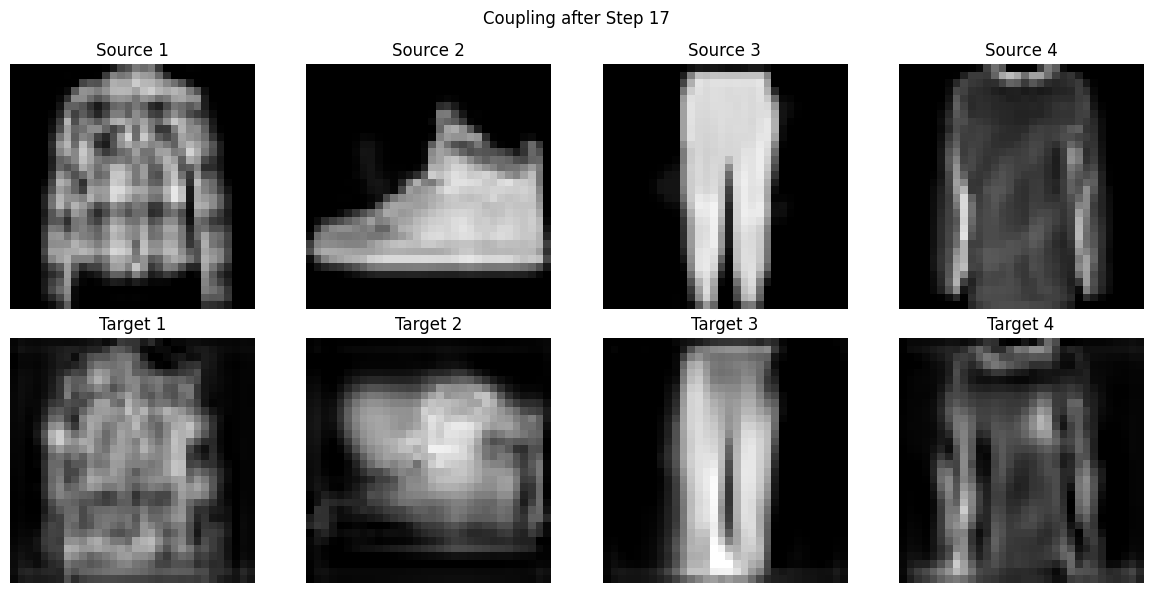

Iteration 18/200


Advancing coupling: 100%|██████████| 8/8 [00:04<00:00,  1.83it/s]


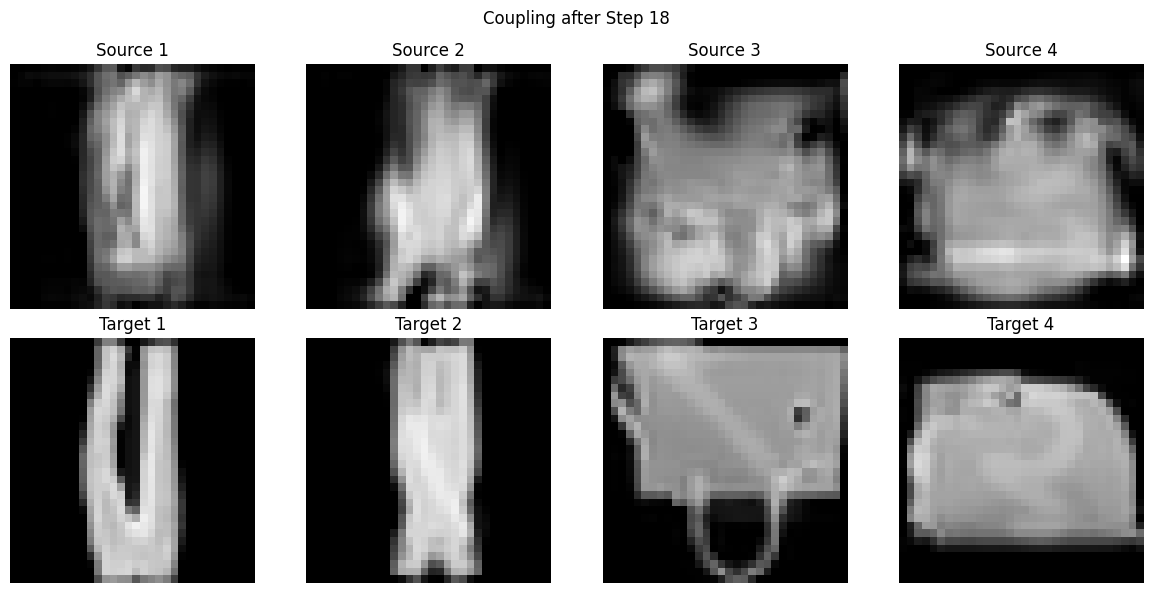

Iteration 19/200


Advancing coupling: 100%|██████████| 8/8 [00:04<00:00,  1.84it/s]


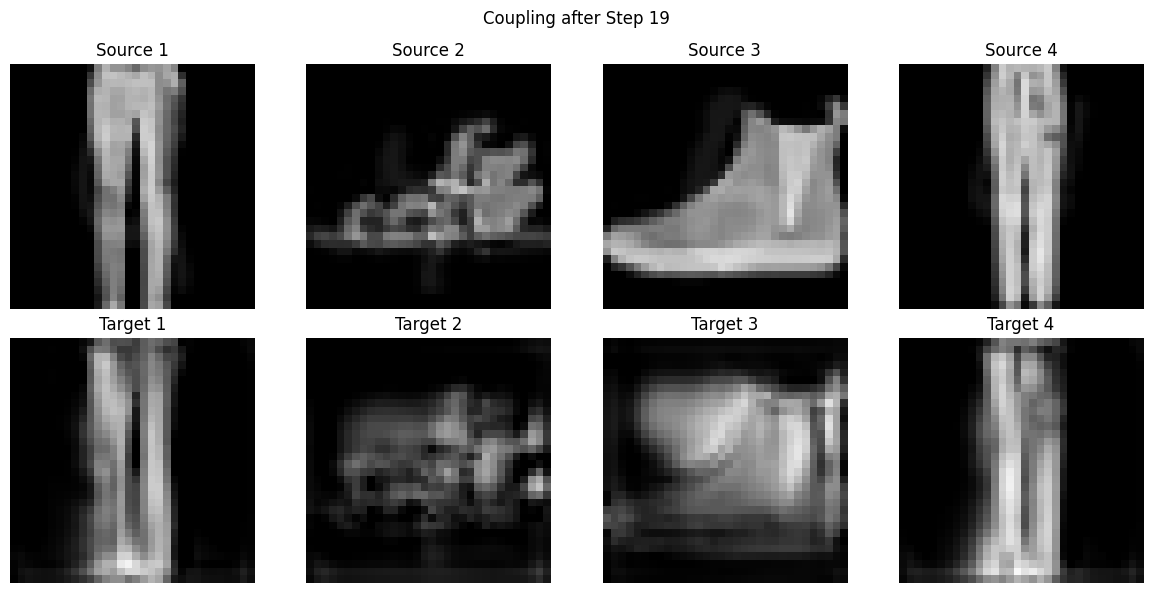

Iteration 20/200


Advancing coupling: 100%|██████████| 8/8 [00:04<00:00,  1.83it/s]


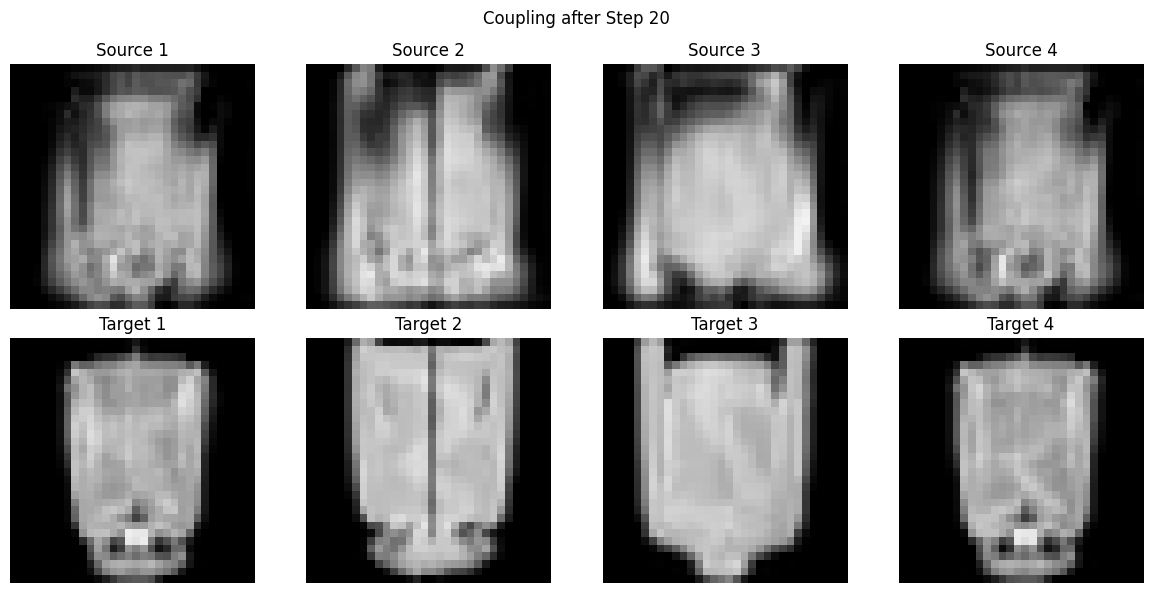

Iteration 21/200


CFM Training: 100%|██████████| 5/5 [00:01<00:00,  3.82it/s, CFM Loss=1.37e-8]


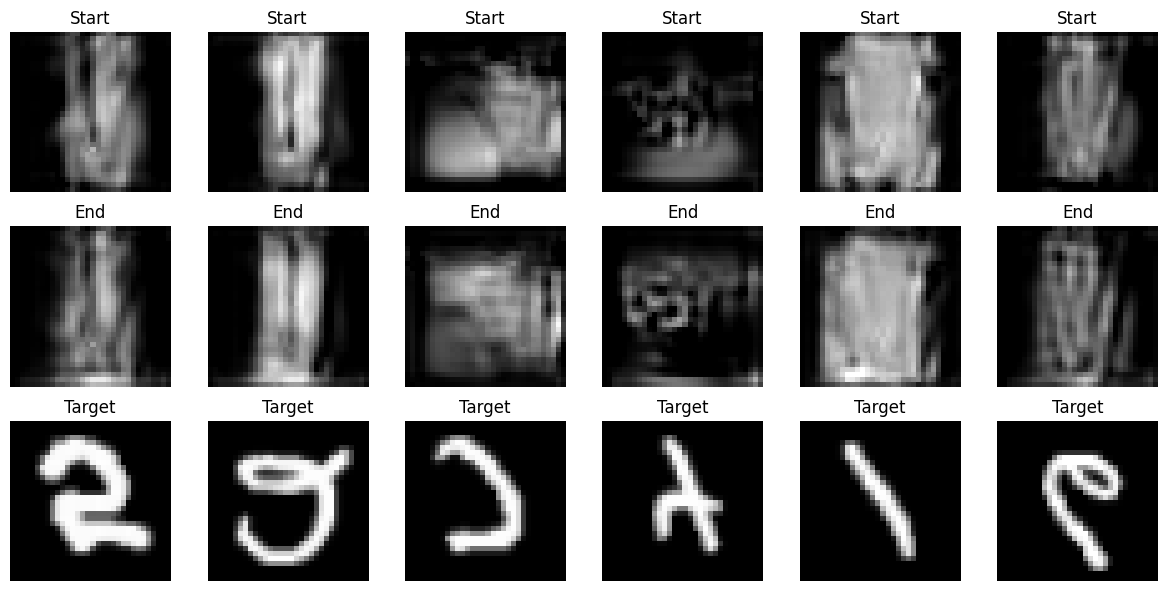

Advancing coupling: 100%|██████████| 8/8 [00:04<00:00,  1.83it/s]


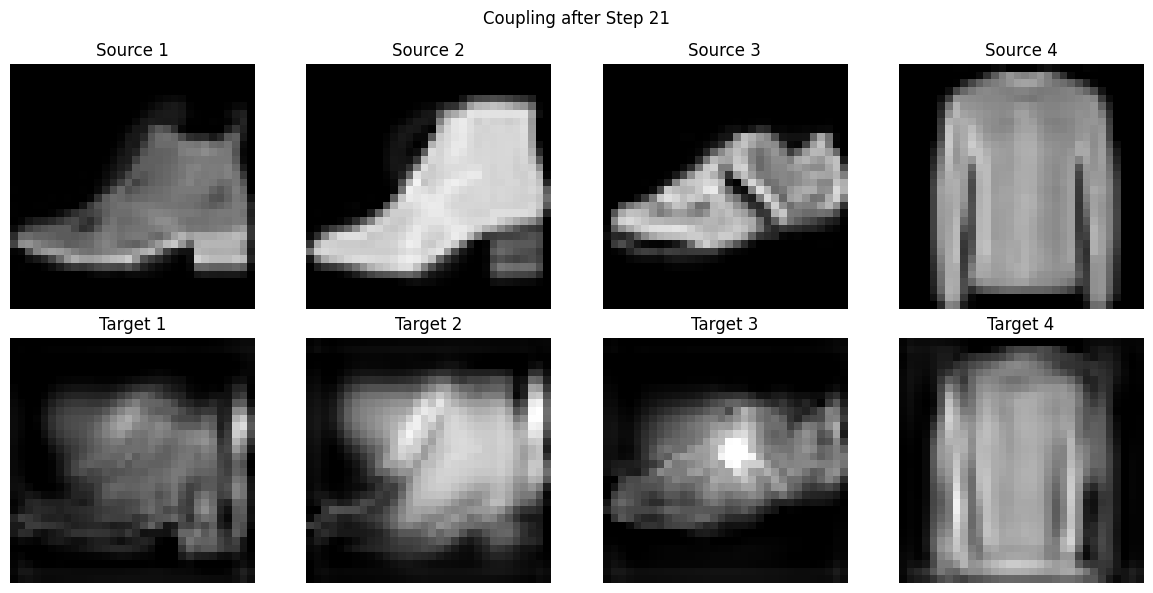

Iteration 22/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.34it/s]


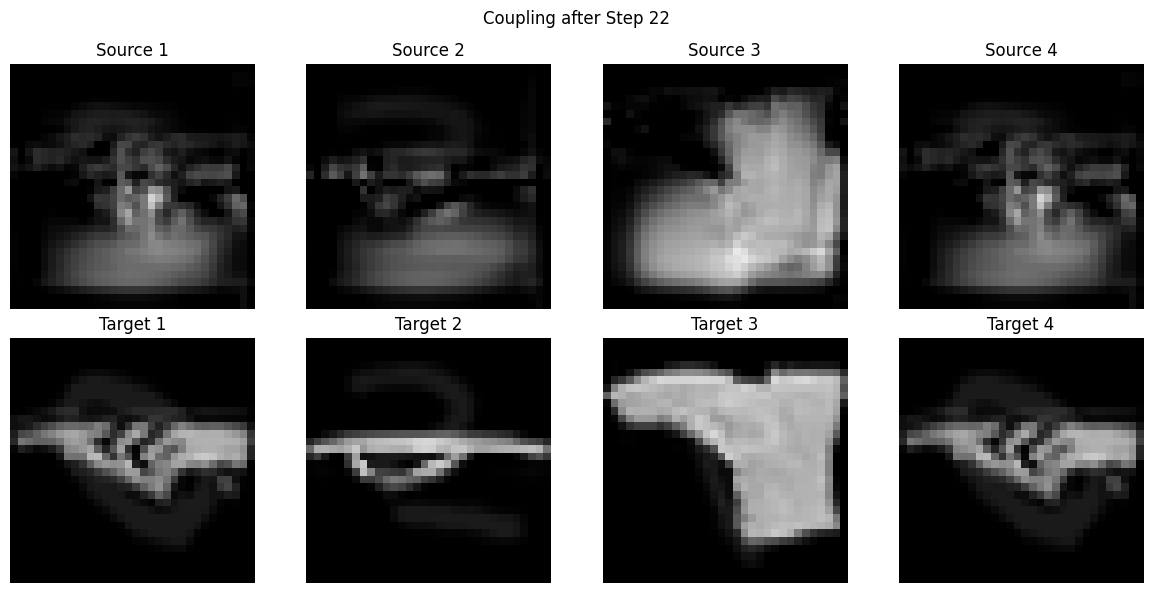

Iteration 23/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.35it/s]


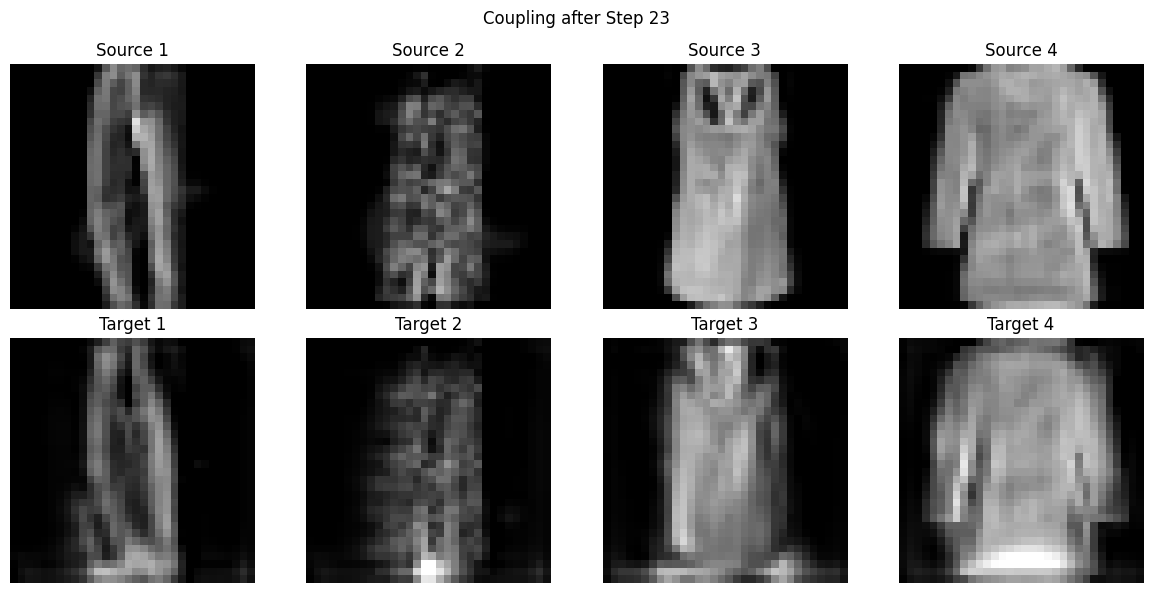

Iteration 24/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.35it/s]


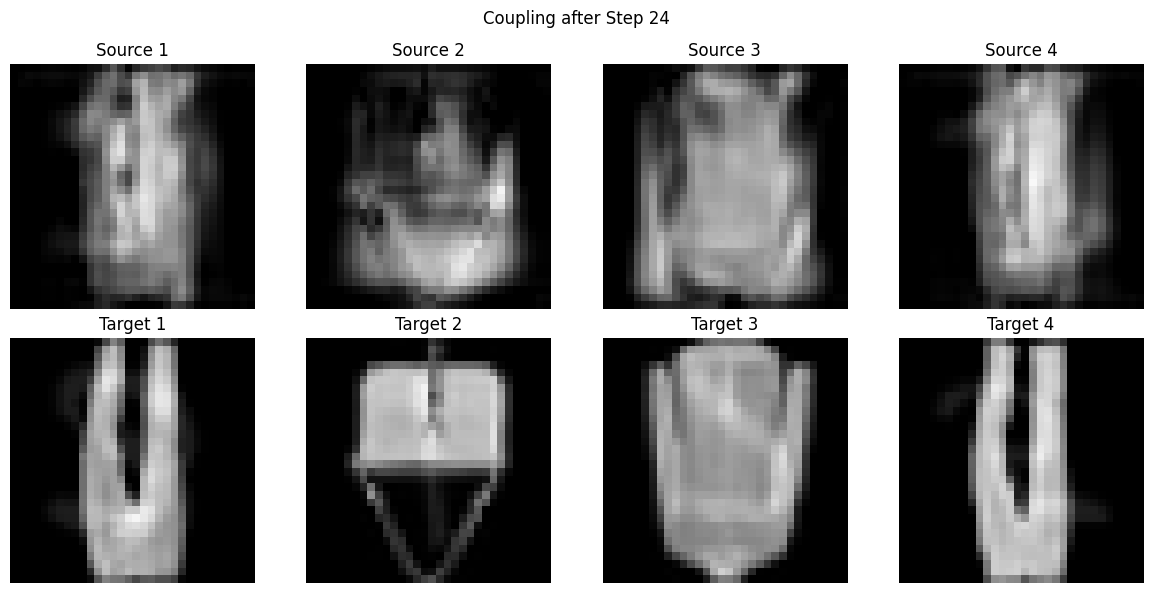

Iteration 25/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.34it/s]


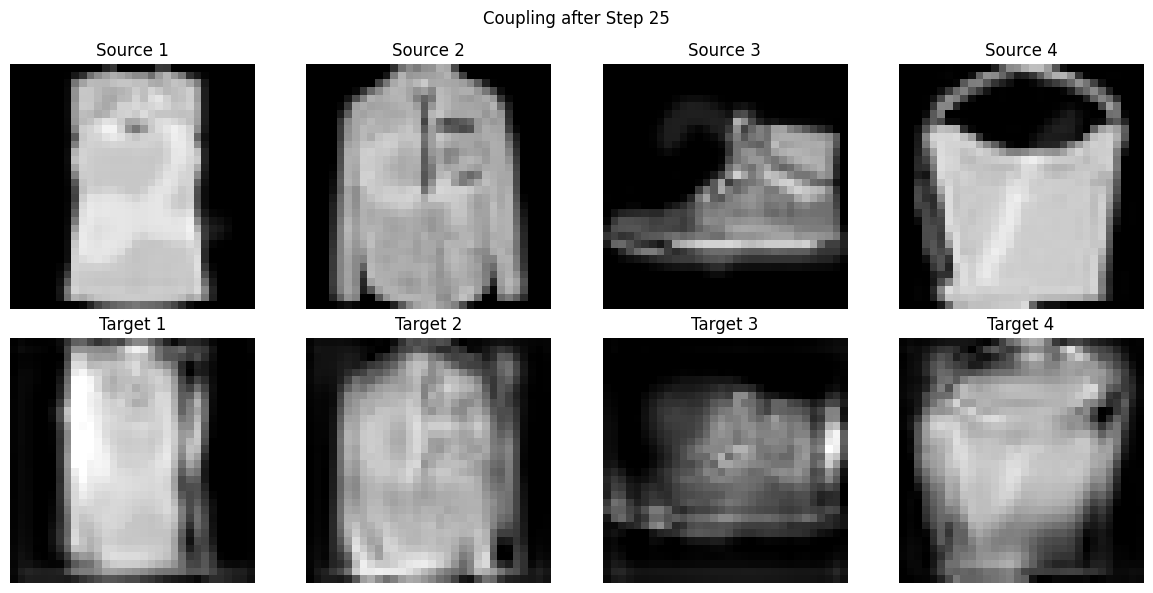

Iteration 26/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.34it/s]


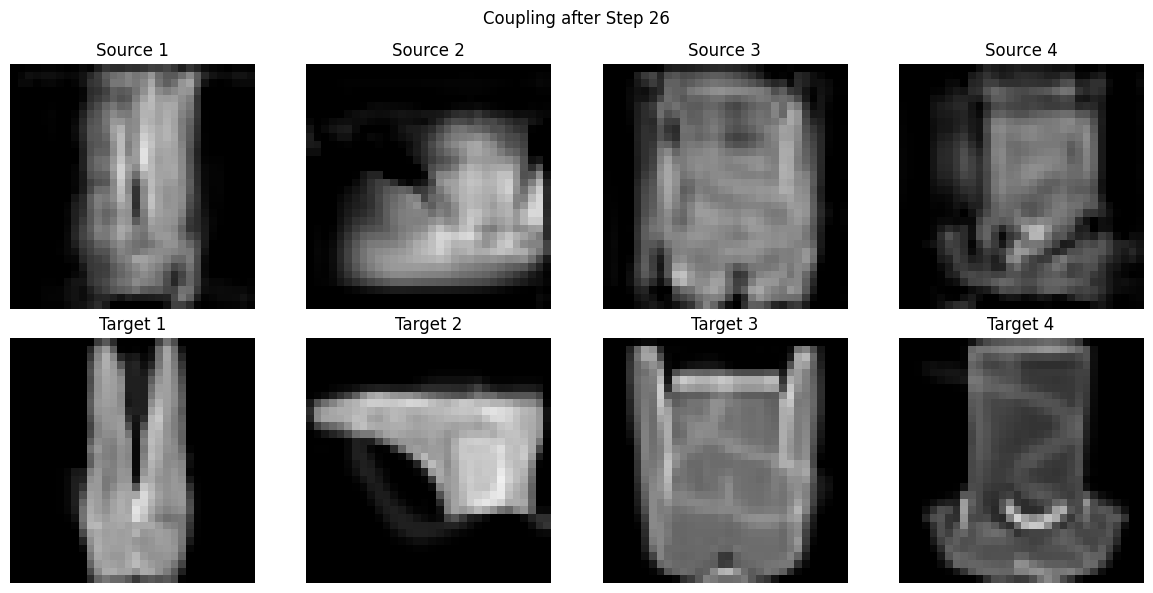

Iteration 27/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.35it/s]


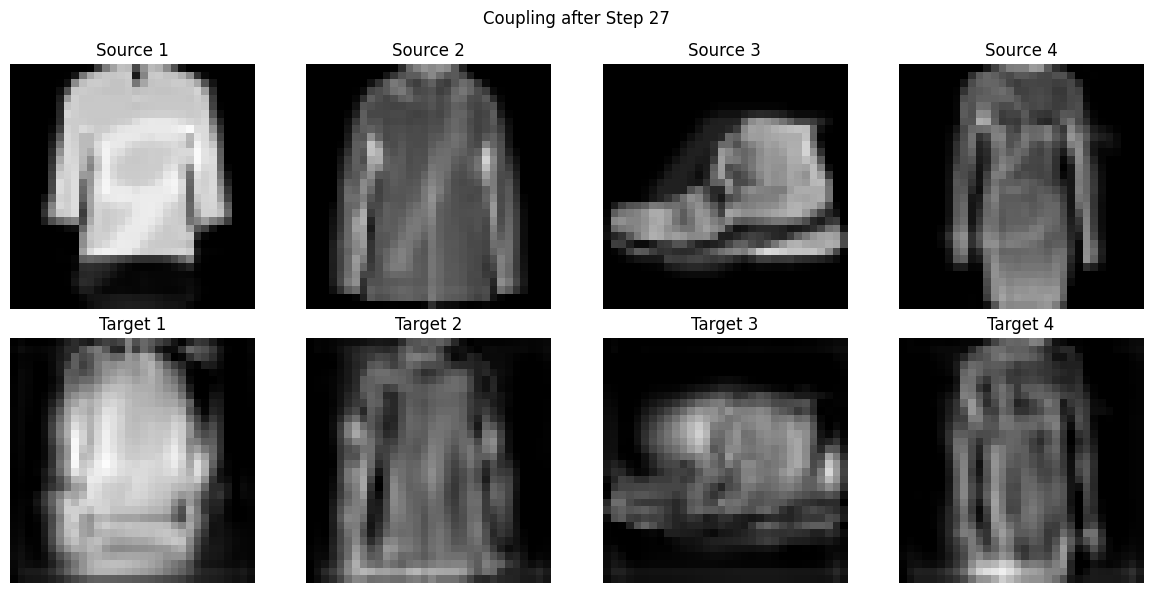

Iteration 28/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.35it/s]


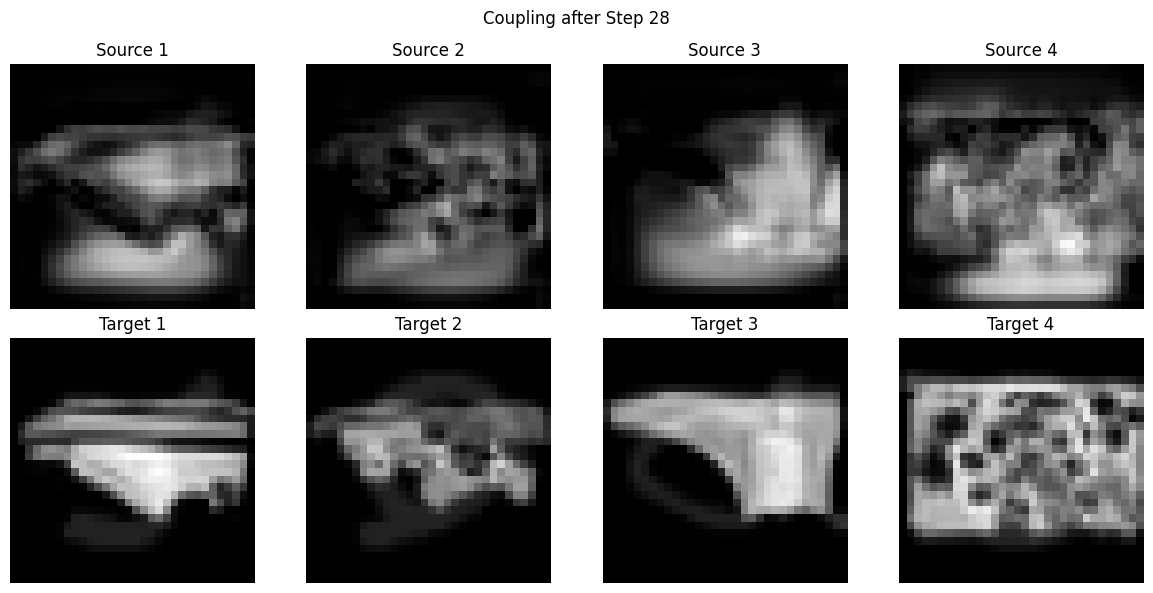

Iteration 29/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.35it/s]


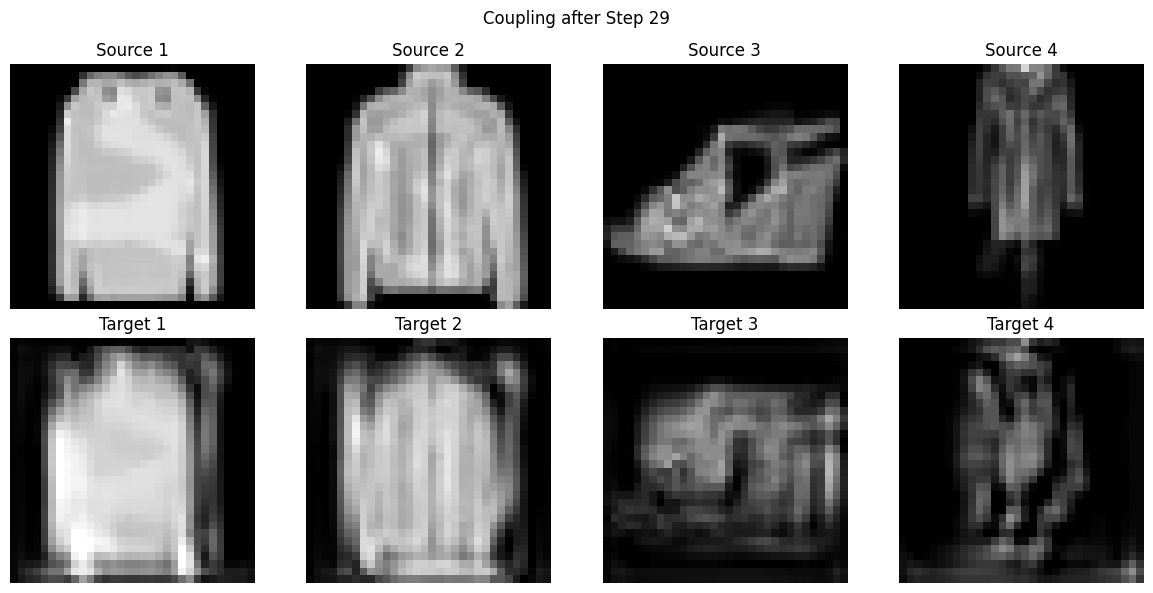

Iteration 30/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.34it/s]


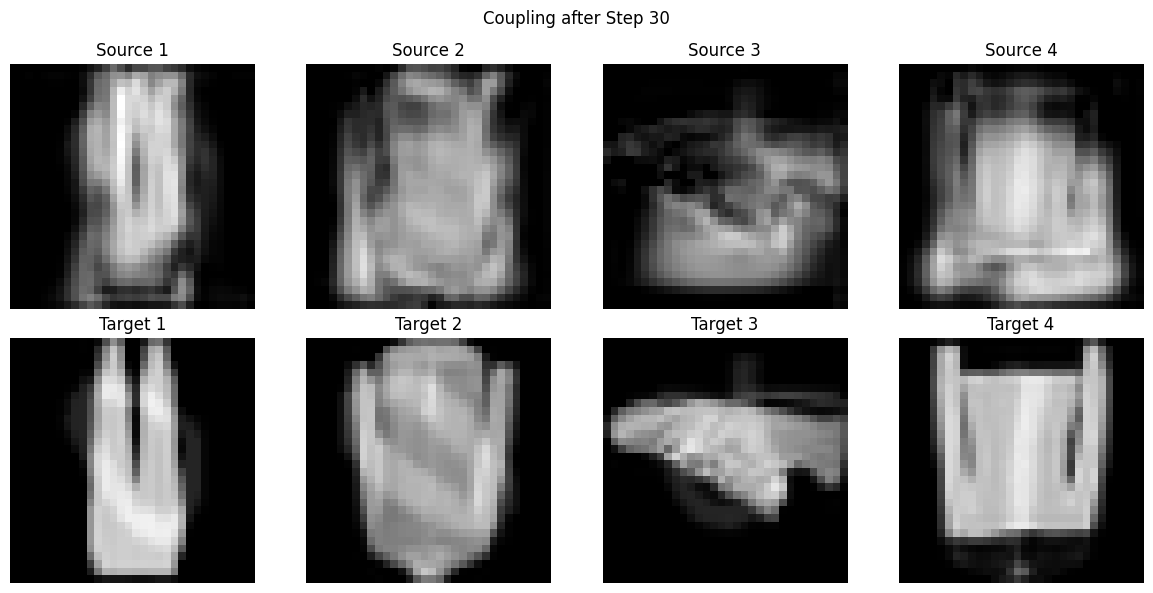

Iteration 31/200


CFM Training: 100%|██████████| 5/5 [00:00<00:00,  5.01it/s, CFM Loss=4.22e-9]


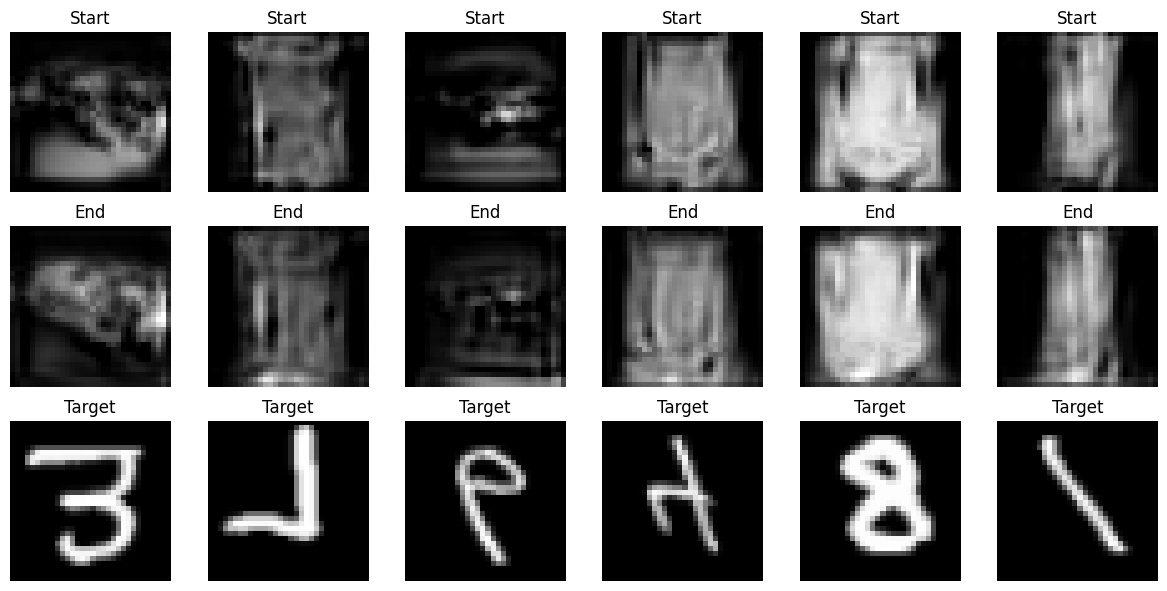

Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.35it/s]


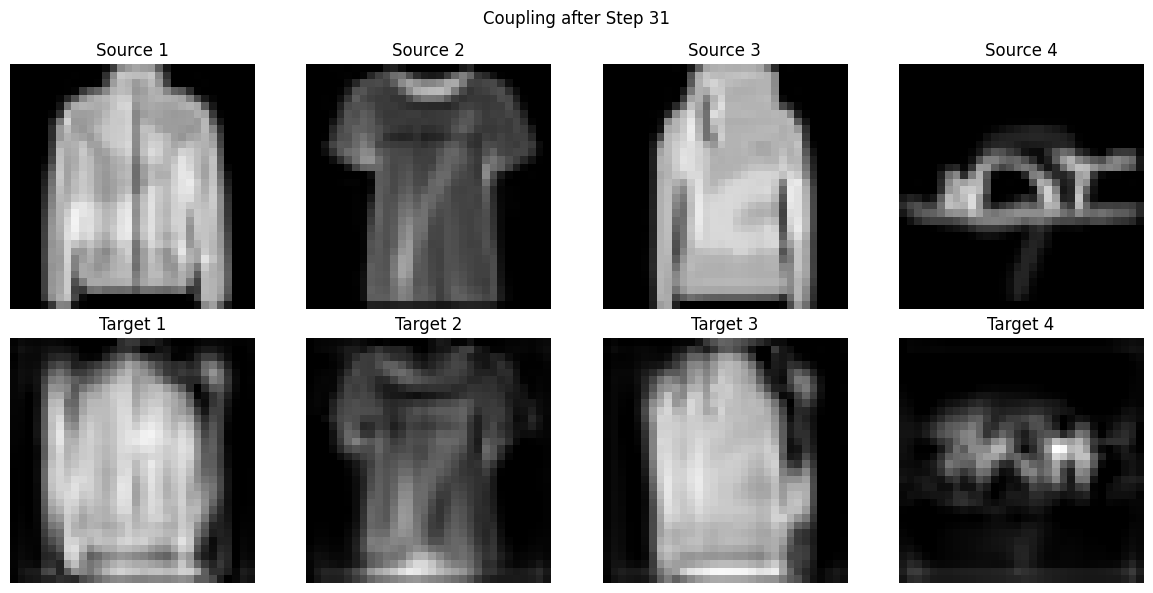

Iteration 32/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.35it/s]


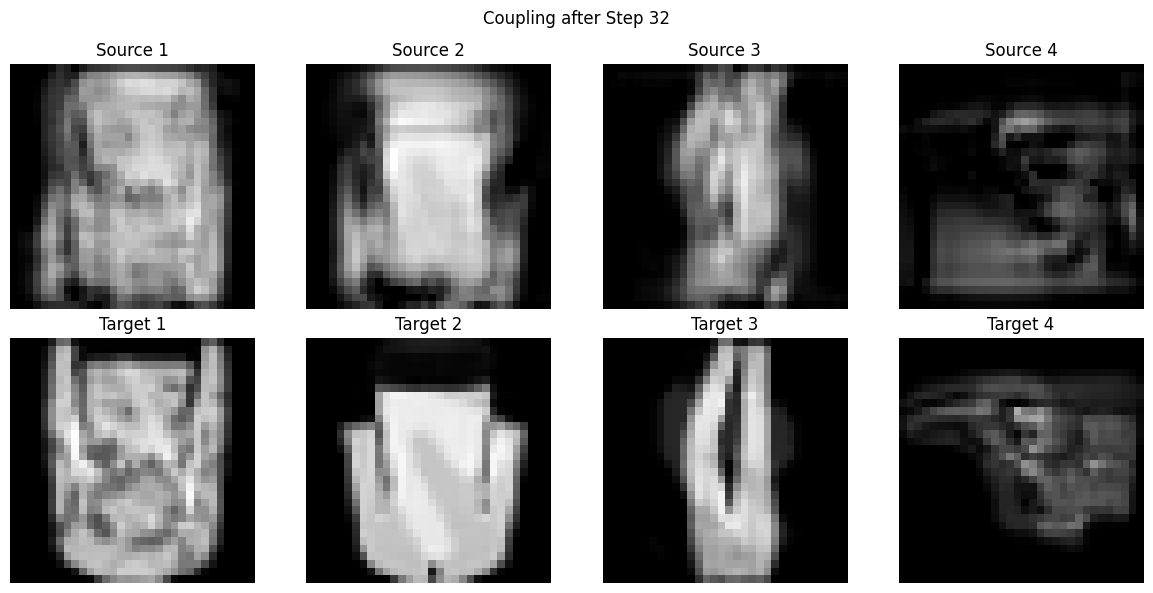

Iteration 33/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.35it/s]


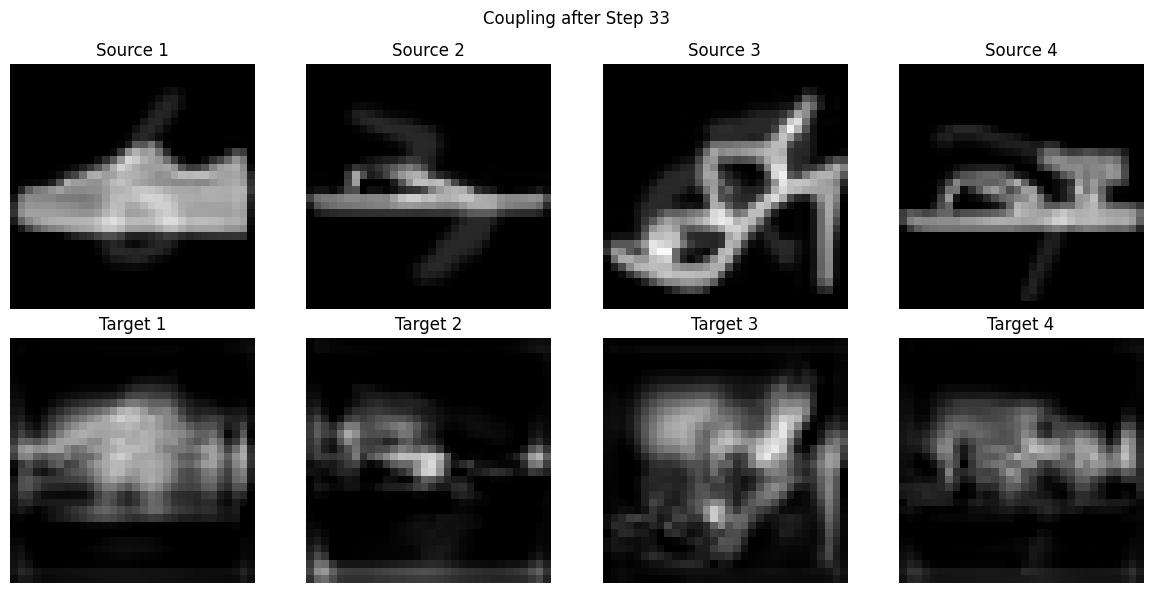

Iteration 34/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.35it/s]


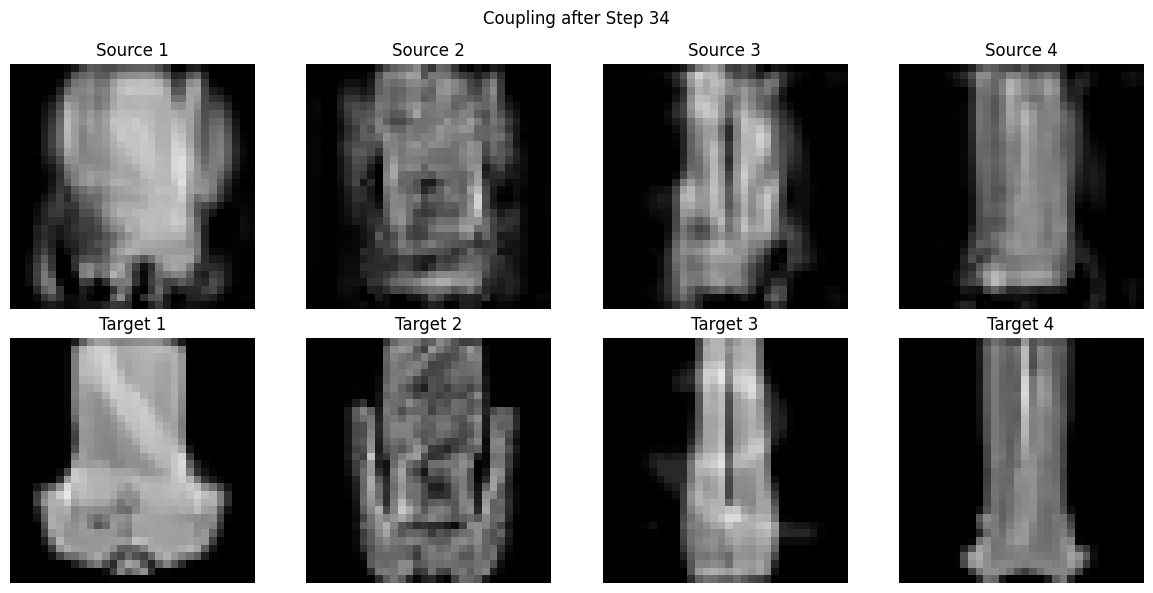

Iteration 35/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.34it/s]


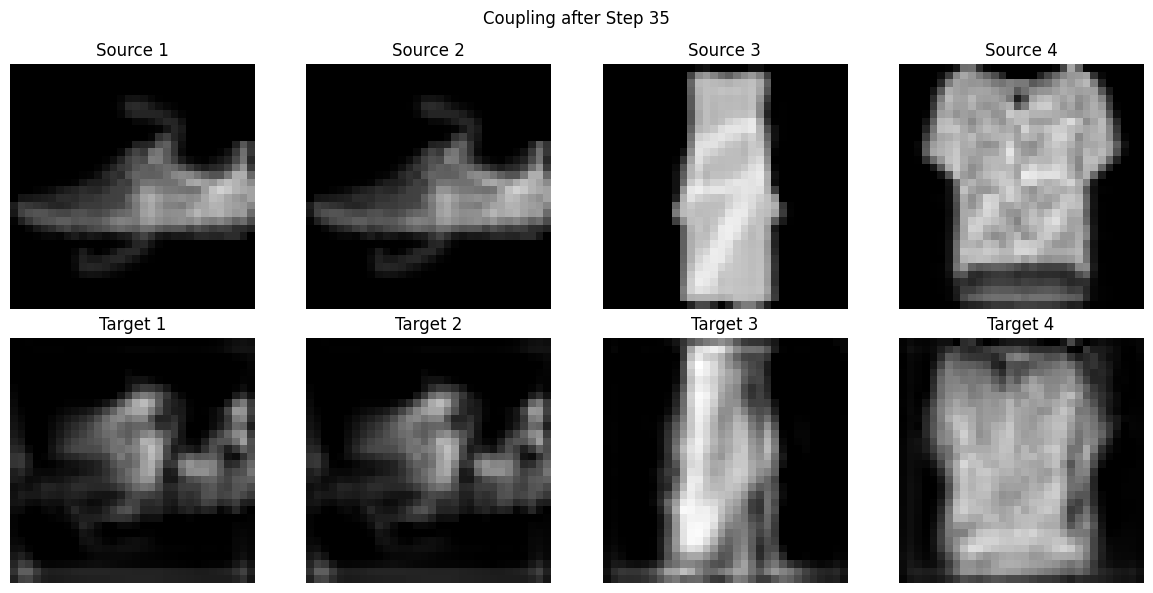

Iteration 36/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.36it/s]


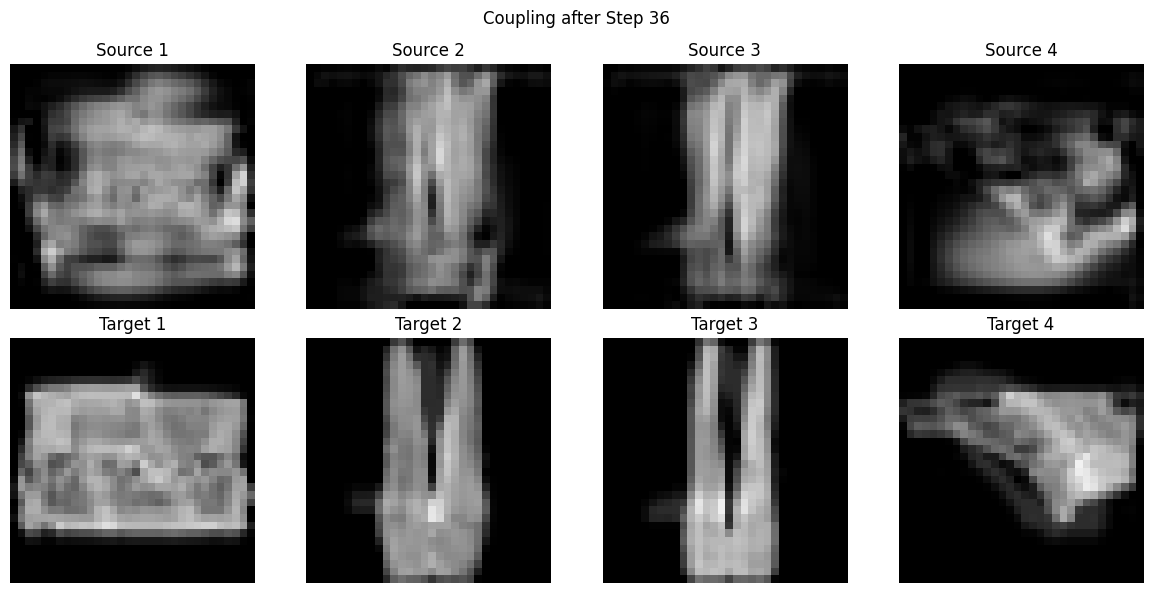

Iteration 37/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.35it/s]


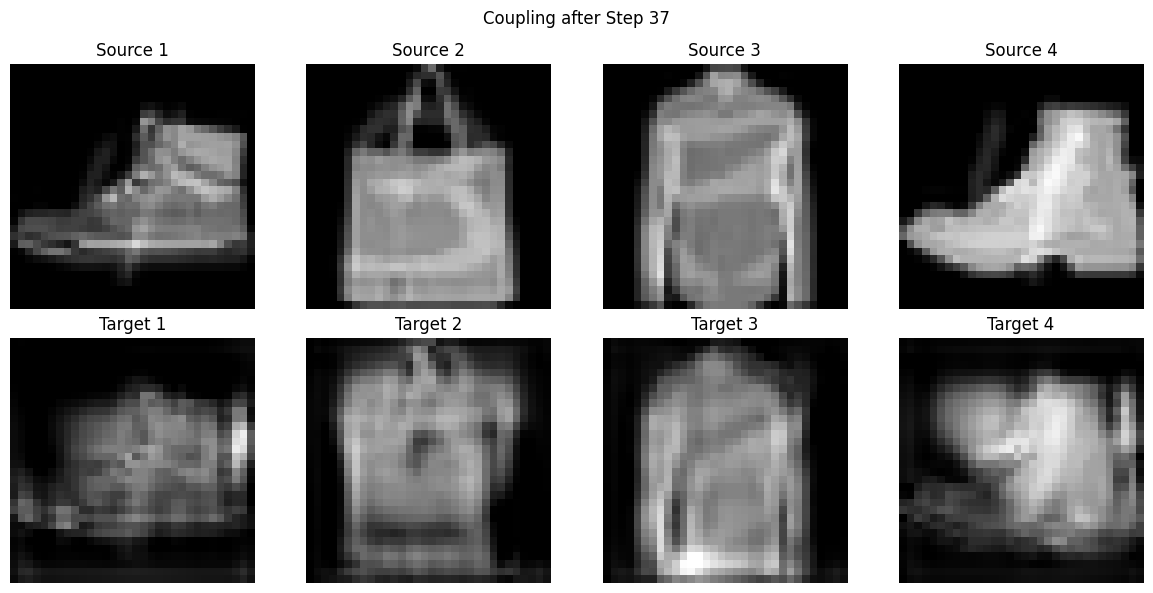

Iteration 38/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.35it/s]


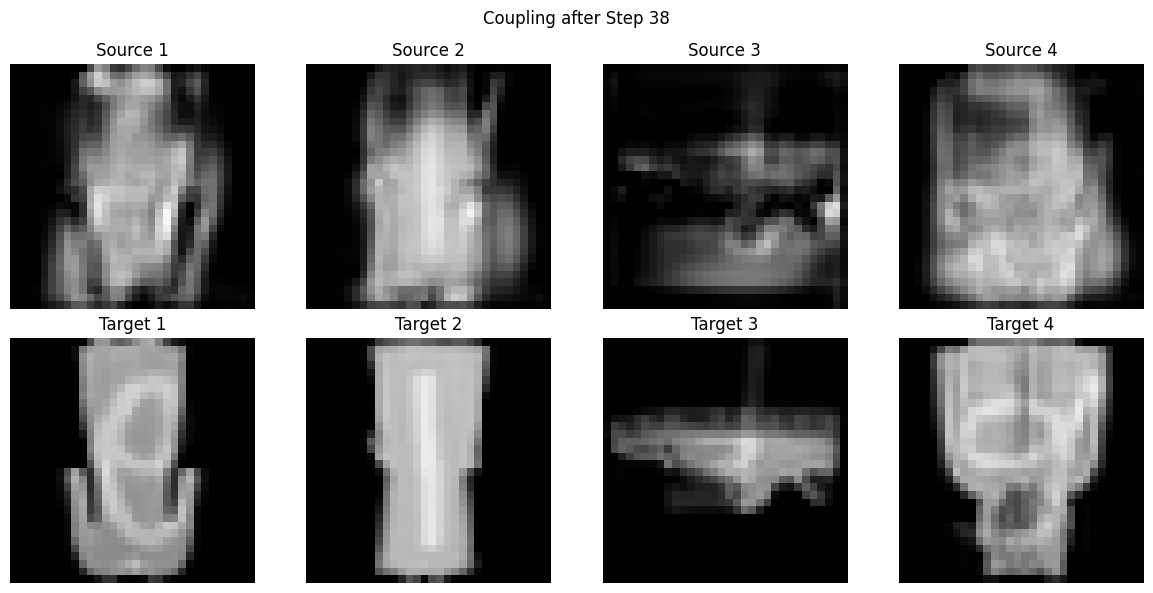

Iteration 39/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.34it/s]


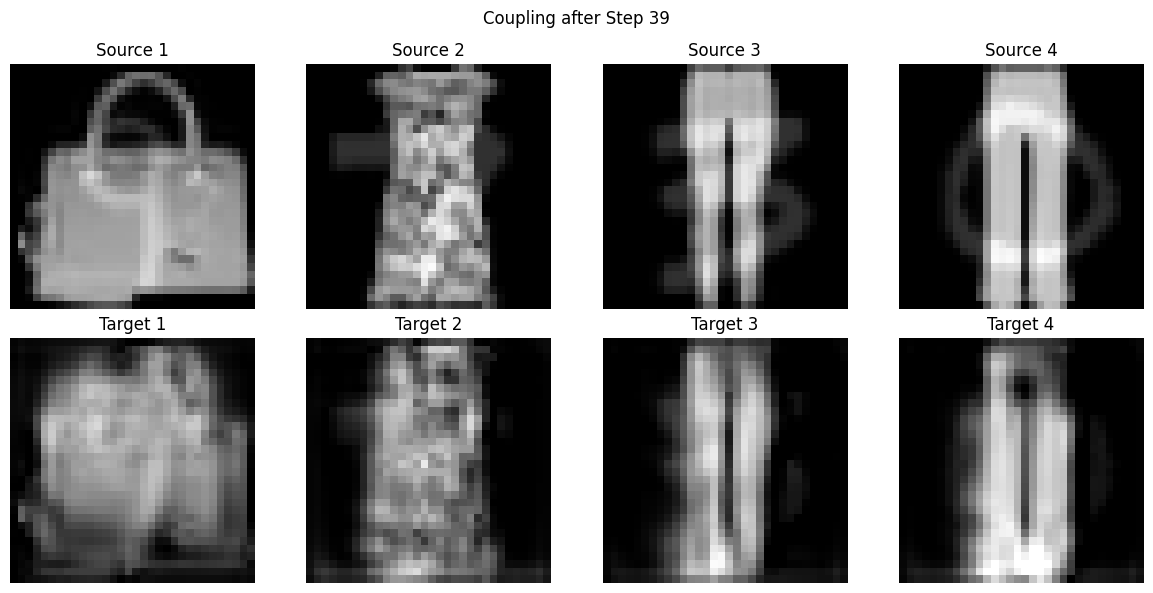

Iteration 40/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.34it/s]


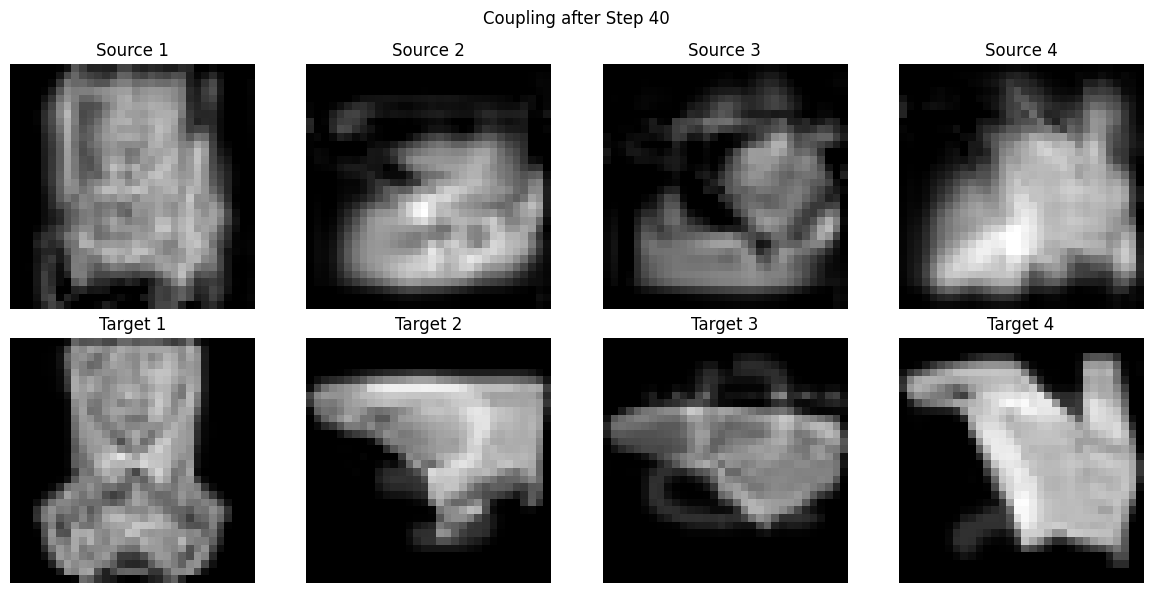

Iteration 41/200


CFM Training: 100%|██████████| 5/5 [00:01<00:00,  4.98it/s, CFM Loss=3.42e-9]


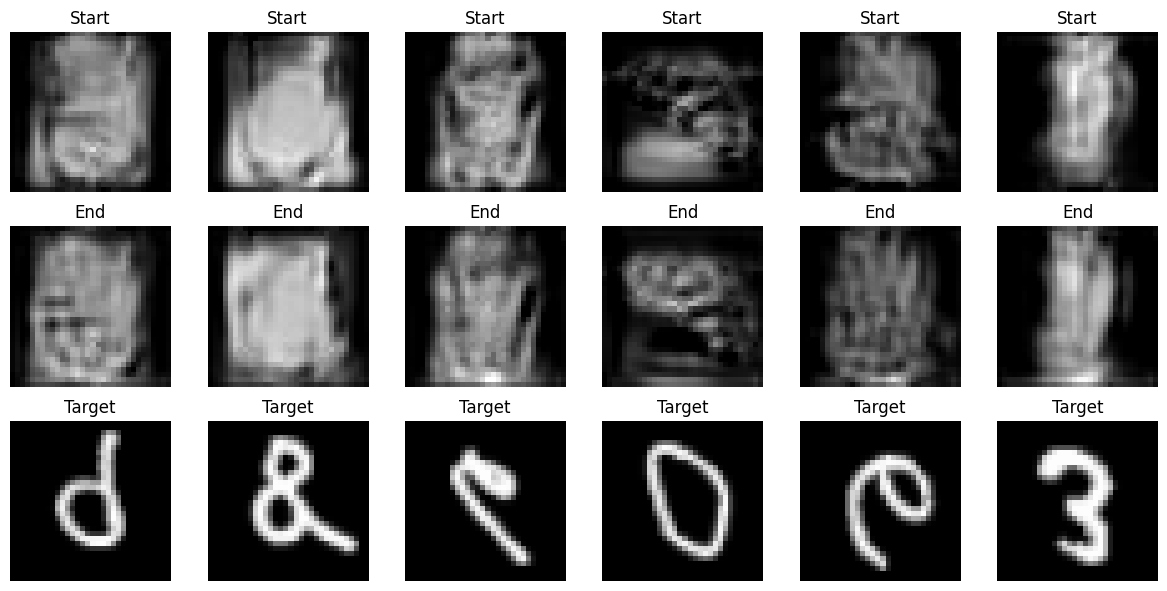

Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.33it/s]


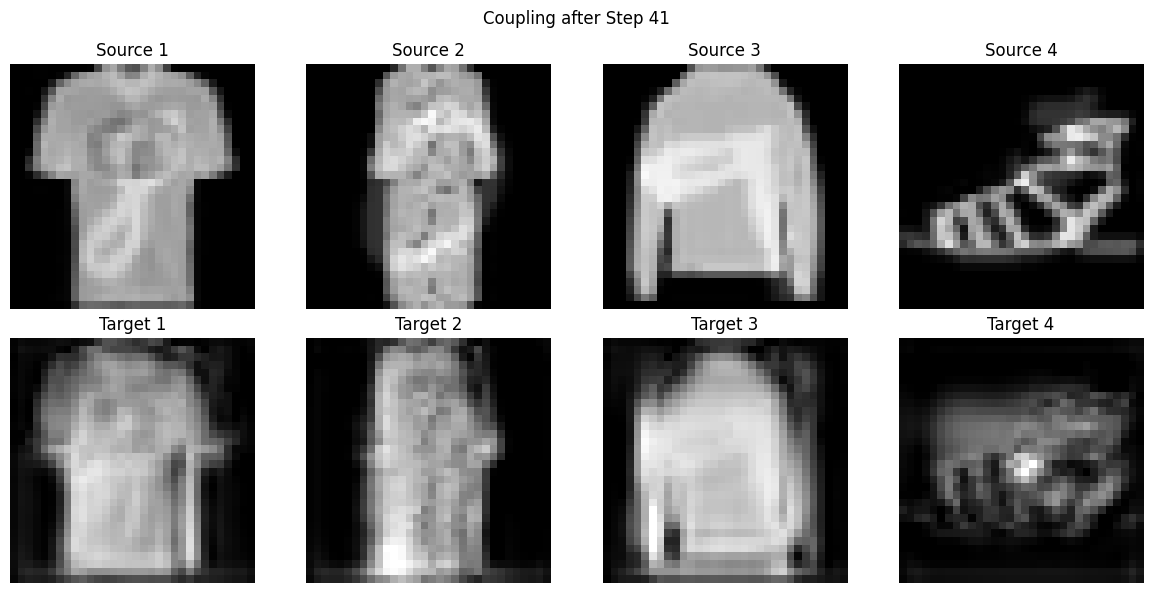

Iteration 42/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.35it/s]


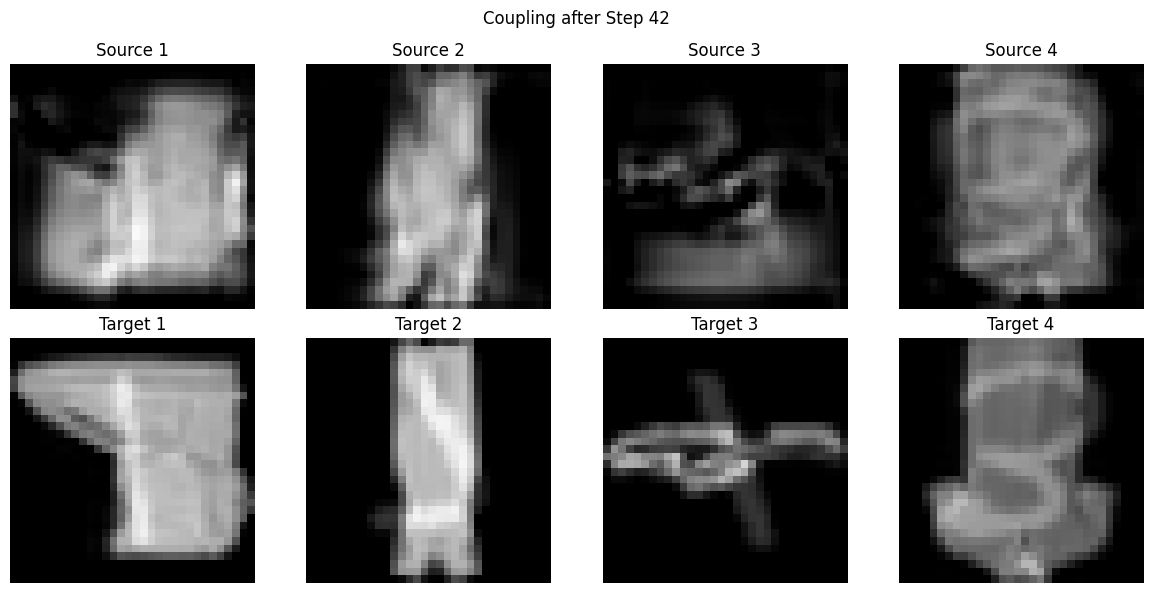

Iteration 43/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.35it/s]


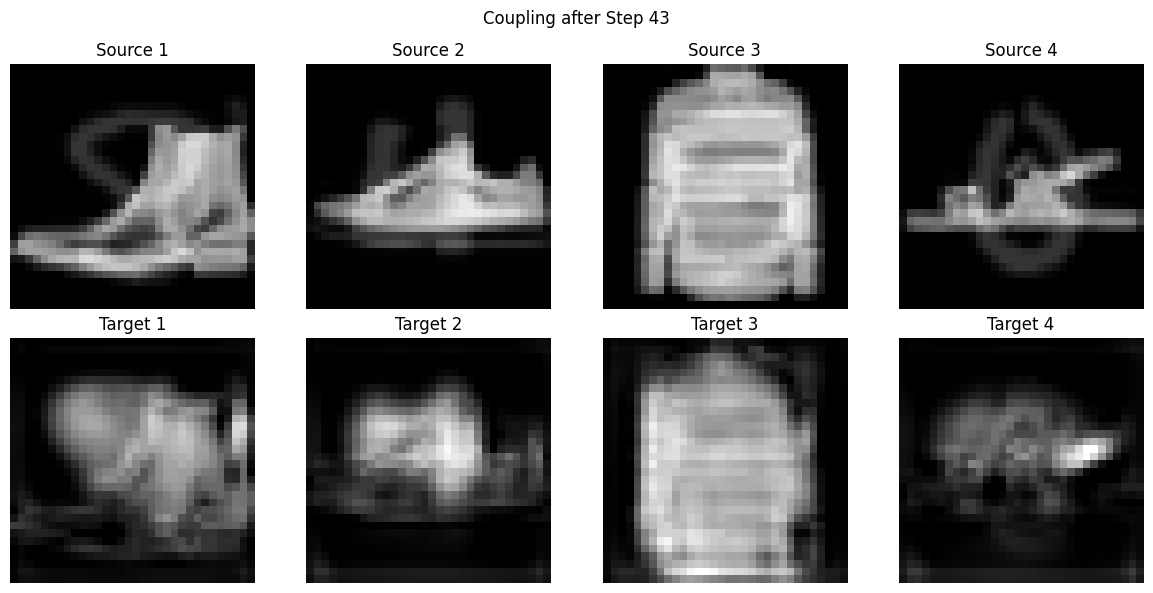

Iteration 44/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.35it/s]


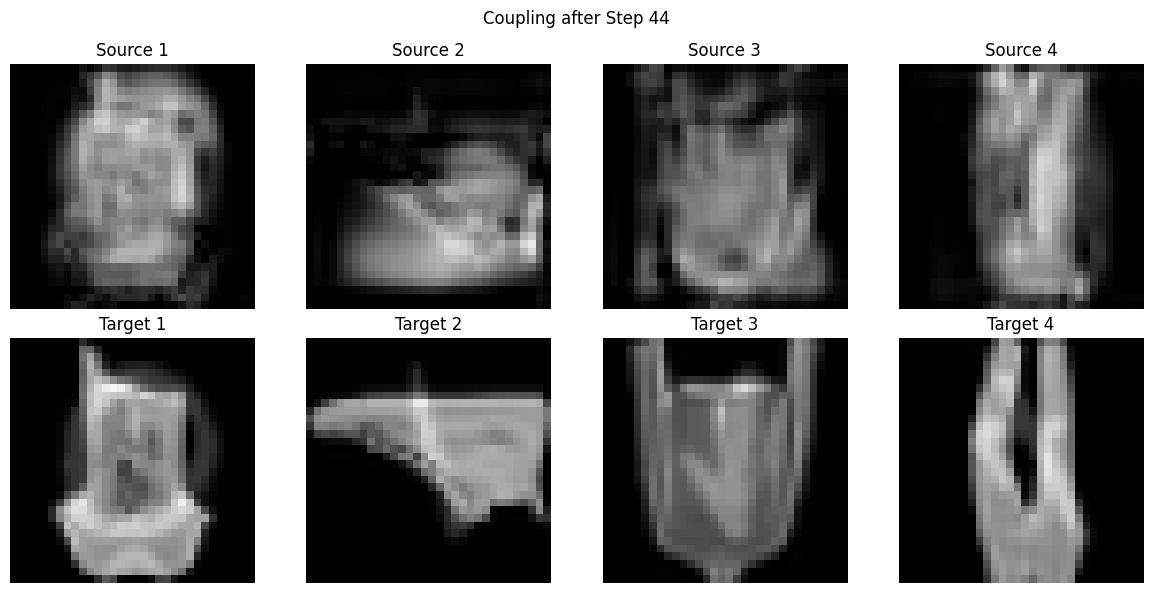

Iteration 45/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.35it/s]


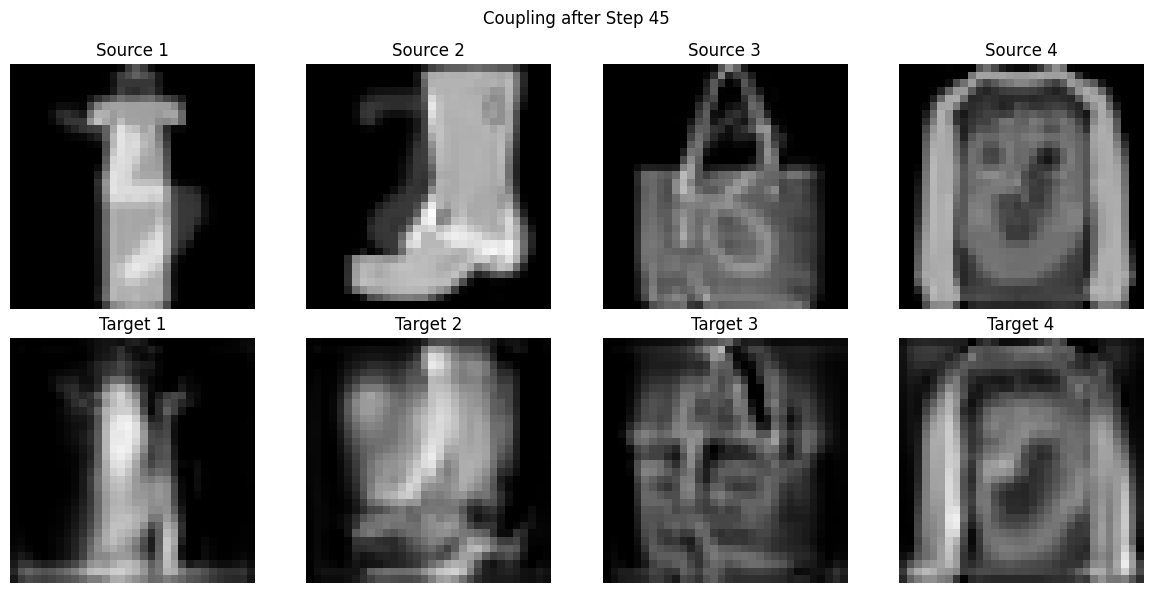

Iteration 46/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.33it/s]


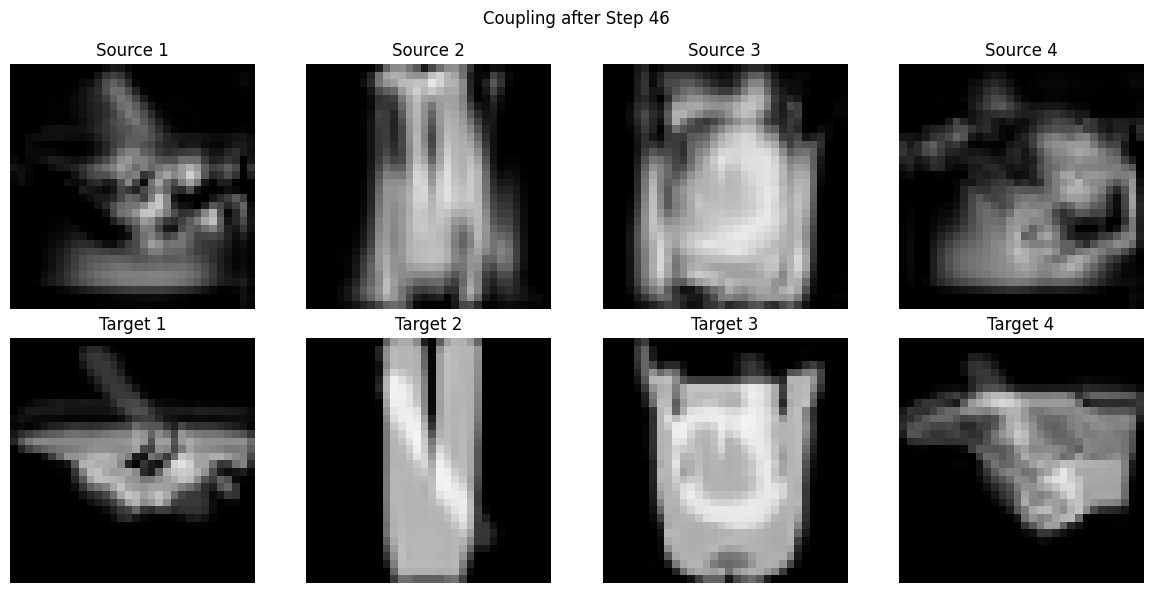

Iteration 47/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.34it/s]


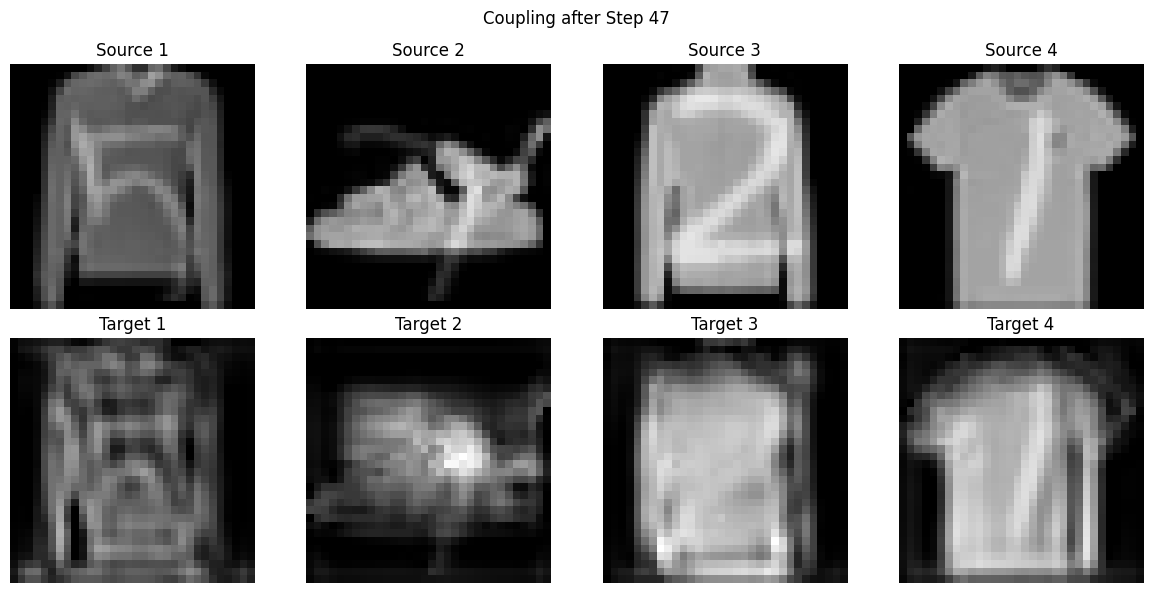

Iteration 48/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.34it/s]


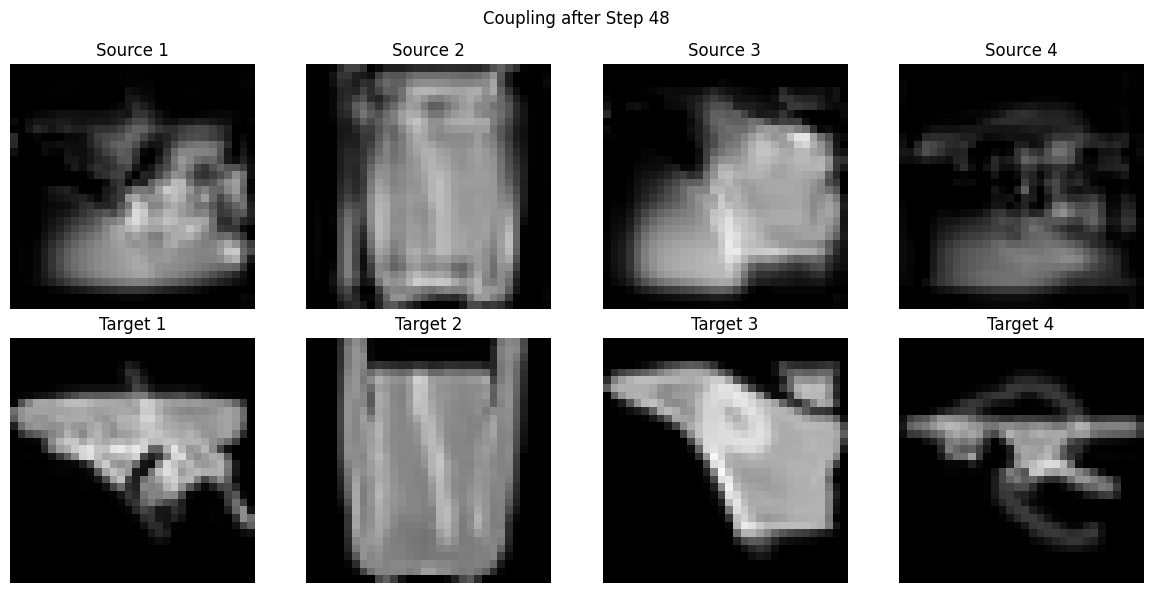

Iteration 49/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.33it/s]


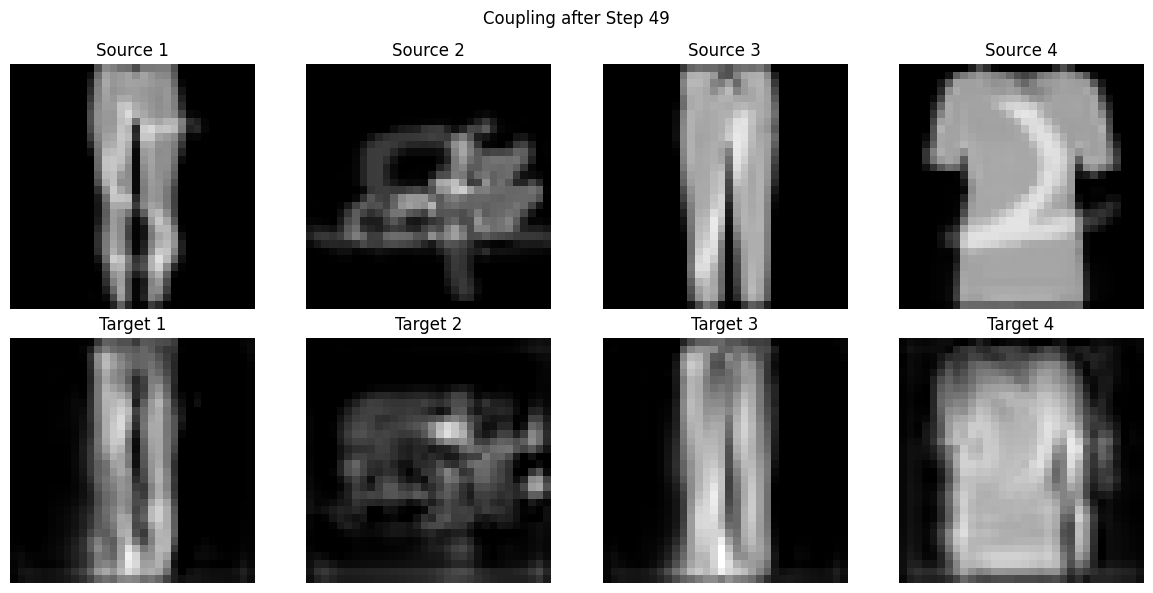

Iteration 50/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.34it/s]


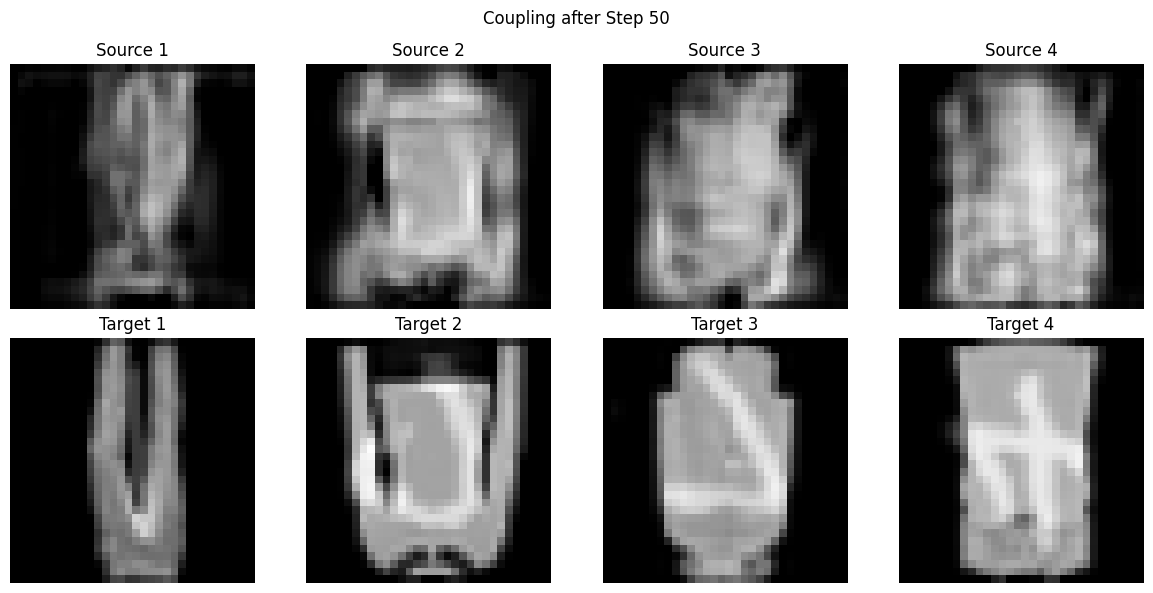

Iteration 51/200


CFM Training: 100%|██████████| 5/5 [00:01<00:00,  4.97it/s, CFM Loss=3.72e-9]


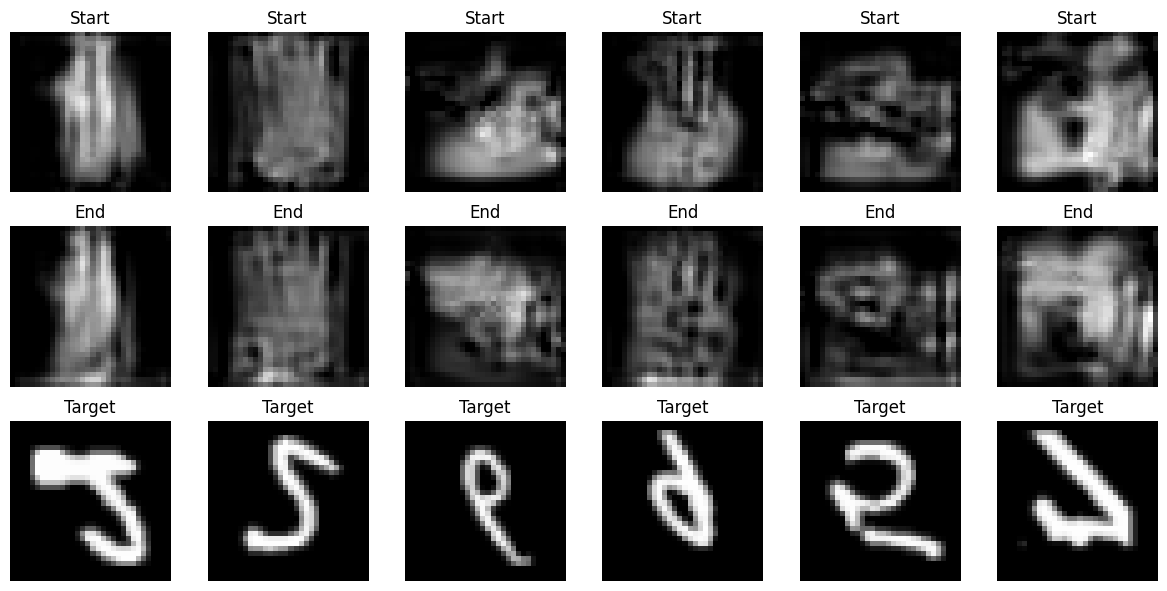

Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.35it/s]


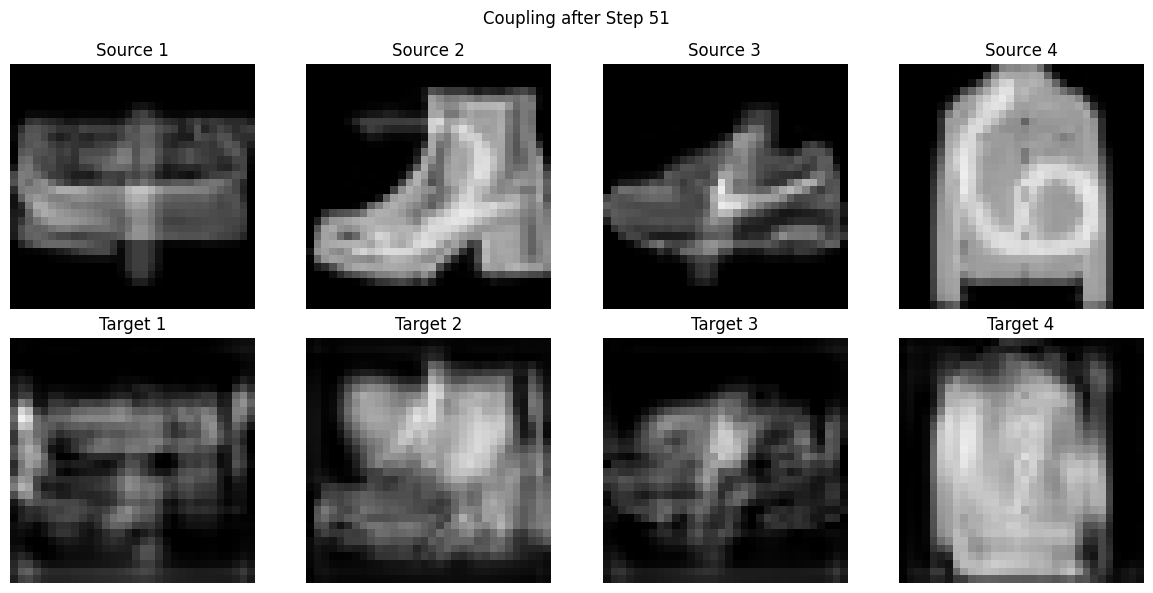

Iteration 52/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.33it/s]


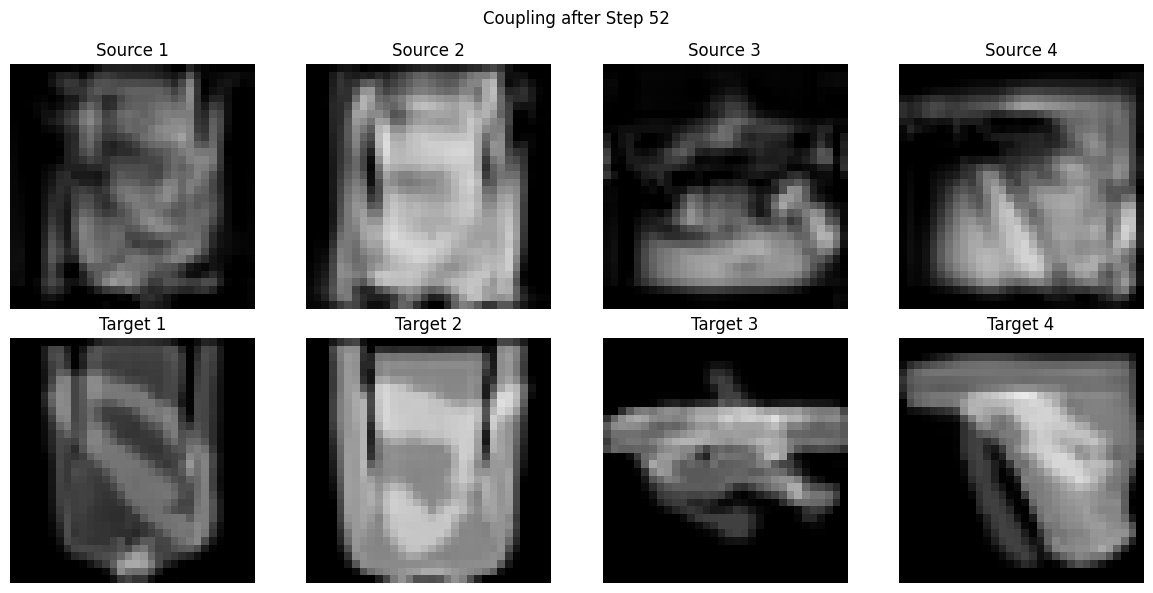

Iteration 53/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.34it/s]


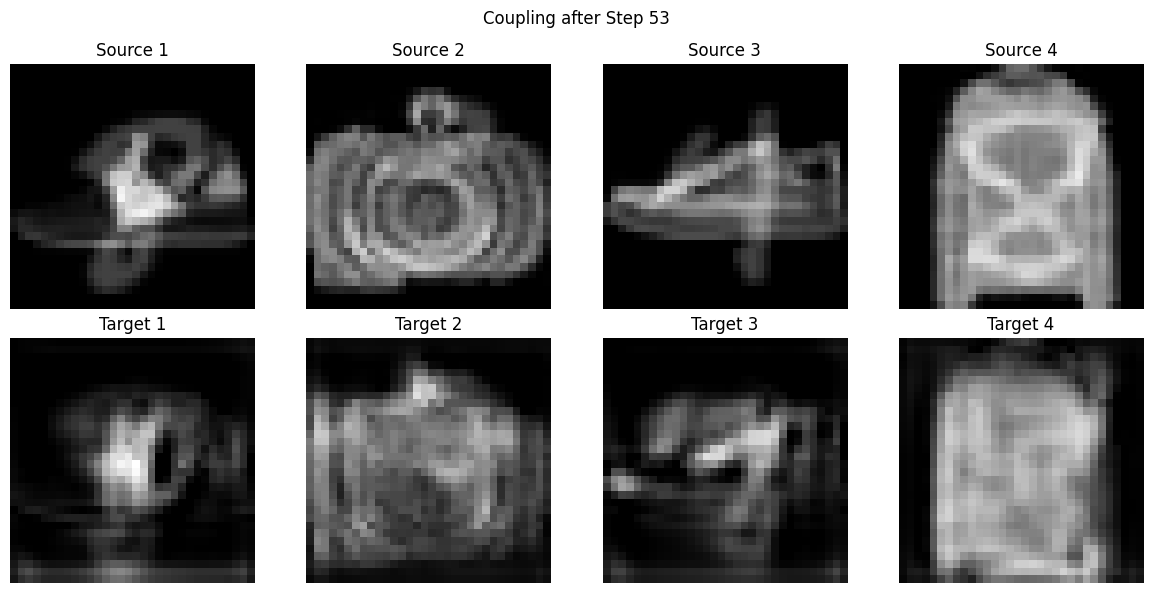

Iteration 54/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.34it/s]


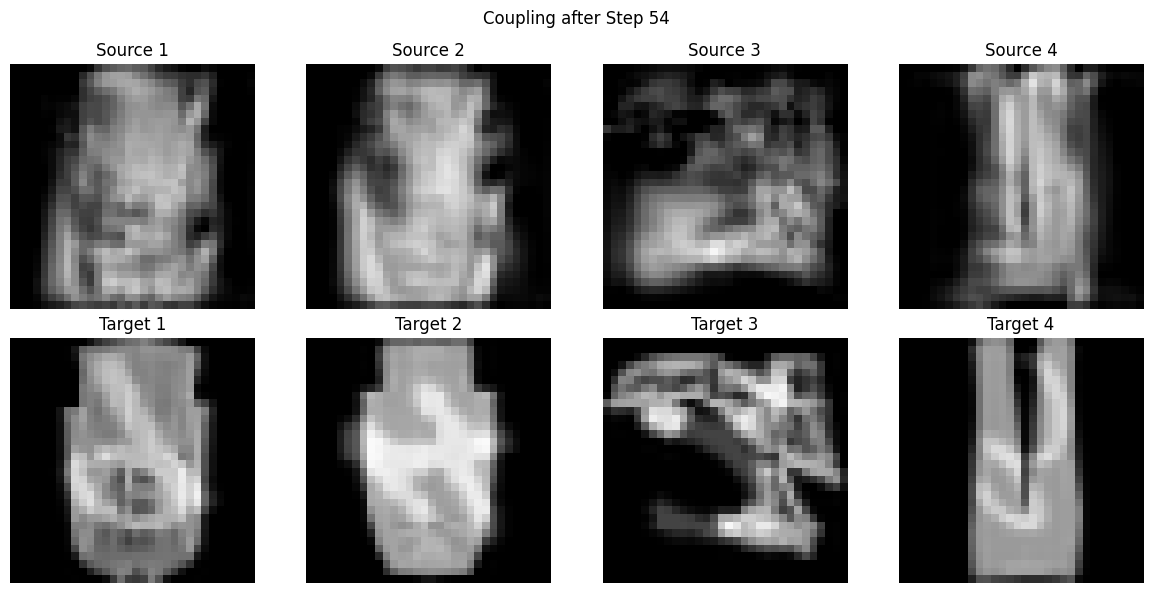

Iteration 55/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.35it/s]


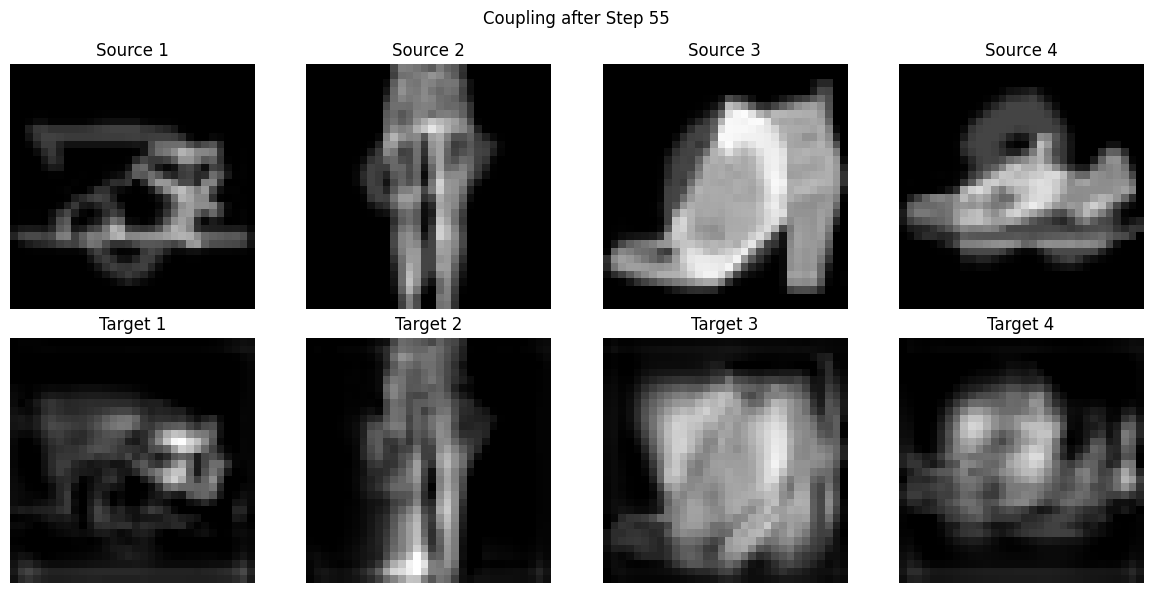

Iteration 56/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.35it/s]


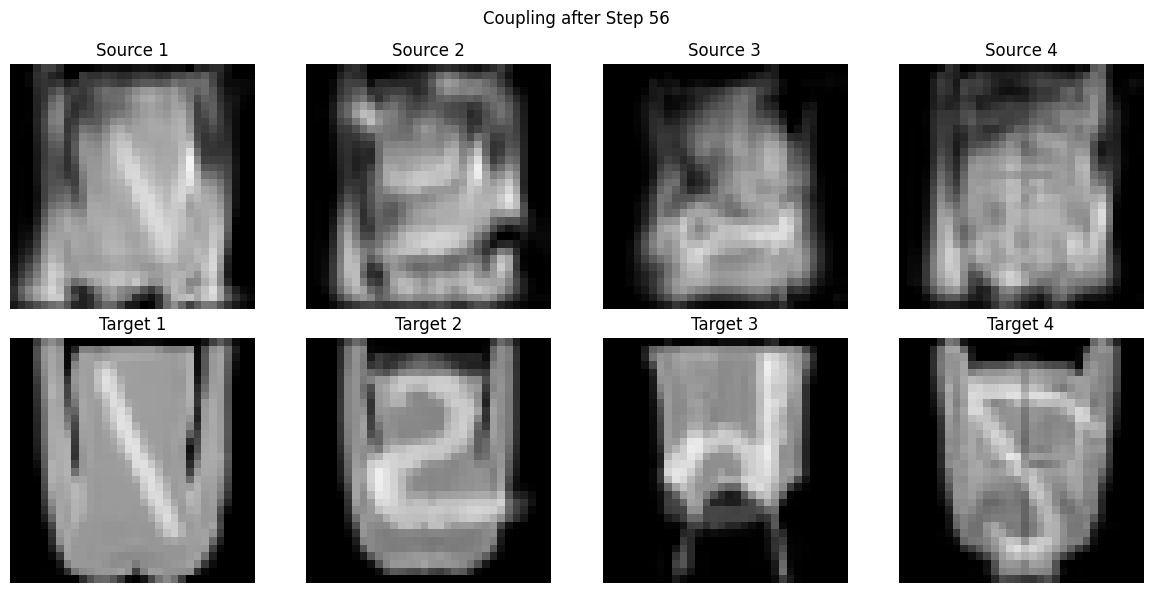

Iteration 57/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.35it/s]


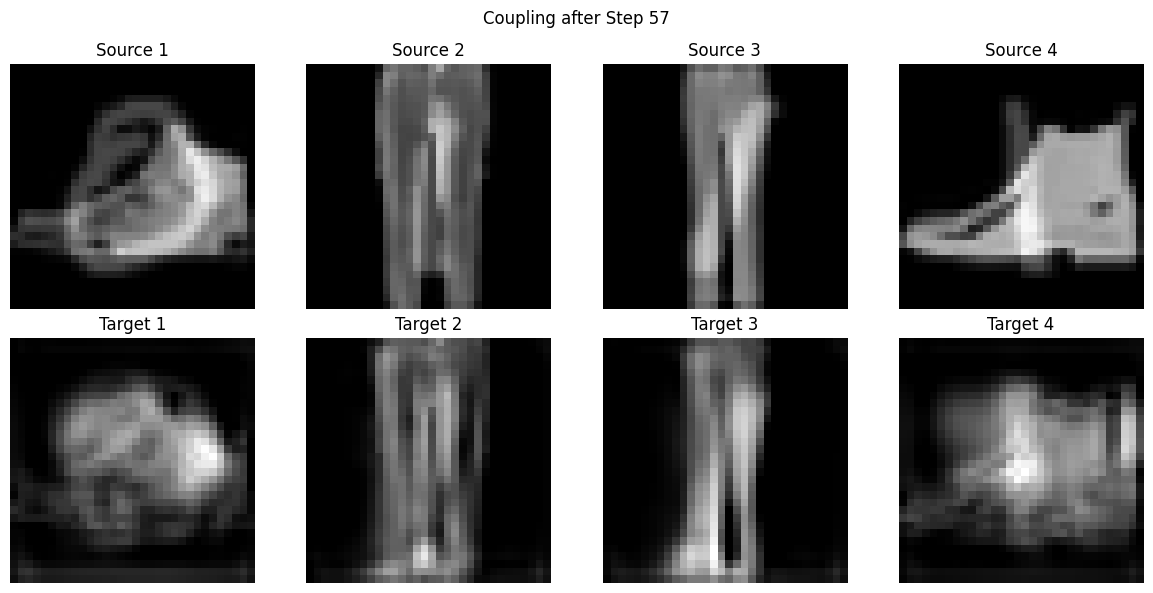

Iteration 58/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.34it/s]


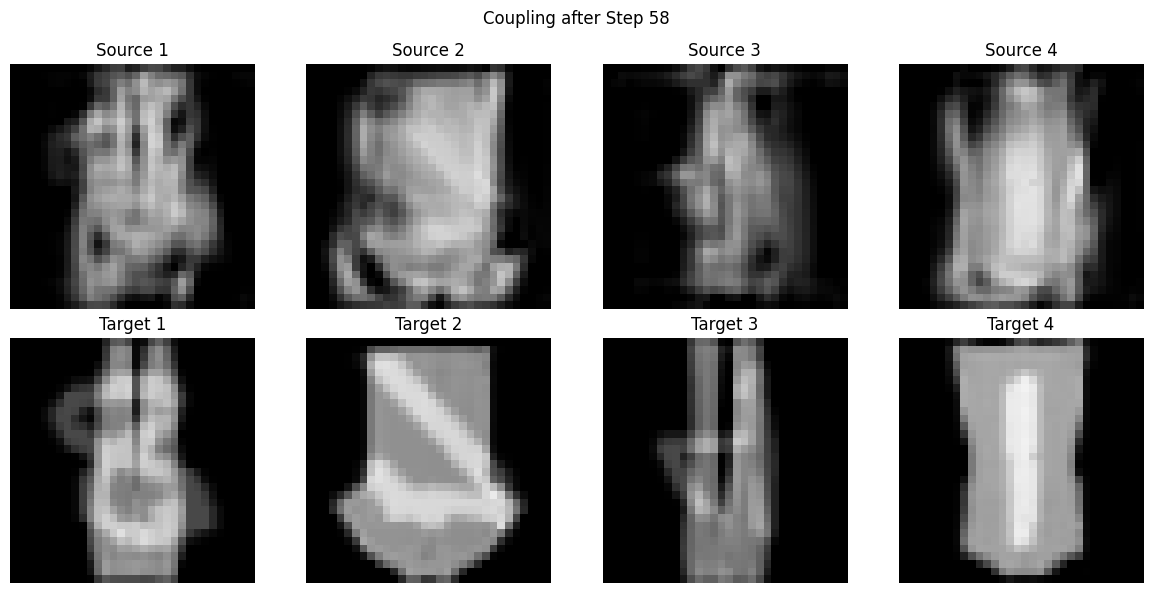

Iteration 59/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.34it/s]


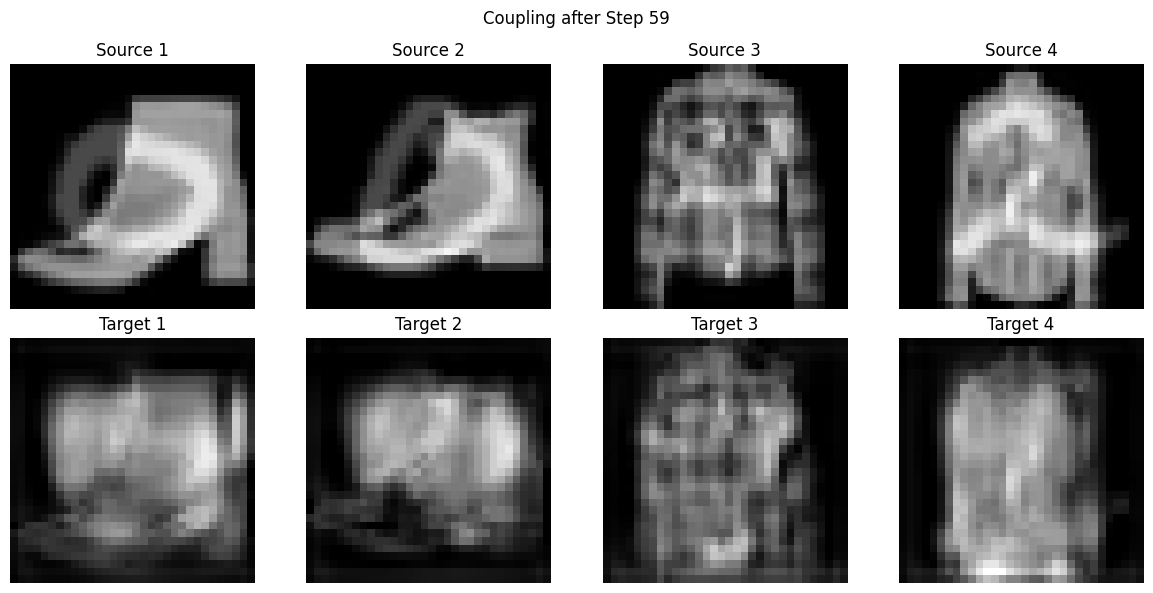

Iteration 60/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.32it/s]


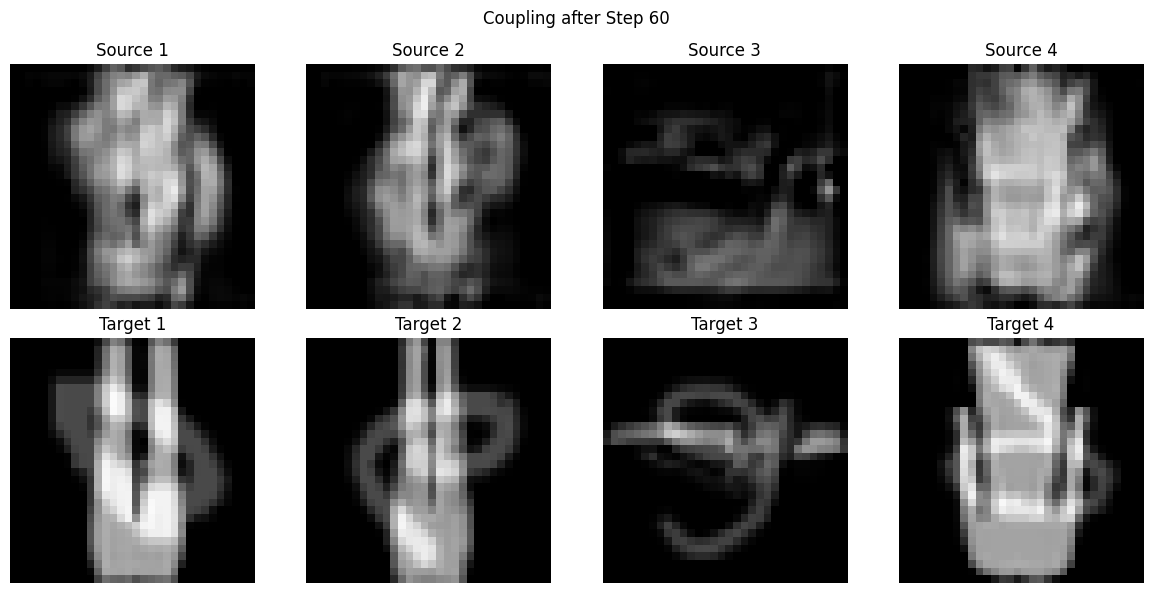

Iteration 61/200


CFM Training: 100%|██████████| 5/5 [00:01<00:00,  3.76it/s, CFM Loss=3.32e-9]


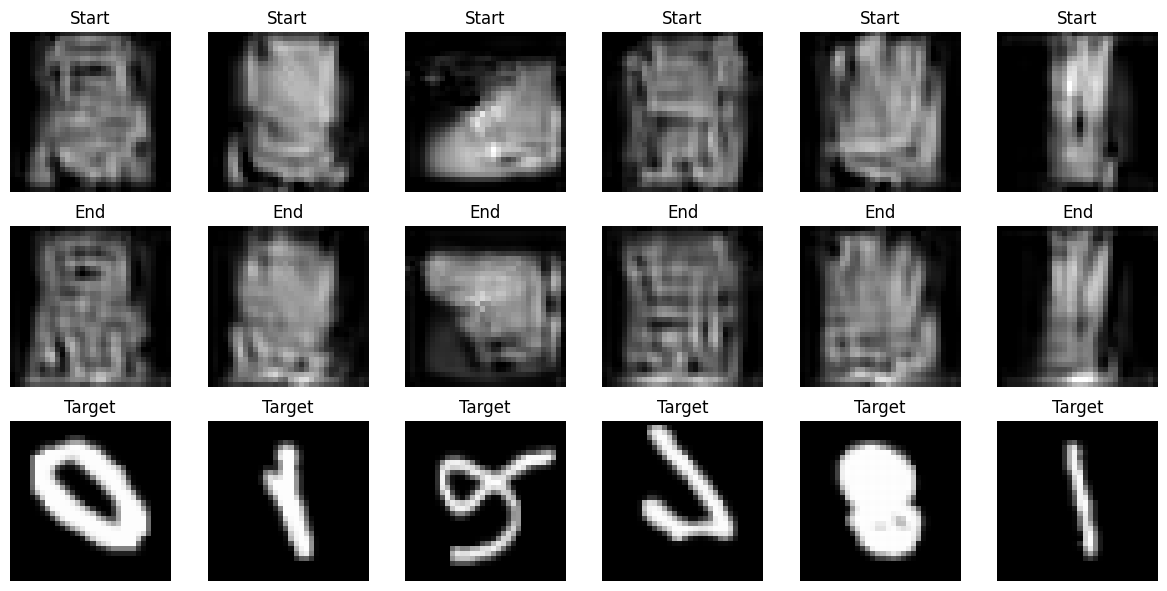

Advancing coupling: 100%|██████████| 8/8 [00:04<00:00,  1.83it/s]


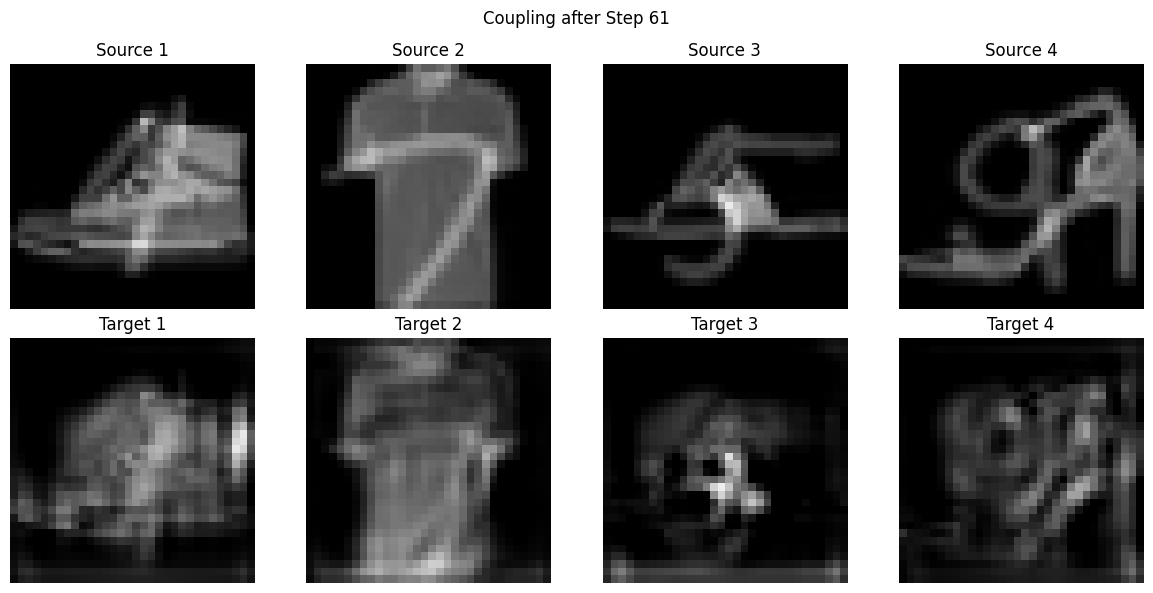

Iteration 62/200


Advancing coupling: 100%|██████████| 8/8 [00:04<00:00,  1.85it/s]


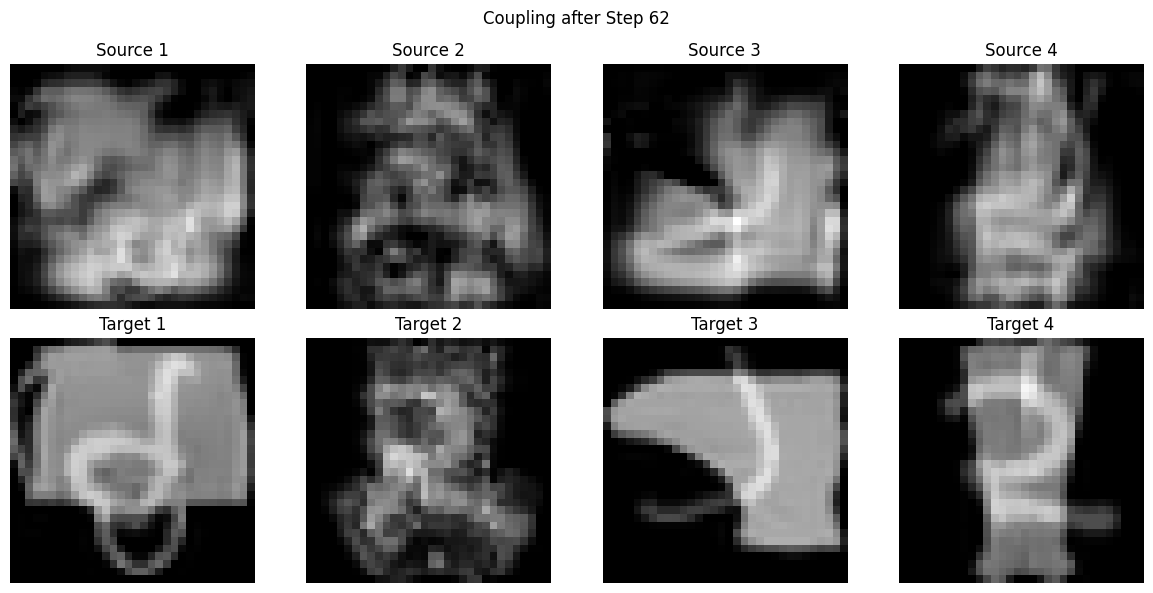

Iteration 63/200


Advancing coupling: 100%|██████████| 8/8 [00:04<00:00,  1.85it/s]


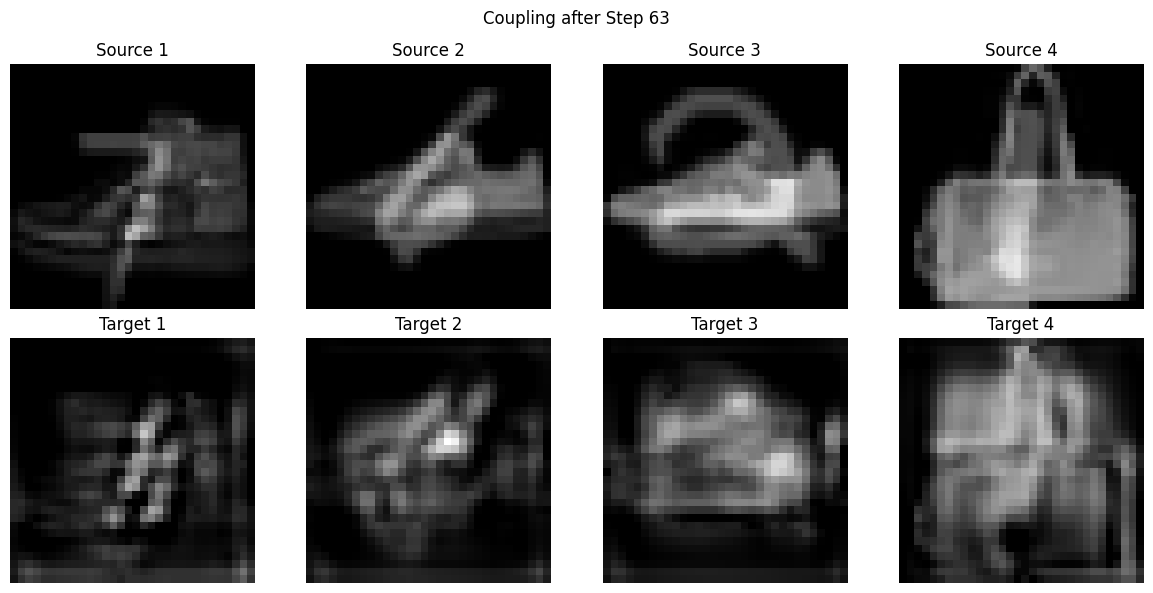

Iteration 64/200


Advancing coupling: 100%|██████████| 8/8 [00:04<00:00,  1.87it/s]


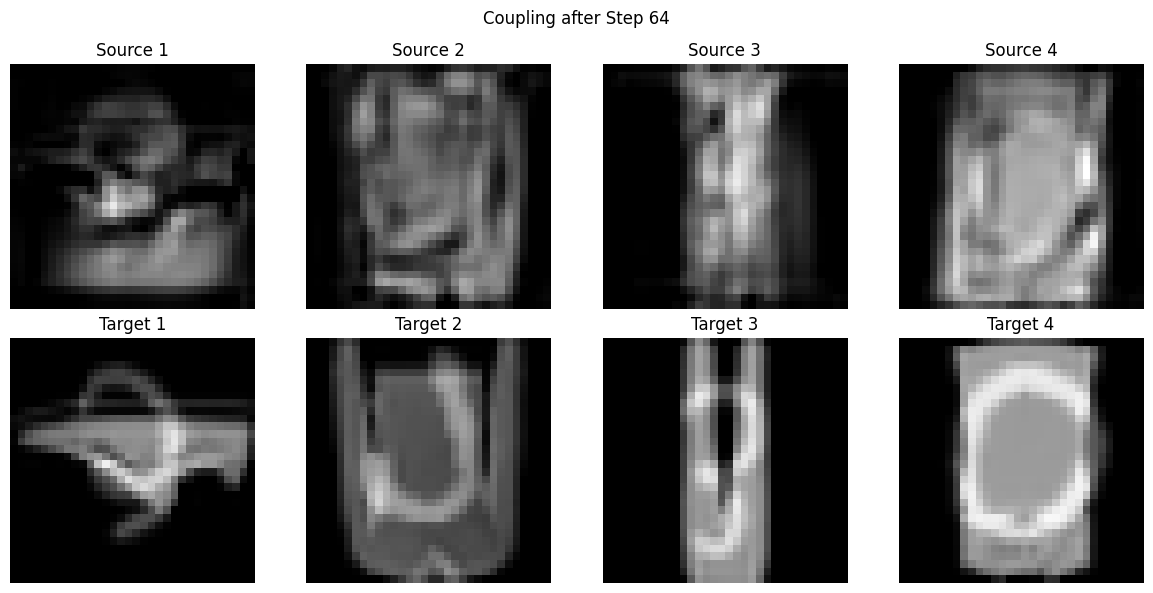

Iteration 65/200


Advancing coupling: 100%|██████████| 8/8 [00:04<00:00,  1.96it/s]


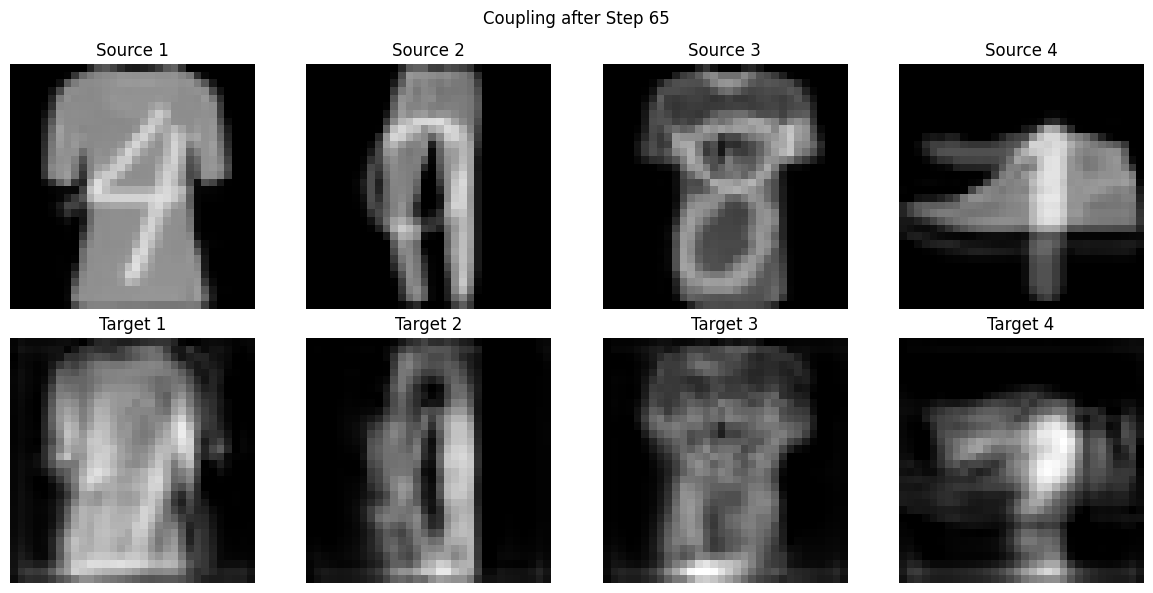

Iteration 66/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.34it/s]


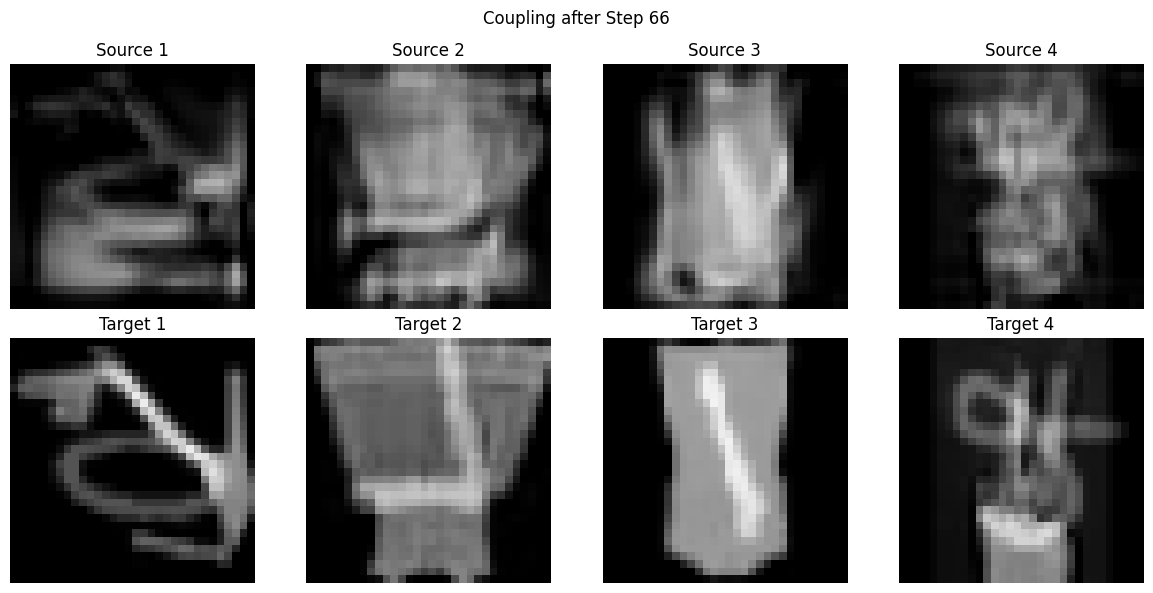

Iteration 67/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.34it/s]


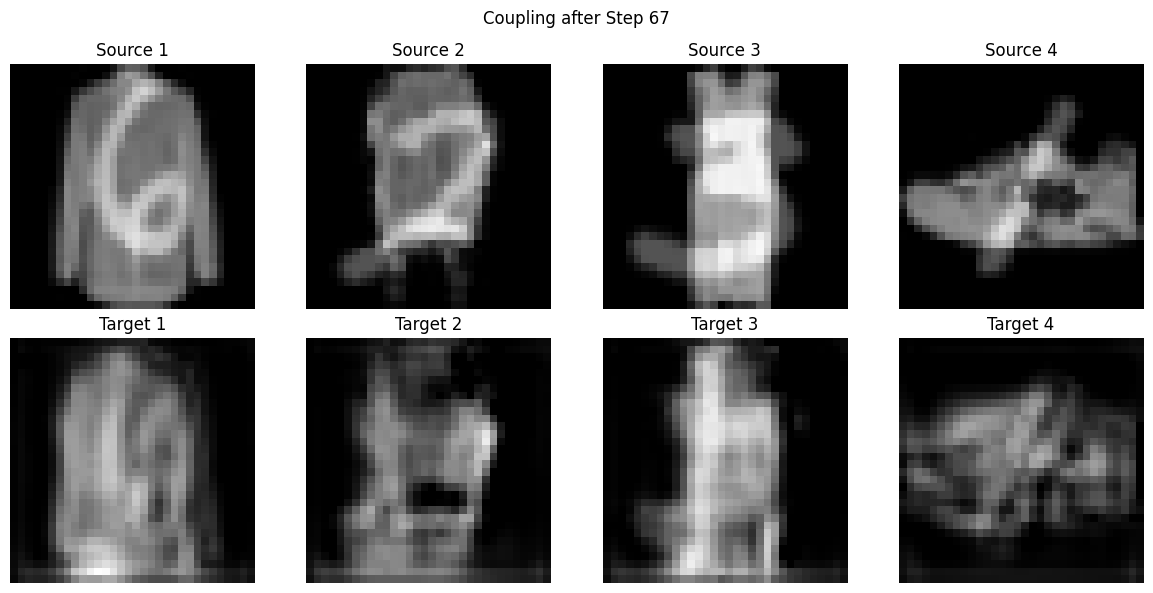

Iteration 68/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.33it/s]


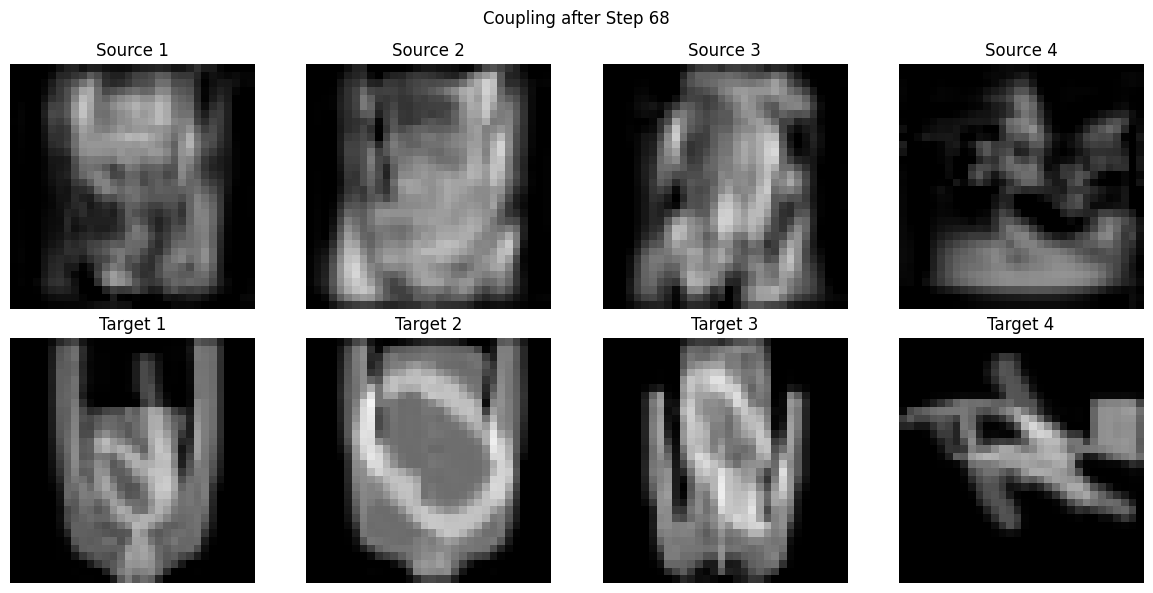

Iteration 69/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.33it/s]


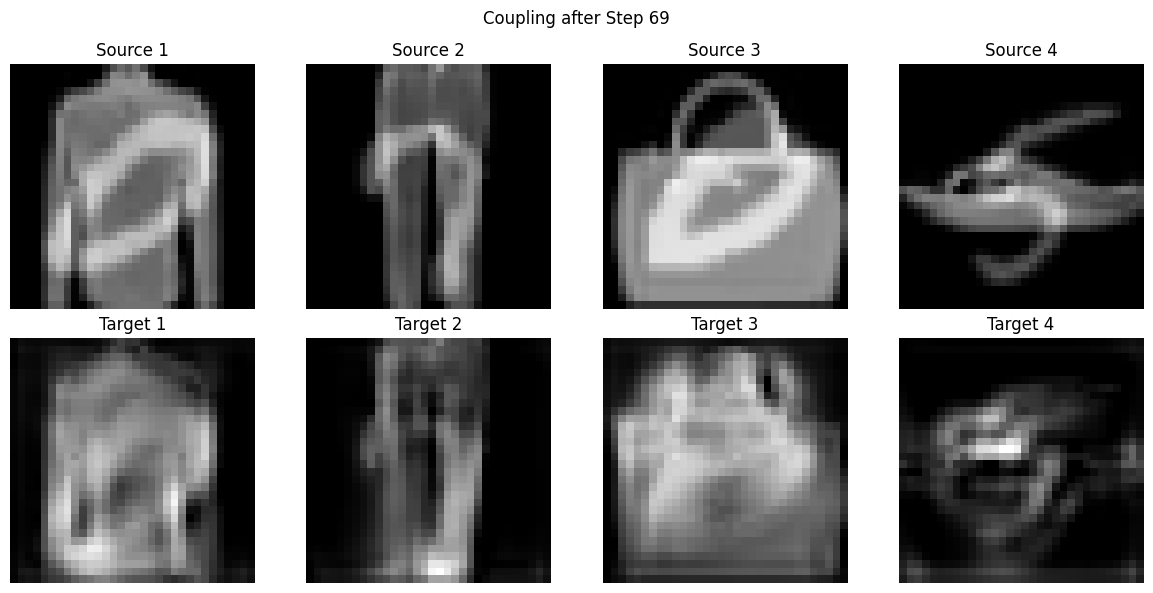

Iteration 70/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.34it/s]


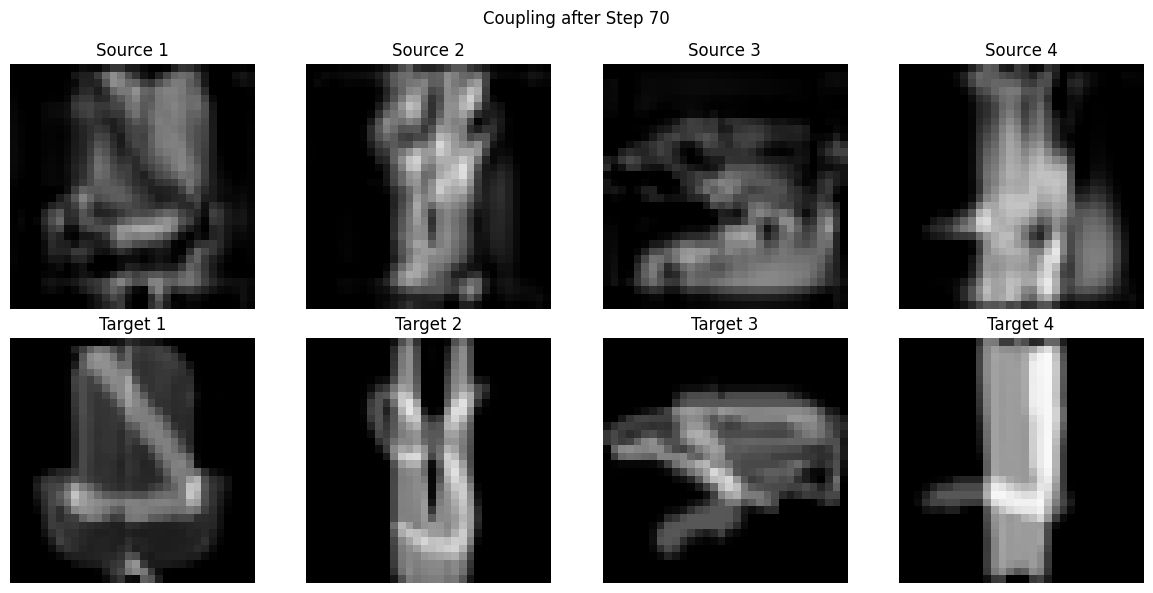

Iteration 71/200


CFM Training: 100%|██████████| 5/5 [00:01<00:00,  4.96it/s, CFM Loss=3.35e-9]


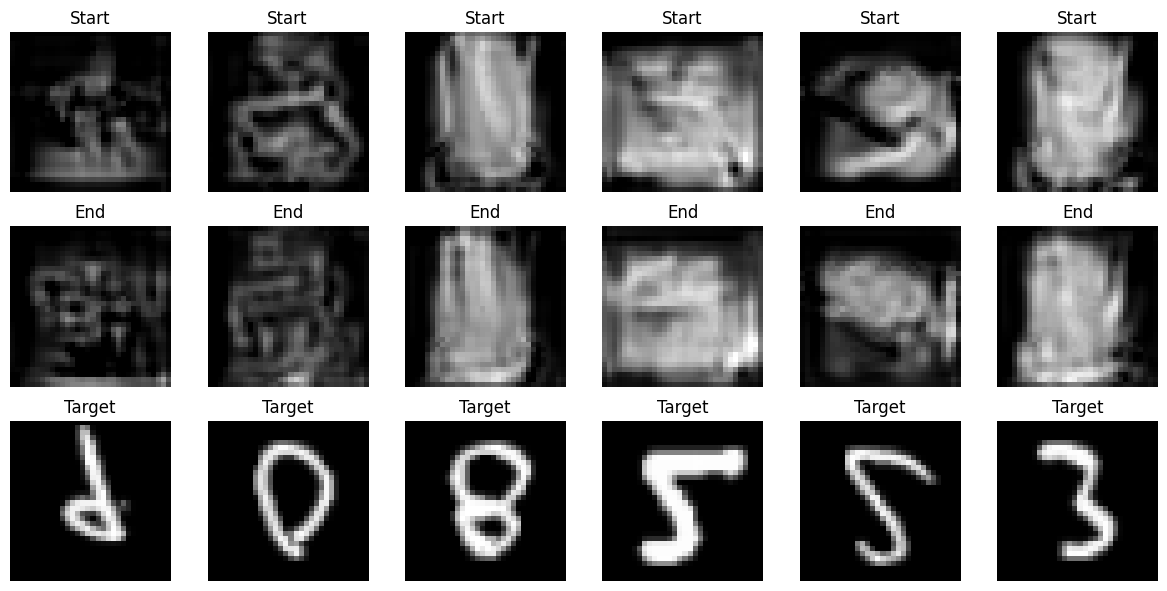

Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.30it/s]


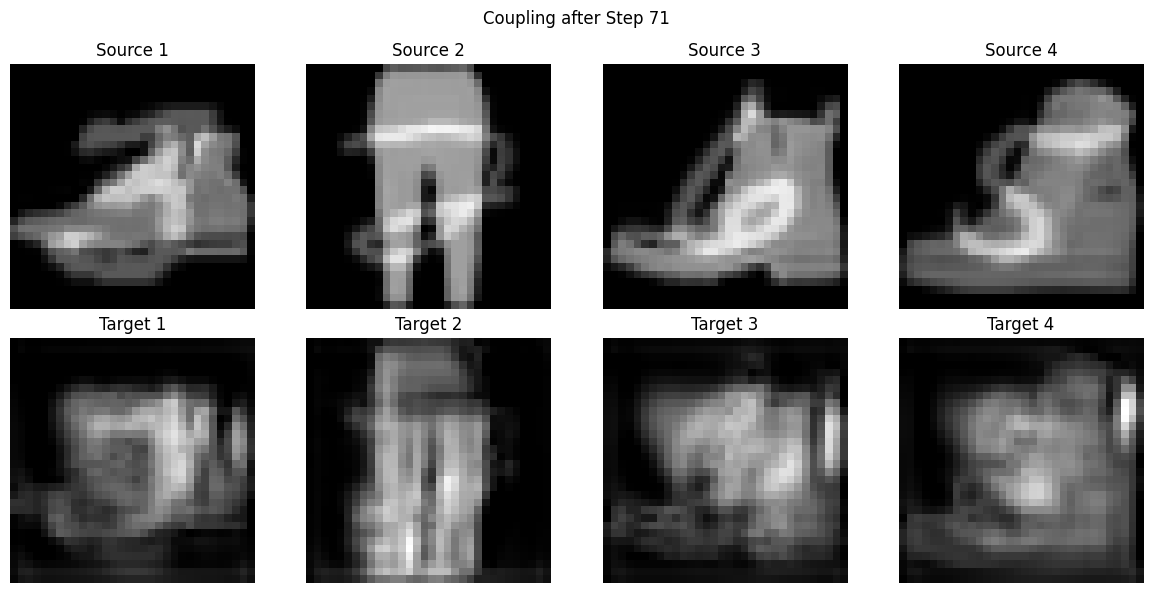

Iteration 72/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.33it/s]


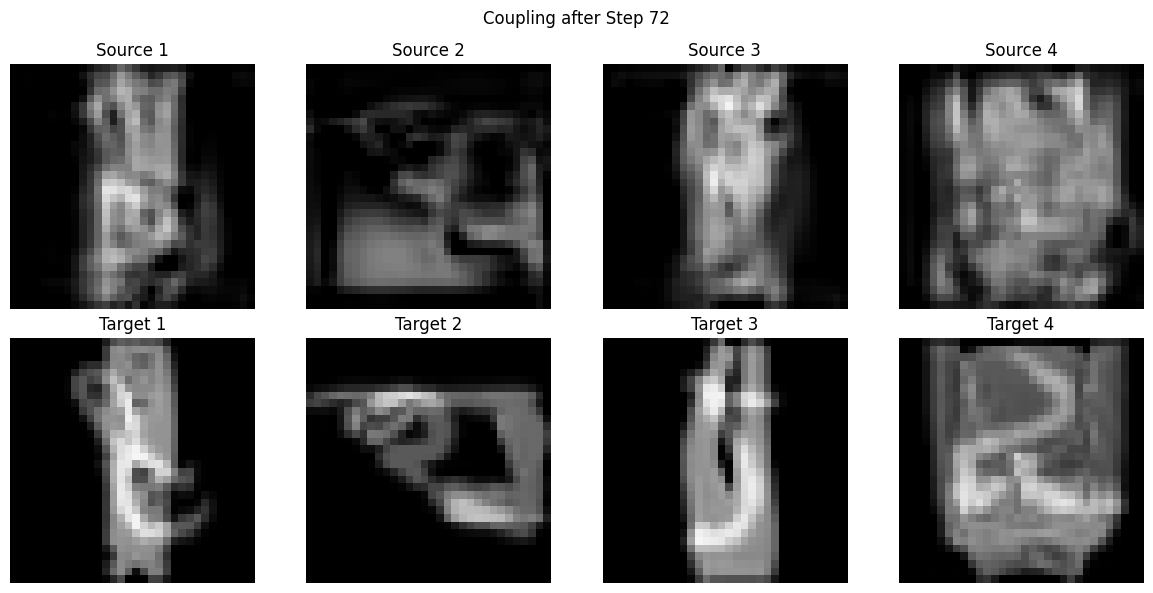

Iteration 73/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.33it/s]


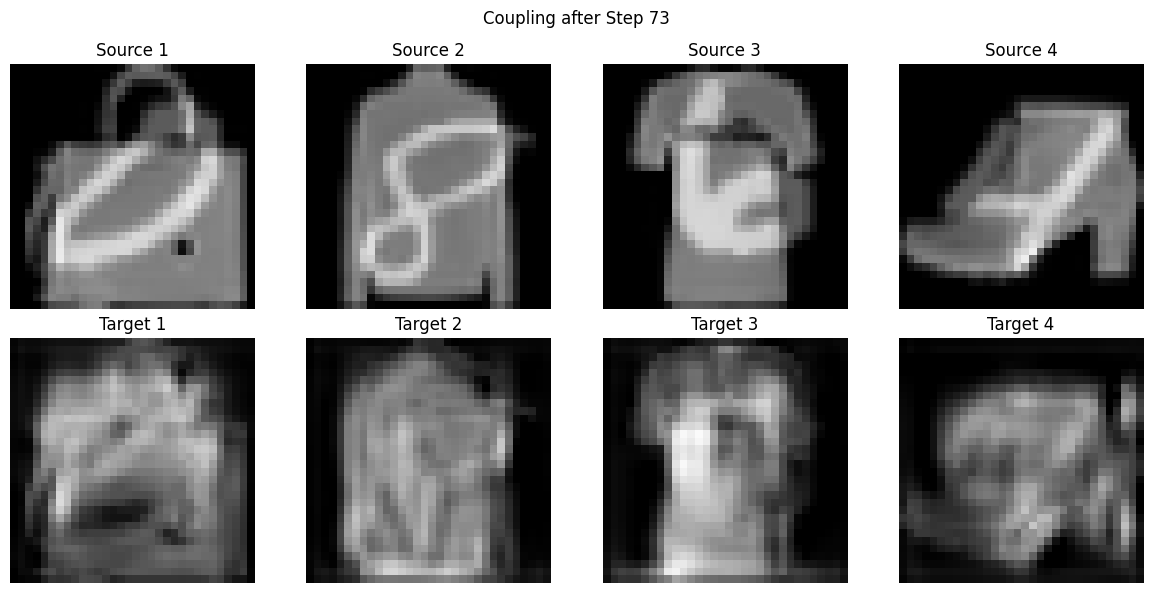

Iteration 74/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.33it/s]


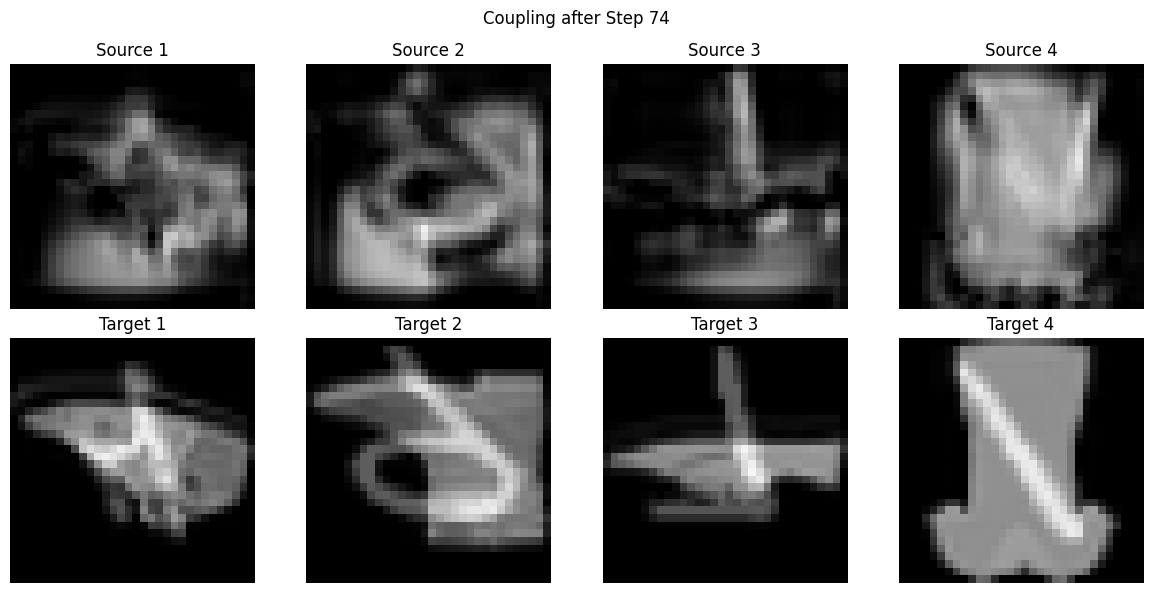

Iteration 75/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.33it/s]


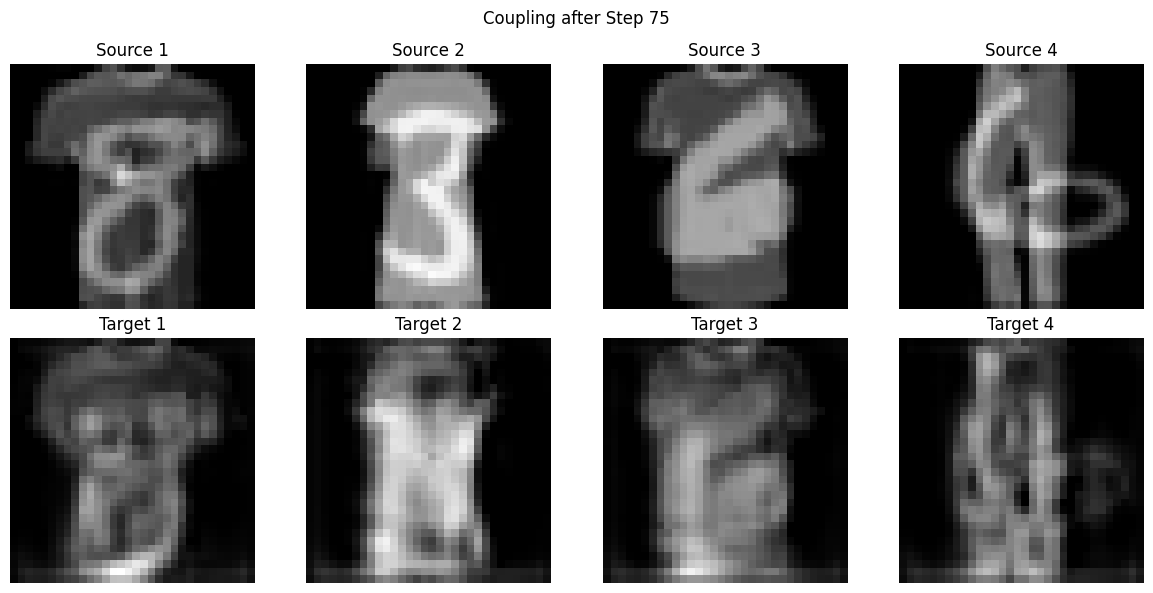

Iteration 76/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.33it/s]


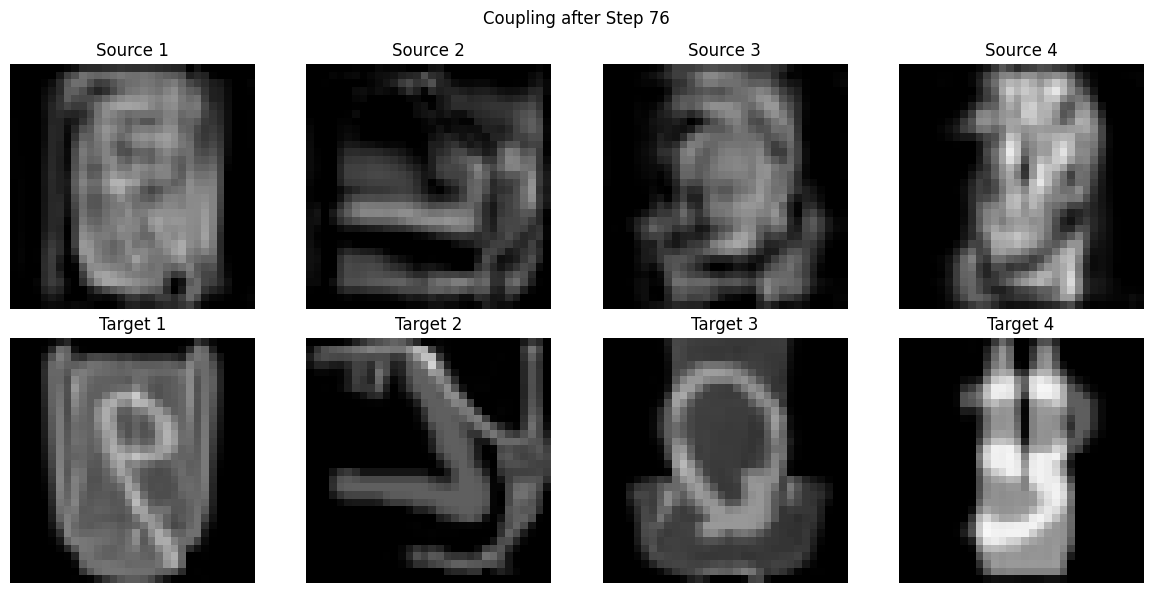

Iteration 77/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.34it/s]


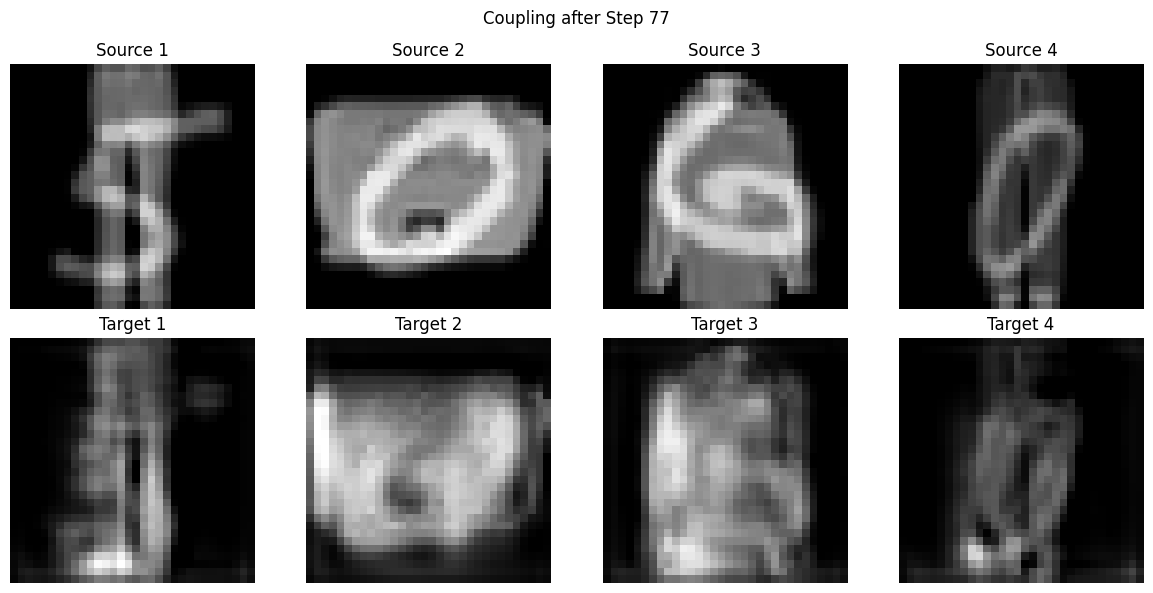

Iteration 78/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.34it/s]


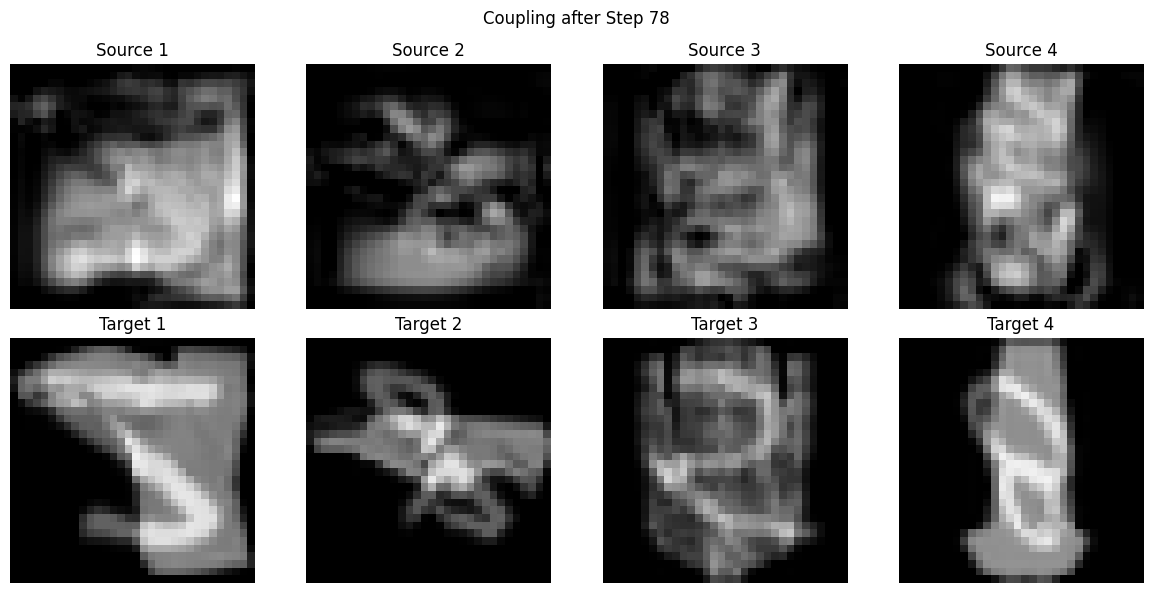

Iteration 79/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.32it/s]


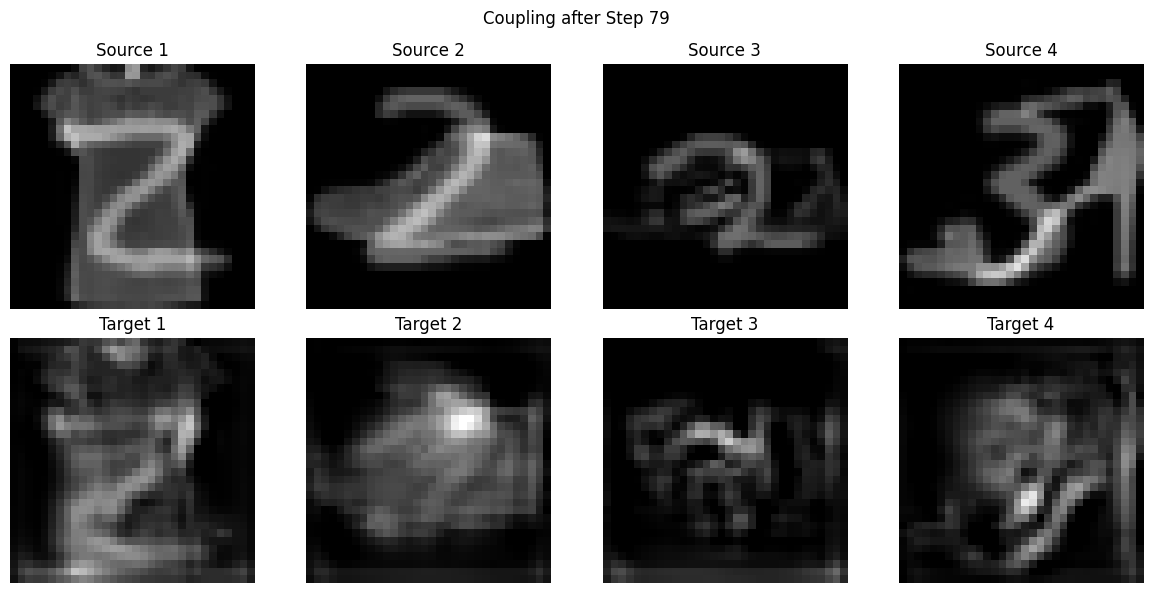

Iteration 80/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.34it/s]


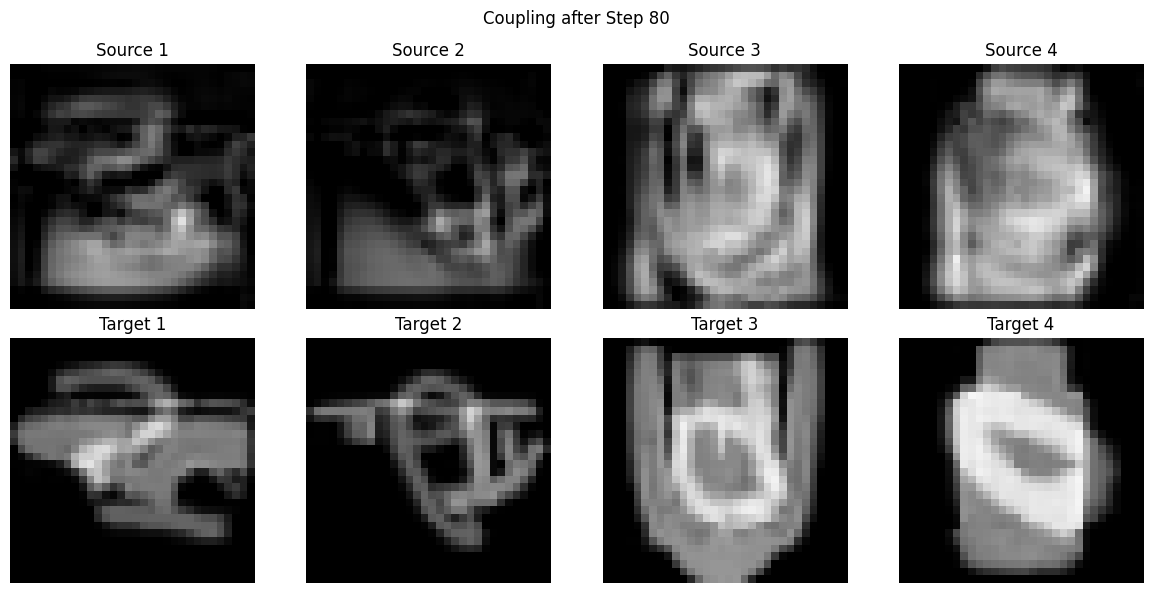

Iteration 81/200


CFM Training: 100%|██████████| 5/5 [00:01<00:00,  4.96it/s, CFM Loss=3.43e-9]


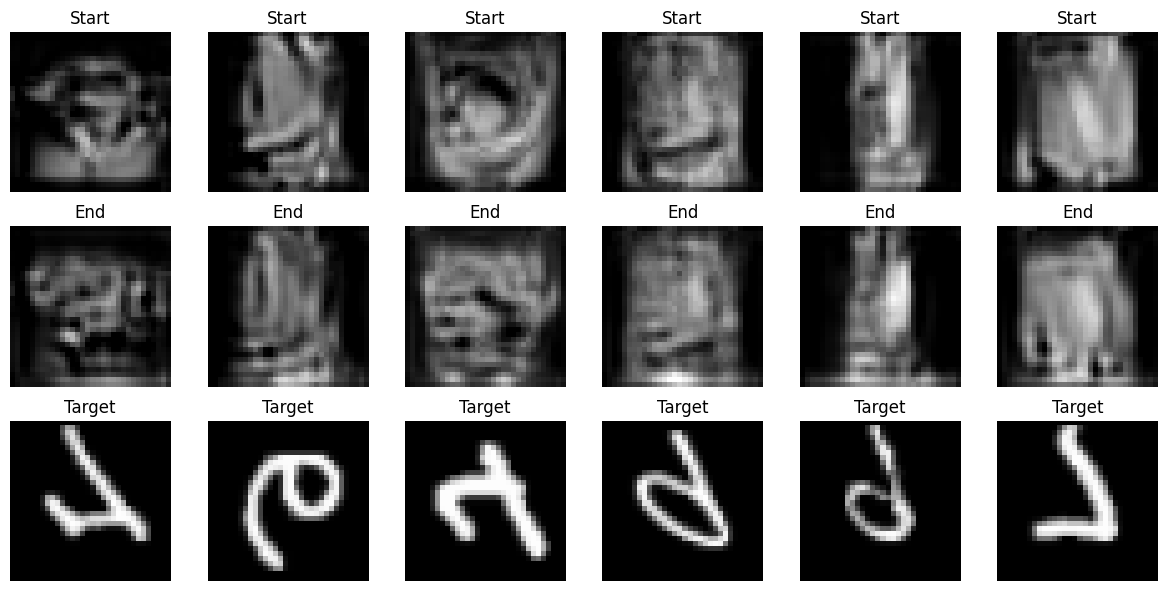

Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.34it/s]


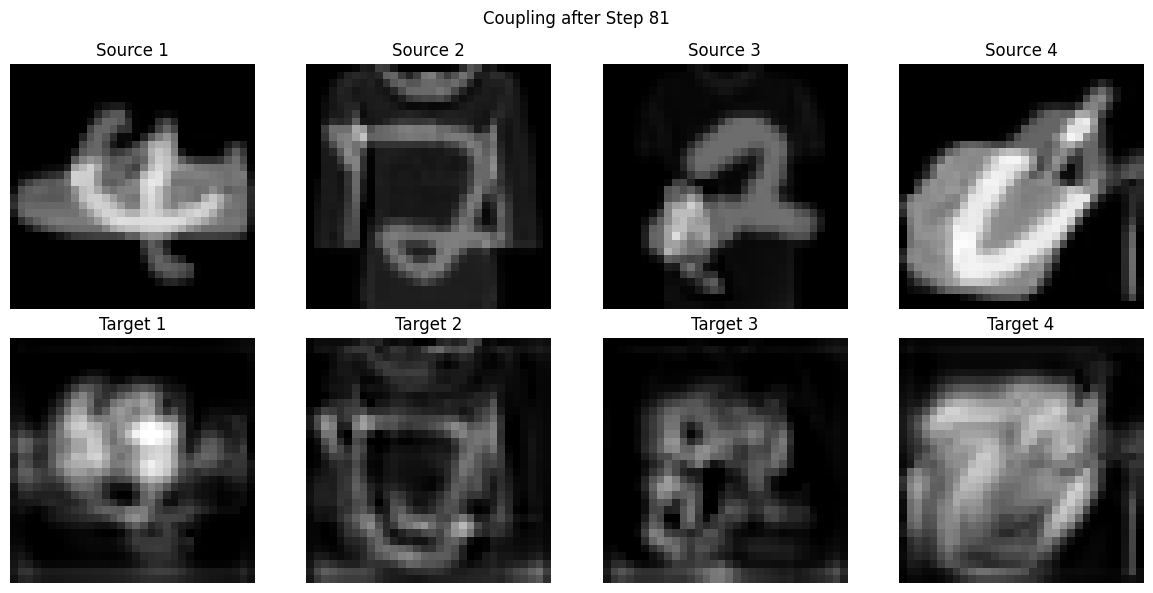

Iteration 82/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.33it/s]


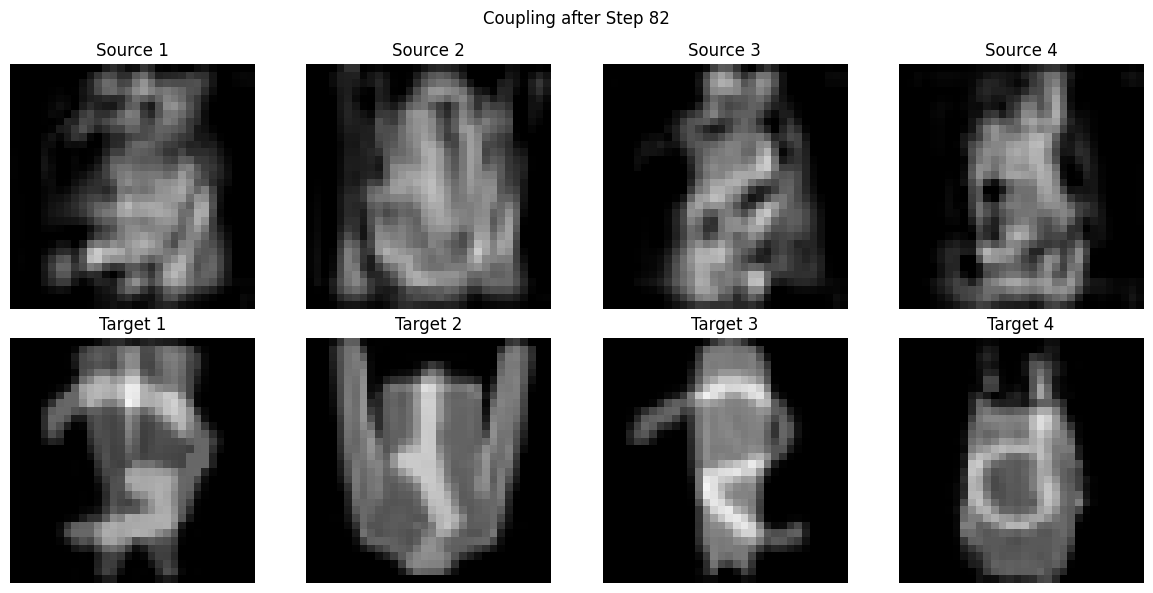

Iteration 83/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.32it/s]


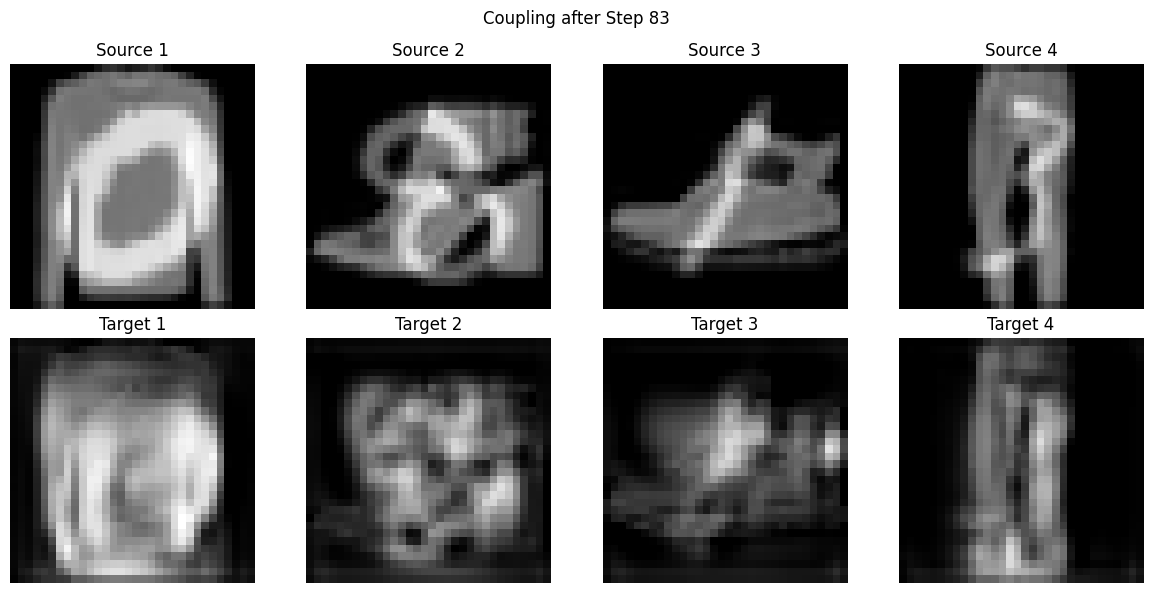

Iteration 84/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.34it/s]


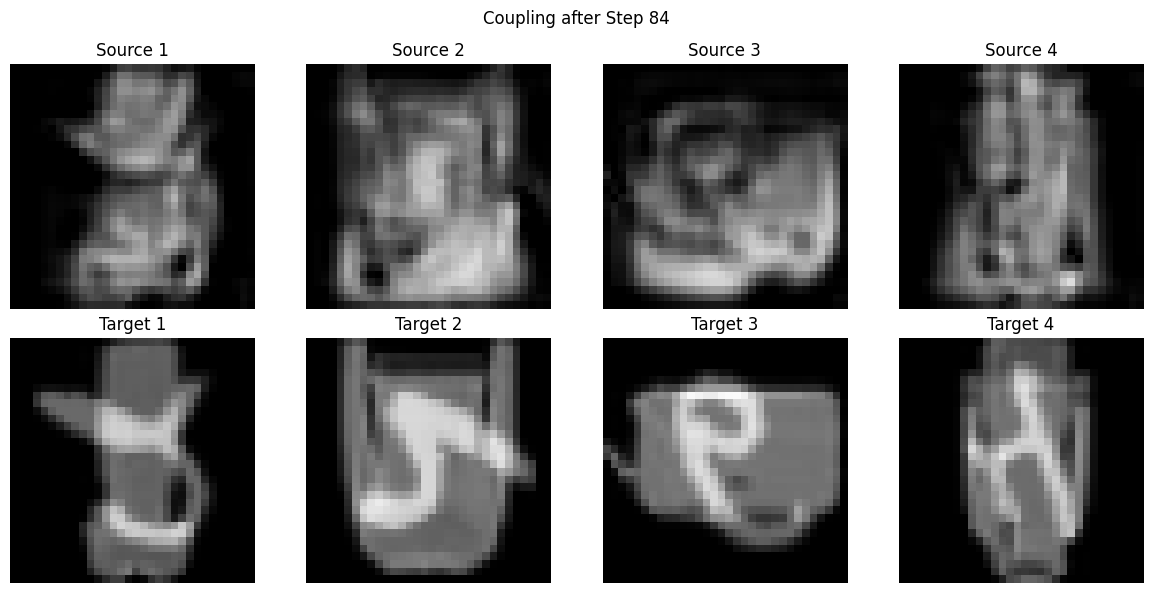

Iteration 85/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.34it/s]


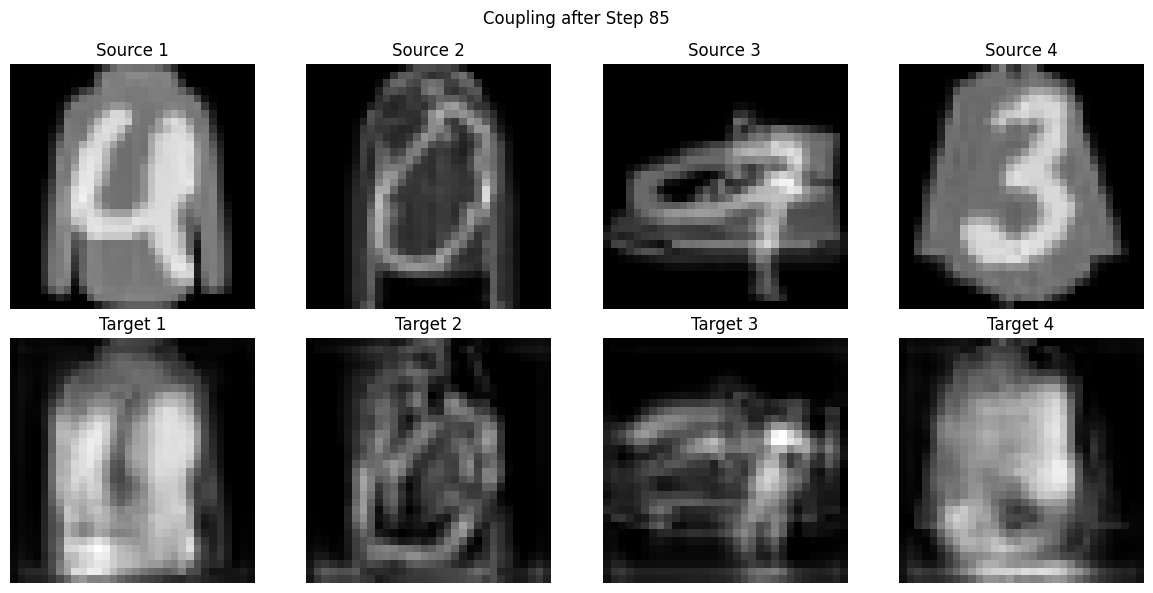

Iteration 86/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.34it/s]


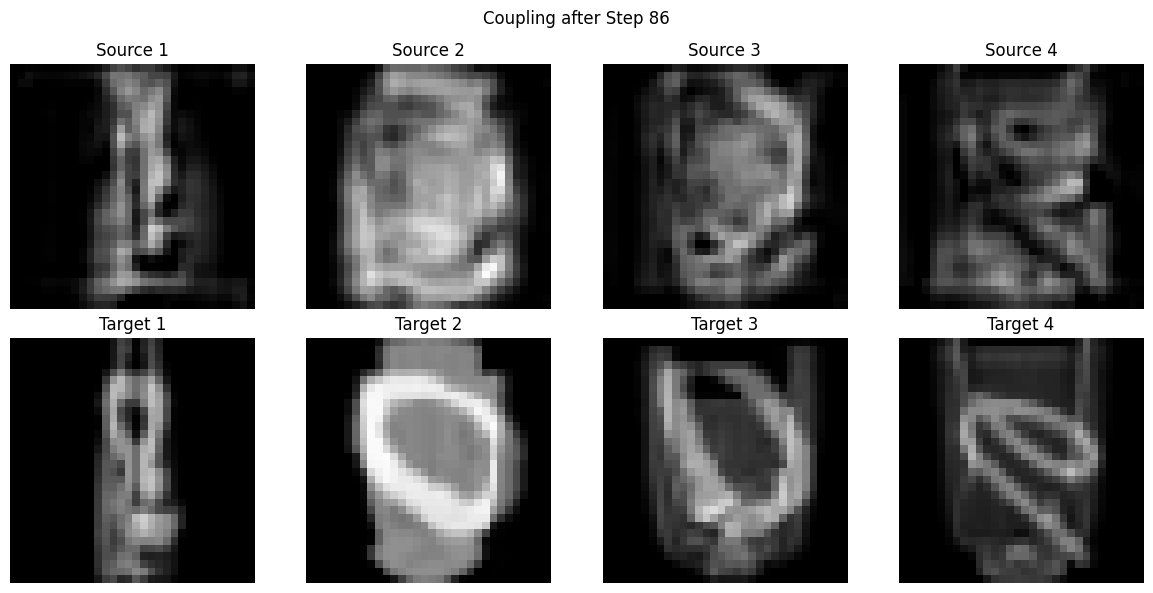

Iteration 87/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.34it/s]


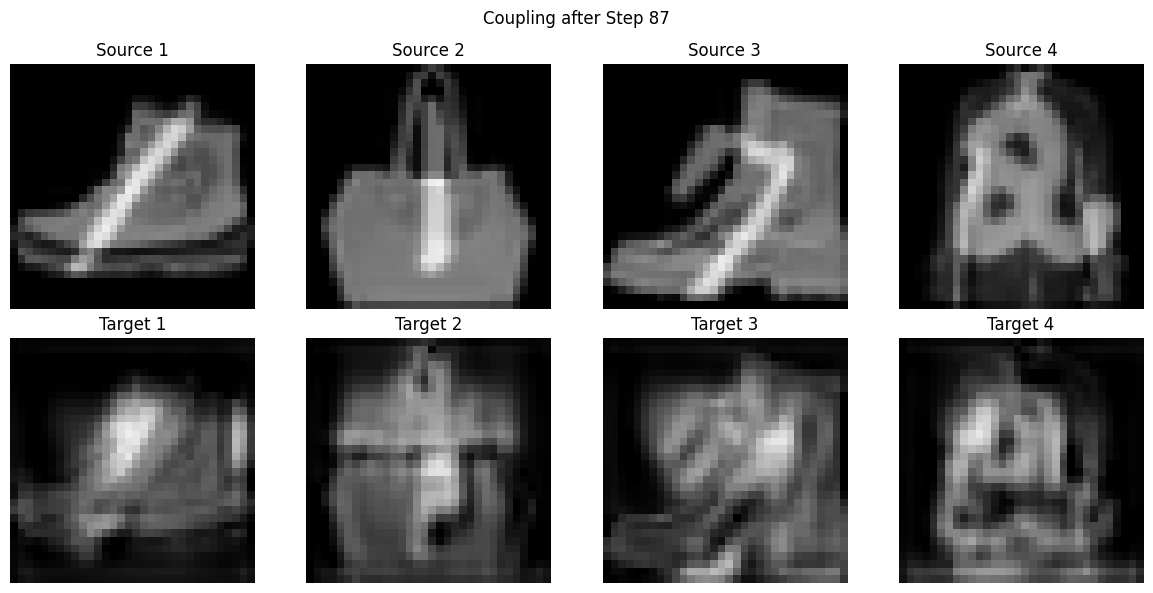

Iteration 88/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.33it/s]


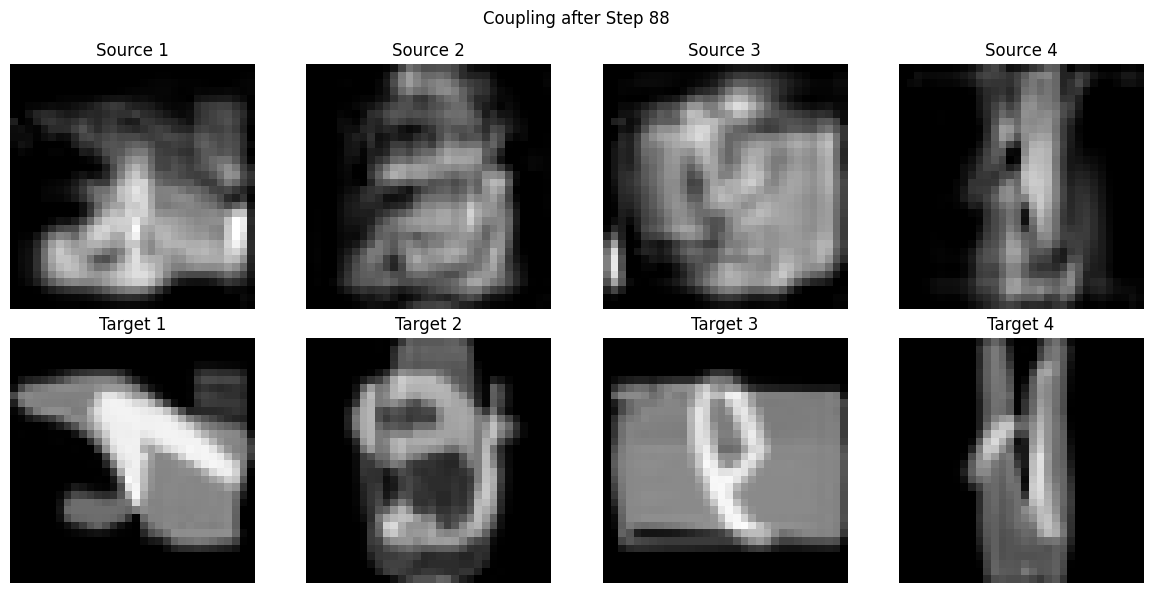

Iteration 89/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.34it/s]


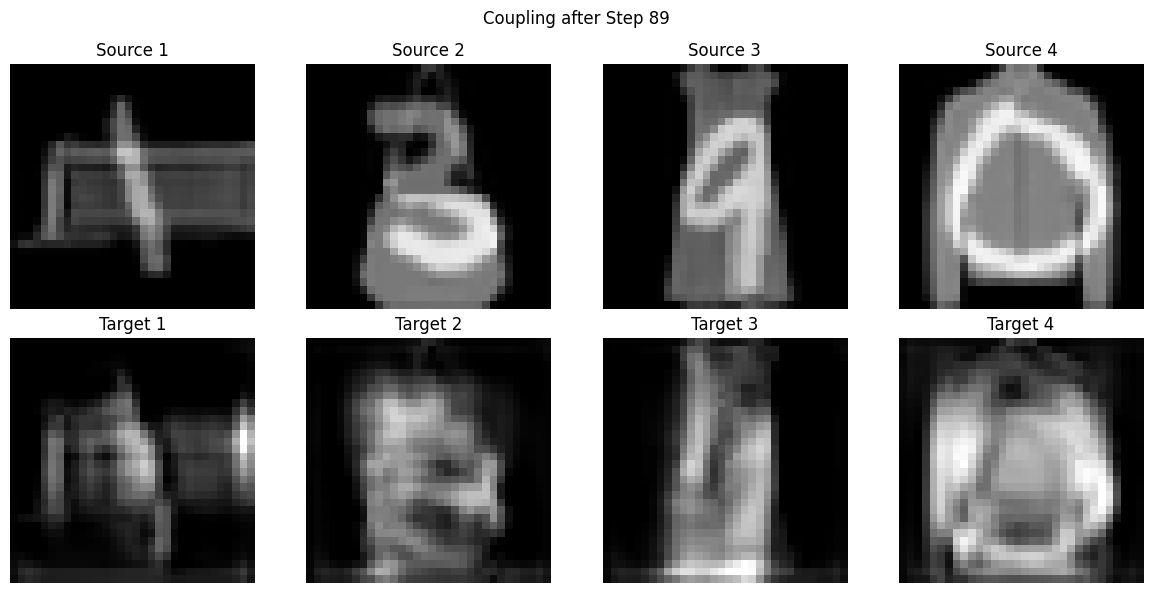

Iteration 90/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.34it/s]


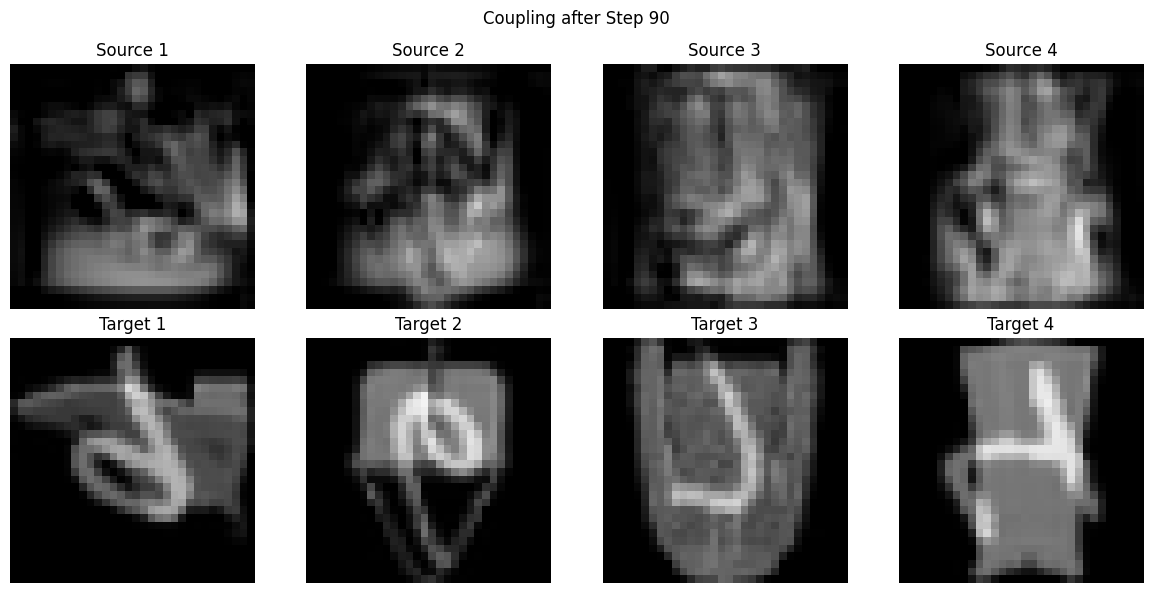

Iteration 91/200


CFM Training: 100%|██████████| 5/5 [00:01<00:00,  4.95it/s, CFM Loss=3.05e-9]


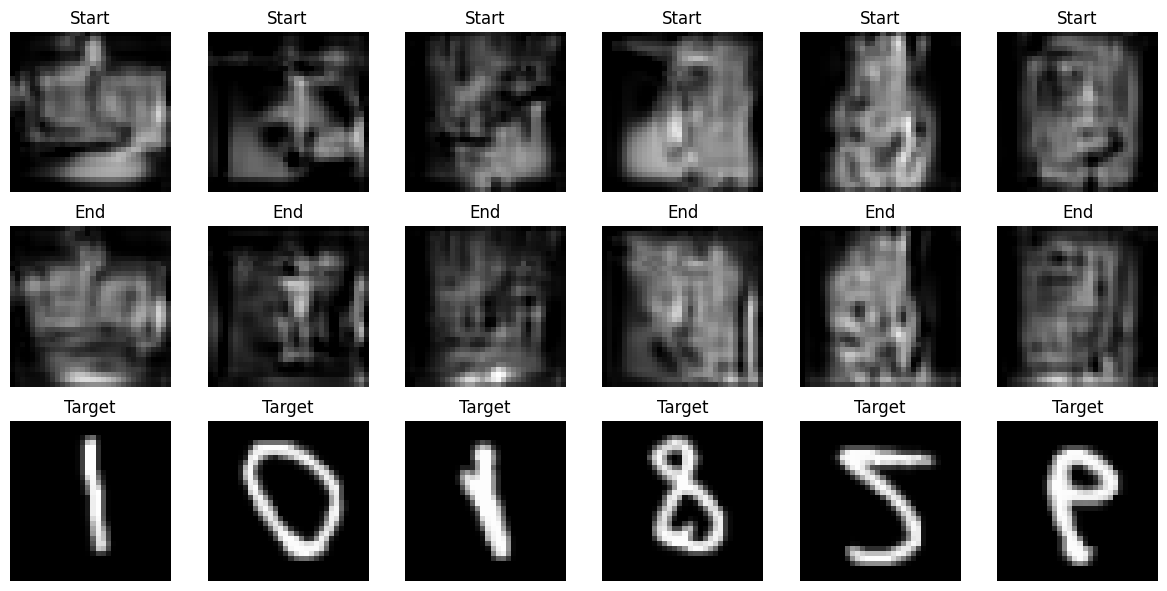

Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.30it/s]


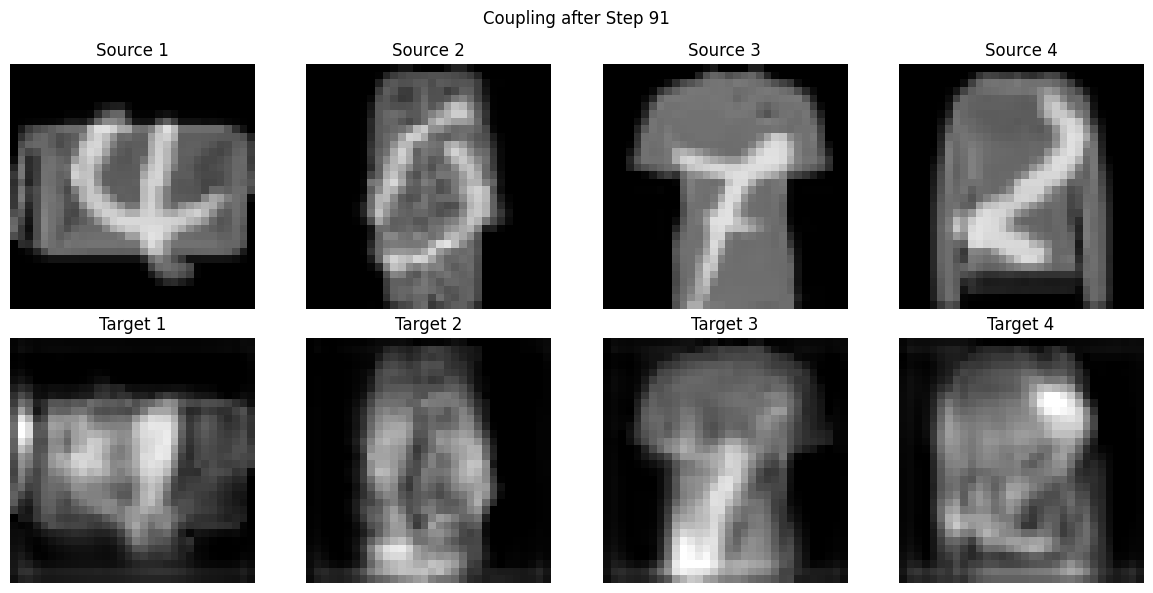

Iteration 92/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.30it/s]


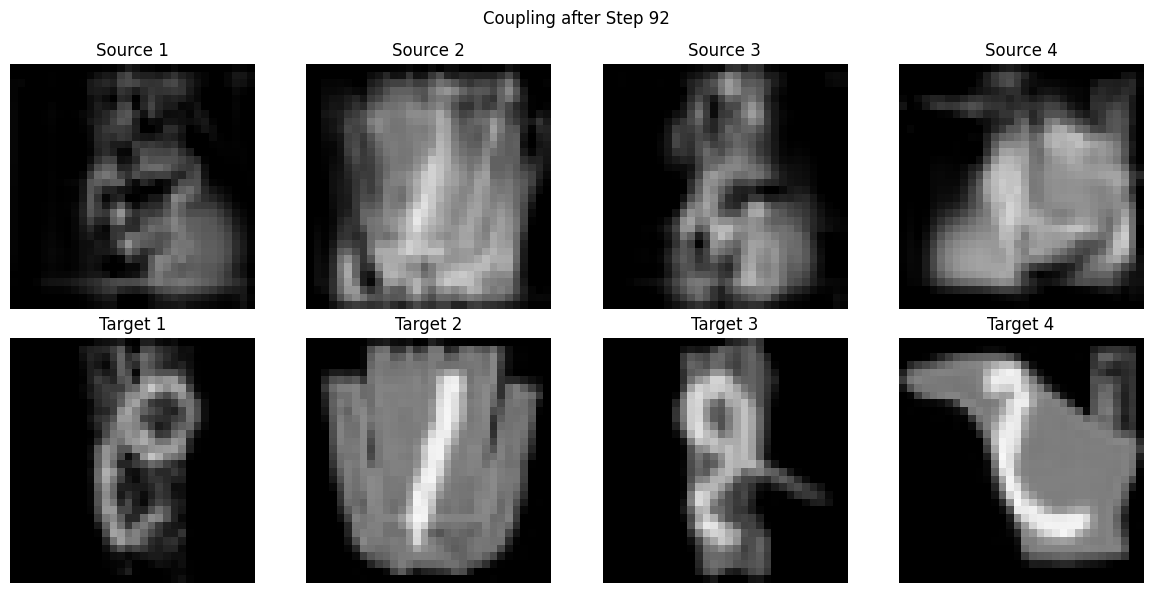

Iteration 93/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.31it/s]


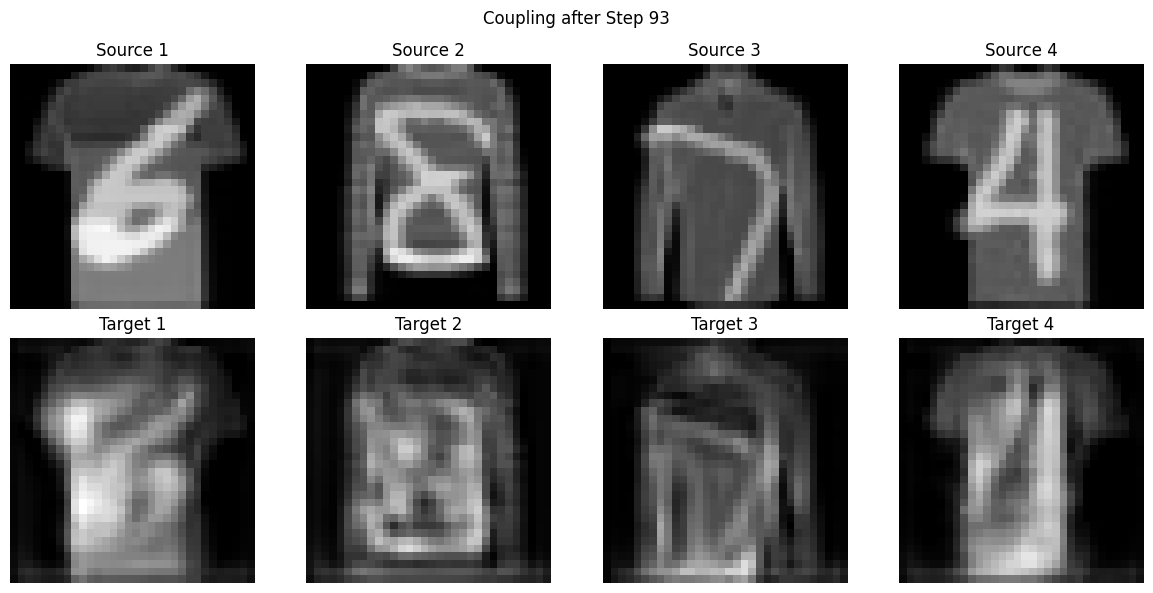

Iteration 94/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.02it/s]


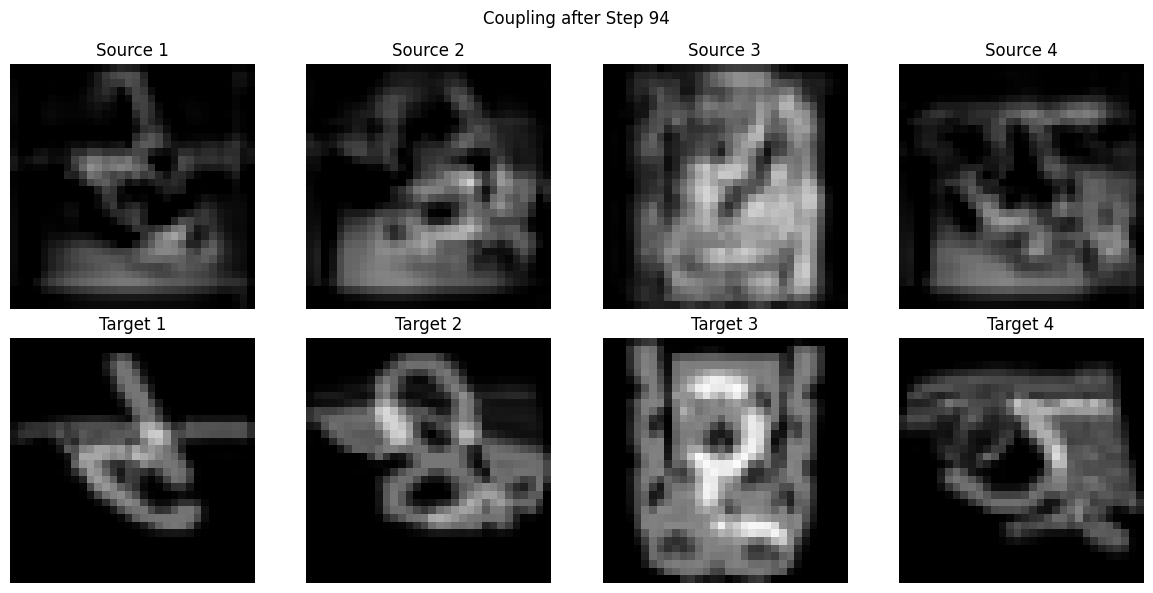

Iteration 95/200


Advancing coupling: 100%|██████████| 8/8 [00:04<00:00,  1.82it/s]


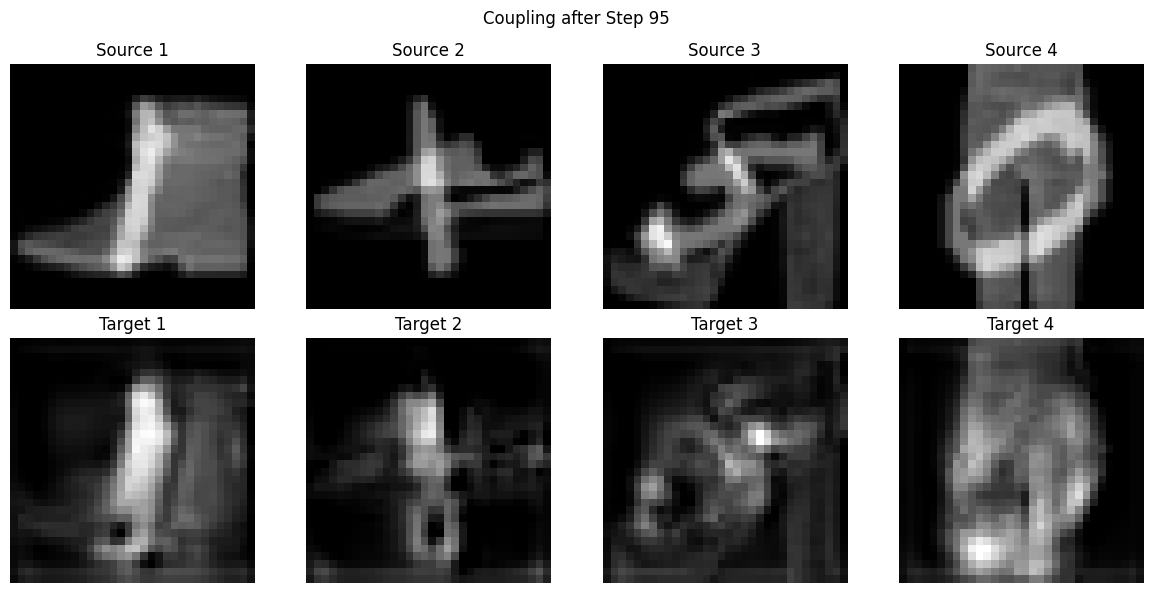

Iteration 96/200


Advancing coupling: 100%|██████████| 8/8 [00:04<00:00,  1.82it/s]


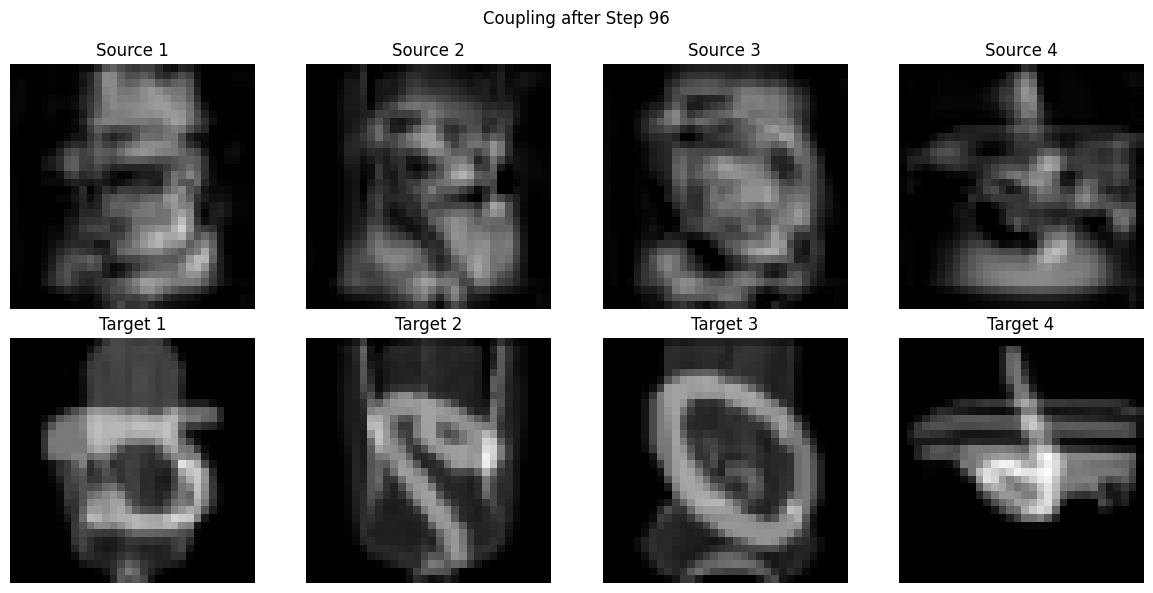

Iteration 97/200


Advancing coupling: 100%|██████████| 8/8 [00:04<00:00,  1.91it/s]


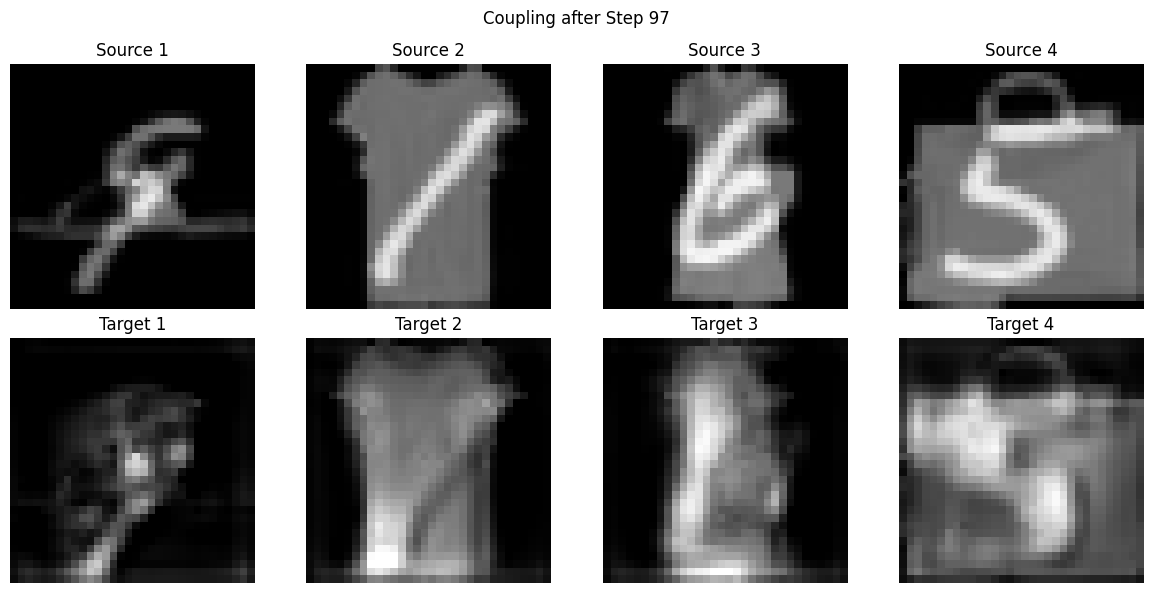

Iteration 98/200


Advancing coupling: 100%|██████████| 8/8 [00:03<00:00,  2.06it/s]


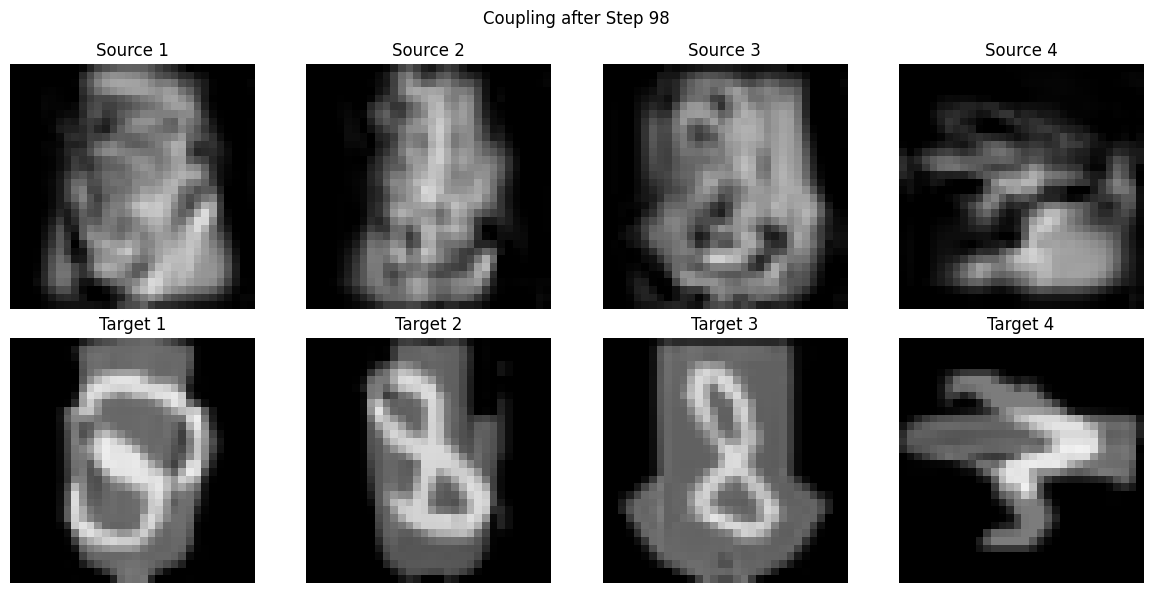

Iteration 99/200


Advancing coupling: 100%|██████████| 8/8 [00:04<00:00,  1.82it/s]


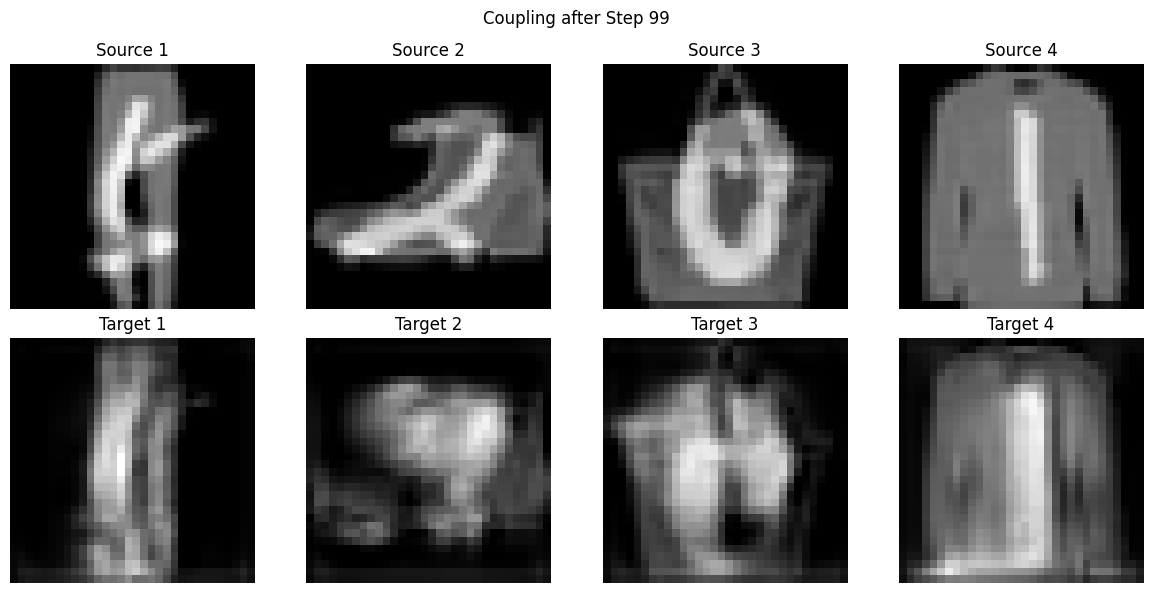

Iteration 100/200


Advancing coupling: 100%|██████████| 8/8 [00:04<00:00,  1.81it/s]


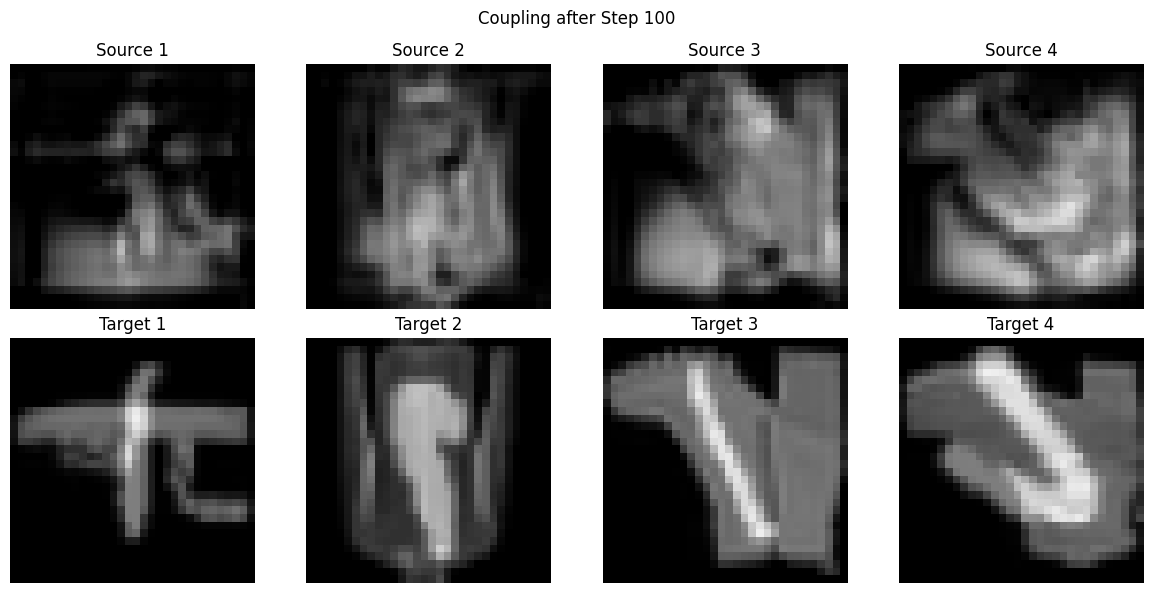

Iteration 101/200


CFM Training: 100%|██████████| 5/5 [00:01<00:00,  3.82it/s, CFM Loss=3.09e-9]


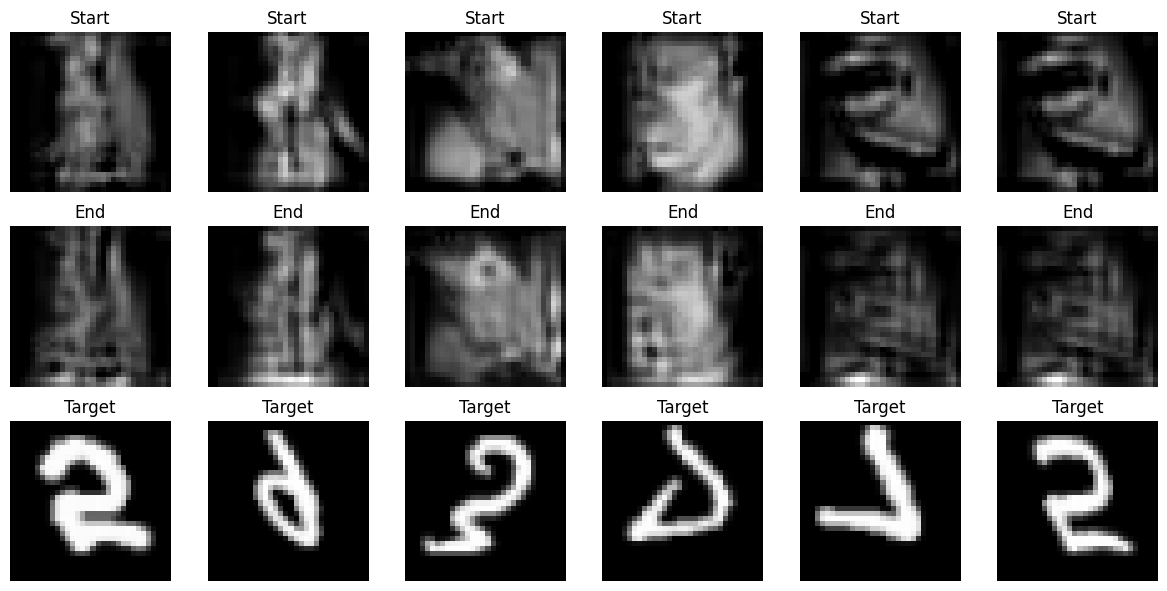

Advancing coupling:  25%|██▌       | 2/8 [00:01<00:03,  1.80it/s]


KeyboardInterrupt: 

In [ ]:
trainer.train(retrain=True, save='experiments/image_flip_models/')

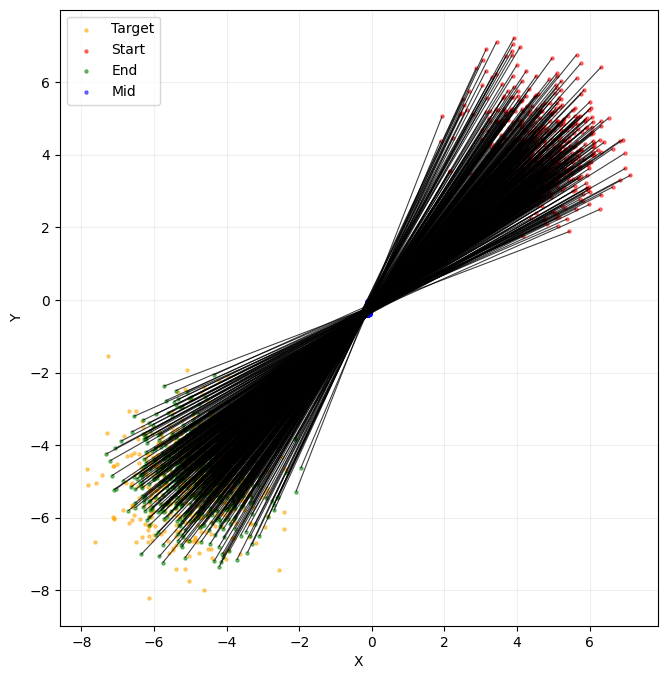

In [ ]:
import matplotlib.pyplot as plt
trainer.visualizer.display(10, trainer)
plt.show()

trainer.visualizer.display(11, trainer)
plt.show()